# R75 data testing

Shape: (256, 128)


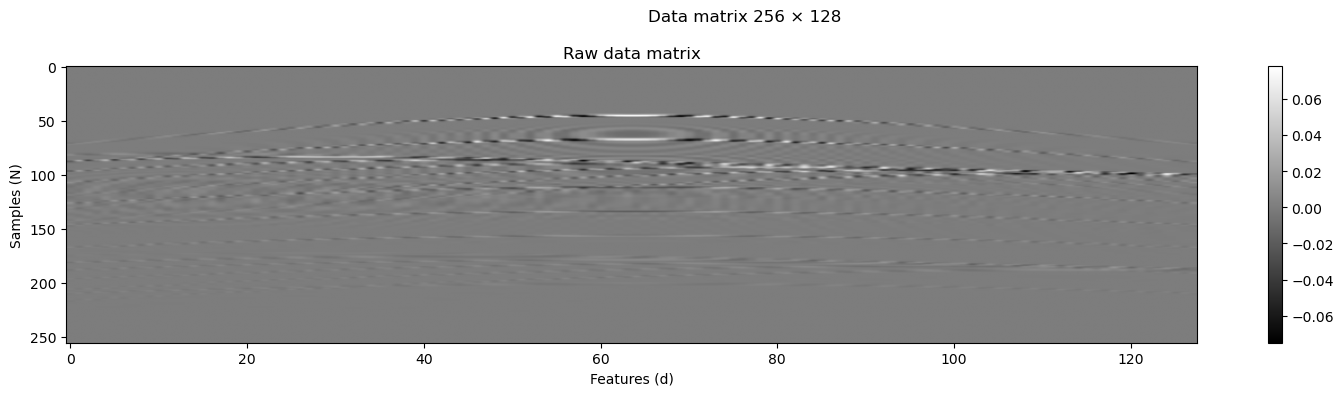

In [1]:
import pandas as pd
import torch
import matplotlib.pyplot as plt
import numpy as np
from skimage.transform import resize

# Load
df = pd.read_excel("R75 Ultrasound data.xlsx", header=None)
# Resize
Y_np = resize(df.to_numpy(), (256, 128), anti_aliasing=True)
Y=Y_np
Y /=np.linalg.norm(Y)

print(f"Shape: {Y.shape}")

# Plot
fig, ax = plt.subplots(figsize=(15, 4))

im = ax.imshow(Y, aspect='auto', cmap='gray')
ax.set_title("Raw data matrix")
ax.set_xlabel("Features (d)")
ax.set_ylabel("Samples (N)")

plt.colorbar(im, ax=ax)

plt.suptitle(f"Data matrix {Y.shape[0]} × {Y.shape[1]}", fontsize=12)

plt.tight_layout()
plt.show()

## One sigle row

In [38]:
Y.T[60].shape

(256,)

In [39]:
n = 8
full_sv = Y.T[60]
full_sv = full_sv / np.linalg.norm(full_sv)
exact_mps = dense_to_exact_mps(full_sv, n)
final_ref = exact_mps.copy()
approx_mps = exact_to_approx_mps(exact_mps)

print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

circs = layers_funct(exact_mps, n, L=30)
rebuilt = rebuildfunc(circs, n)
print(f"Multi-layer rebuilt fidelity:  {abs((rebuilt | final_ref).contract()):.4f}")

Single-layer approx fidelity: 0.7510
  layer 1: approx fidelity = 0.7510
  layer 2: approx fidelity = 0.8211
  layer 3: approx fidelity = 0.8599
  layer 4: approx fidelity = 0.8827
  layer 5: approx fidelity = 0.8953
  layer 6: approx fidelity = 0.9144
  layer 7: approx fidelity = 0.9224
  layer 8: approx fidelity = 0.9331
  layer 9: approx fidelity = 0.9430
  layer 10: approx fidelity = 0.9506
  layer 11: approx fidelity = 0.9570
  layer 12: approx fidelity = 0.9614


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


  layer 13: approx fidelity = 0.9647
  layer 14: approx fidelity = 0.9698
  layer 15: approx fidelity = 0.9727
  layer 16: approx fidelity = 0.9763
  layer 17: approx fidelity = 0.9794
  layer 18: approx fidelity = 0.9821
  layer 19: approx fidelity = 0.9841
  layer 20: approx fidelity = 0.9859
  layer 21: approx fidelity = 0.9874
  layer 22: approx fidelity = 0.9888
  layer 23: approx fidelity = 0.9904
  layer 24: approx fidelity = 0.9913
  layer 25: approx fidelity = 0.9921
  layer 26: approx fidelity = 0.9930
  layer 27: approx fidelity = 0.9938
  layer 28: approx fidelity = 0.9944
  layer 29: approx fidelity = 0.9951
  layer 30: approx fidelity = 0.9959
Multi-layer rebuilt fidelity:  0.9959


## All rows together

Single-layer approx fidelity: 0.7636
  layer 1: approx fidelity = 0.7636
  layer 2: approx fidelity = 0.8752
  layer 3: approx fidelity = 0.8986
  layer 4: approx fidelity = 0.9258
  layer 5: approx fidelity = 0.9362


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


  layer 6: approx fidelity = 0.9429
  layer 7: approx fidelity = 0.9465
  layer 8: approx fidelity = 0.9511
  layer 9: approx fidelity = 0.9566
  layer 10: approx fidelity = 0.9607
  layer 11: approx fidelity = 0.9652
  layer 12: approx fidelity = 0.9687
  layer 13: approx fidelity = 0.9719
  layer 14: approx fidelity = 0.9750
  layer 15: approx fidelity = 0.9776
  layer 16: approx fidelity = 0.9800
  layer 17: approx fidelity = 0.9822
  layer 18: approx fidelity = 0.9840
  layer 19: approx fidelity = 0.9857
  layer 20: approx fidelity = 0.9872
  layer 21: approx fidelity = 0.9887
  layer 22: approx fidelity = 0.9897
  layer 23: approx fidelity = 0.9906
  layer 24: approx fidelity = 0.9914
  layer 25: approx fidelity = 0.9922
  layer 26: approx fidelity = 0.9930
  layer 27: approx fidelity = 0.9938
  layer 28: approx fidelity = 0.9944
  layer 29: approx fidelity = 0.9948
  layer 30: approx fidelity = 0.9954
  layer 31: approx fidelity = 0.9961
  layer 32: approx fidelity = 0.9966
  lay

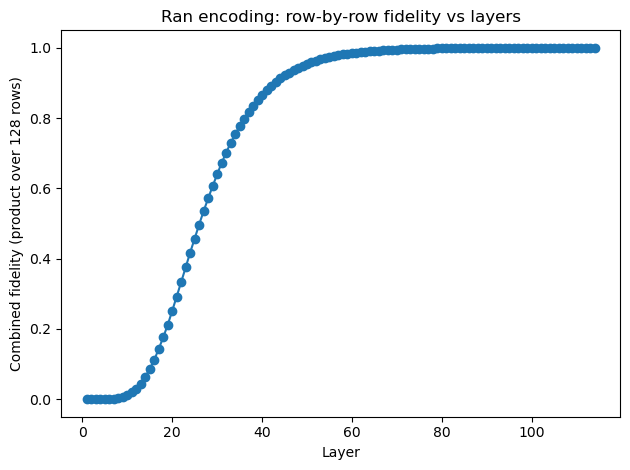

In [8]:
n = 8
L=150
register_fids=[]
for i in range(0,128):
    full_sv = Y.T[i]
    full_sv = full_sv / np.linalg.norm(full_sv)
    exact_mps = dense_to_exact_mps(full_sv, n)
    final_ref = exact_mps.copy()
    approx_mps = exact_to_approx_mps(exact_mps)

    print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

    circs, register_layer_fids = layers_funct(exact_mps, n, L=L)
    register_fids.append(register_layer_fids)
max_layers = max(len(f) for f in register_fids)

# Pad each row's fidelities to max_layers (converged rows stay at last value)
padded = [f + [f[-1]] * (max_layers - len(f)) for f in register_fids]

# Product across all 128 rows at each layer
combined_fids = [1.0] * max_layers
for row_fids in padded:
    for l in range(max_layers):
        combined_fids[l] *= row_fids[l]

print(f"Final combined fidelity (all layers): {combined_fids[-1]:.6f}")
combined_fids_M128=combined_fids
plt.plot(range(1, max_layers + 1), combined_fids, marker='o')
plt.xlabel('Layer')
plt.ylabel('Combined fidelity (product over 128 rows)')
plt.title(f'Ran encoding: row-by-row fidelity vs layers')
plt.tight_layout()
plt.show()

## Grouping rows in pairs (M=64,32,16,8)

Single-layer approx fidelity: 0.6719
  layer 1: approx fidelity = 0.6719
  layer 2: approx fidelity = 0.7537
  layer 3: approx fidelity = 0.7824
  layer 4: approx fidelity = 0.8011
  layer 5: approx fidelity = 0.8201
  layer 6: approx fidelity = 0.8389
  layer 7: approx fidelity = 0.8503


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


  layer 8: approx fidelity = 0.8622
  layer 9: approx fidelity = 0.8726
  layer 10: approx fidelity = 0.8836
  layer 11: approx fidelity = 0.8928
  layer 12: approx fidelity = 0.9006
  layer 13: approx fidelity = 0.9059
  layer 14: approx fidelity = 0.9127
  layer 15: approx fidelity = 0.9193
  layer 16: approx fidelity = 0.9251
  layer 17: approx fidelity = 0.9309
  layer 18: approx fidelity = 0.9351
  layer 19: approx fidelity = 0.9389
  layer 20: approx fidelity = 0.9416
  layer 21: approx fidelity = 0.9446
  layer 22: approx fidelity = 0.9492
  layer 23: approx fidelity = 0.9532
  layer 24: approx fidelity = 0.9553
  layer 25: approx fidelity = 0.9583
  layer 26: approx fidelity = 0.9600
  layer 27: approx fidelity = 0.9624
  layer 28: approx fidelity = 0.9648
  layer 29: approx fidelity = 0.9674
  layer 30: approx fidelity = 0.9693
  layer 31: approx fidelity = 0.9708
  layer 32: approx fidelity = 0.9730
  layer 33: approx fidelity = 0.9750
  layer 34: approx fidelity = 0.9766
  l

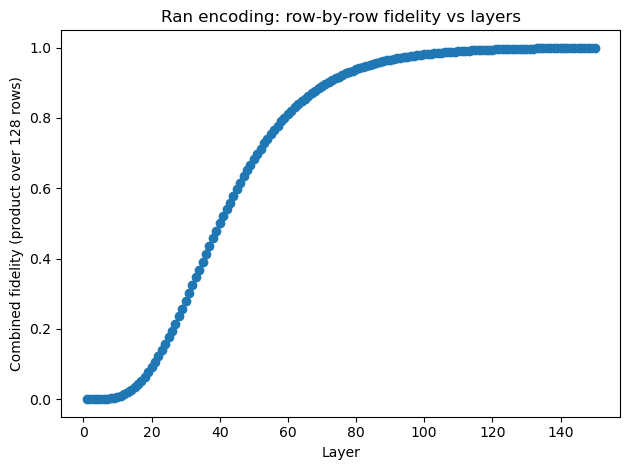

In [ ]:
#Make sure to change n here as different groupings need different number of qubits on registers
#M=64
n = 9
L=150
register_fids=[]
g= 2 #group size
for i in range(0,128,g):
    full_sv = np.concatenate([Y.T[i+j] for j in range(g)])
    full_sv = full_sv / np.linalg.norm(full_sv)
    exact_mps = dense_to_exact_mps(full_sv, n)
    final_ref = exact_mps.copy()
    approx_mps = exact_to_approx_mps(exact_mps)

    print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

    circs, register_layer_fids = layers_funct(exact_mps, n, L=L)
    register_fids.append(register_layer_fids)
max_layers = max(len(f) for f in register_fids)

# Pad each row's fidelities to max_layers (converged rows stay at last value)
padded = [f + [f[-1]] * (max_layers - len(f)) for f in register_fids]

# Product across all 128 rows at each layer
combined_fids = [1.0] * max_layers
for row_fids in padded:
    for l in range(max_layers):
        combined_fids[l] *= row_fids[l]

print(f"Final combined fidelity (all layers): {combined_fids[-1]:.6f}")
combined_fids_M64=combined_fids
plt.plot(range(1, max_layers + 1), combined_fids, marker='o')
plt.xlabel('Layer')
plt.ylabel('Combined fidelity (product over 128 rows)')
plt.title(f'Ran encoding: row-by-row fidelity vs layers')
plt.tight_layout()
plt.show()

Single-layer approx fidelity: 0.6327
  layer 1: approx fidelity = 0.6327
  layer 2: approx fidelity = 0.7238
  layer 3: approx fidelity = 0.7573
  layer 4: approx fidelity = 0.7820
  layer 5: approx fidelity = 0.8022


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


  layer 6: approx fidelity = 0.8162
  layer 7: approx fidelity = 0.8300
  layer 8: approx fidelity = 0.8379
  layer 9: approx fidelity = 0.8560
  layer 10: approx fidelity = 0.8617
  layer 11: approx fidelity = 0.8687
  layer 12: approx fidelity = 0.8772
  layer 13: approx fidelity = 0.8859
  layer 14: approx fidelity = 0.8905
  layer 15: approx fidelity = 0.8975
  layer 16: approx fidelity = 0.9023
  layer 17: approx fidelity = 0.9063
  layer 18: approx fidelity = 0.9136
  layer 19: approx fidelity = 0.9194
  layer 20: approx fidelity = 0.9244
  layer 21: approx fidelity = 0.9285
  layer 22: approx fidelity = 0.9327
  layer 23: approx fidelity = 0.9371
  layer 24: approx fidelity = 0.9409
  layer 25: approx fidelity = 0.9436
  layer 26: approx fidelity = 0.9460
  layer 27: approx fidelity = 0.9493
  layer 28: approx fidelity = 0.9511
  layer 29: approx fidelity = 0.9536
  layer 30: approx fidelity = 0.9563
  layer 31: approx fidelity = 0.9596
  layer 32: approx fidelity = 0.9610
  lay

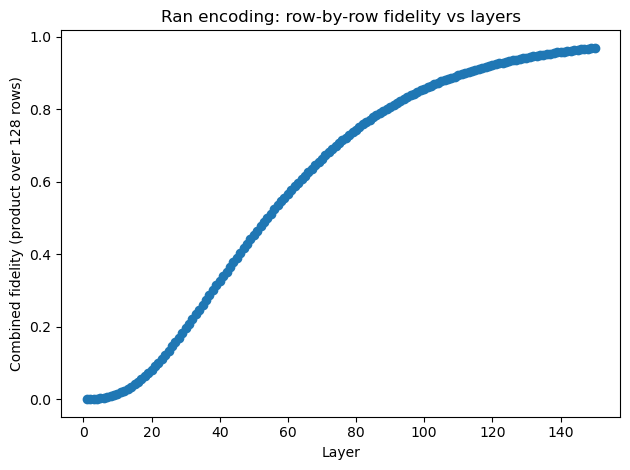

In [ ]:
#Make sure to change n here as different groupings need different number of qubits on registers
#M=32
n = 10
L=150
register_fids=[]
g= 4 #group size
for i in range(0,128,g):
    full_sv = np.concatenate([Y.T[i+j] for j in range(g)])
    full_sv = full_sv / np.linalg.norm(full_sv)
    exact_mps = dense_to_exact_mps(full_sv, n)
    final_ref = exact_mps.copy()
    approx_mps = exact_to_approx_mps(exact_mps)

    print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

    circs, register_layer_fids = layers_funct(exact_mps, n, L=L)
    register_fids.append(register_layer_fids)
max_layers = max(len(f) for f in register_fids)

# Pad each row's fidelities to max_layers (converged rows stay at last value)
padded = [f + [f[-1]] * (max_layers - len(f)) for f in register_fids]

# Product across all 128 rows at each layer
combined_fids = [1.0] * max_layers
for row_fids in padded:
    for l in range(max_layers):
        combined_fids[l] *= row_fids[l]

print(f"Final combined fidelity (all layers): {combined_fids[-1]:.6f}")
combined_fids_M32=combined_fids
plt.plot(range(1, max_layers + 1), combined_fids, marker='o')
plt.xlabel('Layer')
plt.ylabel('Combined fidelity (product over 128 rows)')
plt.title(f'Ran encoding: row-by-row fidelity vs layers')
plt.tight_layout()
plt.show()

Single-layer approx fidelity: 0.5989
  layer 1: approx fidelity = 0.5989
  layer 2: approx fidelity = 0.6515
  layer 3: approx fidelity = 0.6895
  layer 4: approx fidelity = 0.7157
  layer 5: approx fidelity = 0.7312
  layer 6: approx fidelity = 0.7500
  layer 7: approx fidelity = 0.7630
  layer 8: approx fidelity = 0.7761
  layer 9: approx fidelity = 0.7854
  layer 10: approx fidelity = 0.7946
  layer 11: approx fidelity = 0.8049
  layer 12: approx fidelity = 0.8117
  layer 13: approx fidelity = 0.8175
  layer 14: approx fidelity = 0.8252
  layer 15: approx fidelity = 0.8364
  layer 16: approx fidelity = 0.8467
  layer 17: approx fidelity = 0.8531
  layer 18: approx fidelity = 0.8598
  layer 19: approx fidelity = 0.8658
  layer 20: approx fidelity = 0.8708
  layer 21: approx fidelity = 0.8752
  layer 22: approx fidelity = 0.8791
  layer 23: approx fidelity = 0.8818
  layer 24: approx fidelity = 0.8838
  layer 25: approx fidelity = 0.8902
  layer 26: approx fidelity = 0.8928
  layer 27

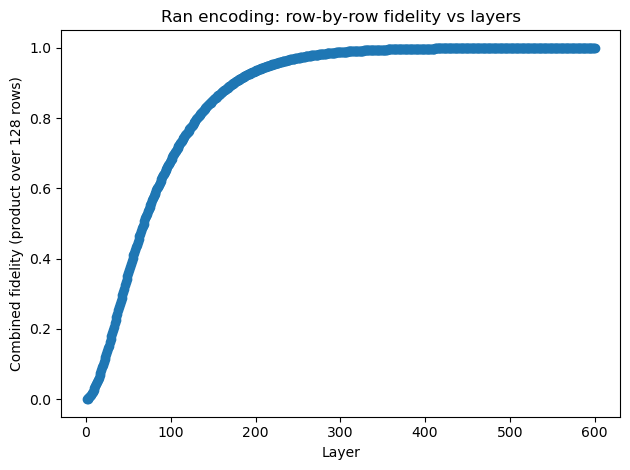

In [24]:
#Make sure to change n here as different groupings need different number of qubits on registers
#M=16
n = 11
L=600
register_fids=[]
g= 8 #group size
for i in range(0,128,g):
    full_sv = np.concatenate([Y.T[i+j] for j in range(g)])
    full_sv = full_sv / np.linalg.norm(full_sv)
    exact_mps = dense_to_exact_mps(full_sv, n)
    final_ref = exact_mps.copy()
    approx_mps = exact_to_approx_mps(exact_mps)

    print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

    circs, register_layer_fids = layers_funct(exact_mps, n, L=L)
    register_fids.append(register_layer_fids)
max_layers = max(len(f) for f in register_fids)

# Pad each row's fidelities to max_layers (converged rows stay at last value)
padded = [f + [f[-1]] * (max_layers - len(f)) for f in register_fids]

# Product across all 128 rows at each layer
combined_fids = [1.0] * max_layers
for row_fids in padded:
    for l in range(max_layers):
        combined_fids[l] *= row_fids[l]

print(f"Final combined fidelity (all layers): {combined_fids[-1]:.6f}")
combined_fids_M16=combined_fids
plt.plot(range(1, max_layers + 1), combined_fids, marker='o')
plt.xlabel('Layer')
plt.ylabel('Combined fidelity (product over 128 rows)')
plt.title(f'Ran encoding: row-by-row fidelity vs layers')
plt.tight_layout()
plt.show()

Single-layer approx fidelity: 0.4864
  layer 1: approx fidelity = 0.4864
  layer 2: approx fidelity = 0.5490
  layer 3: approx fidelity = 0.5864
  layer 4: approx fidelity = 0.6116
  layer 5: approx fidelity = 0.6268
  layer 6: approx fidelity = 0.6545
  layer 7: approx fidelity = 0.6677
  layer 8: approx fidelity = 0.6790
  layer 9: approx fidelity = 0.6931
  layer 10: approx fidelity = 0.7054
  layer 11: approx fidelity = 0.7140
  layer 12: approx fidelity = 0.7236
  layer 13: approx fidelity = 0.7347
  layer 14: approx fidelity = 0.7475
  layer 15: approx fidelity = 0.7533
  layer 16: approx fidelity = 0.7588
  layer 17: approx fidelity = 0.7656
  layer 18: approx fidelity = 0.7721
  layer 19: approx fidelity = 0.7787
  layer 20: approx fidelity = 0.7860
  layer 21: approx fidelity = 0.7929
  layer 22: approx fidelity = 0.7966
  layer 23: approx fidelity = 0.8005
  layer 24: approx fidelity = 0.8070
  layer 25: approx fidelity = 0.8118
  layer 26: approx fidelity = 0.8152
  layer 27

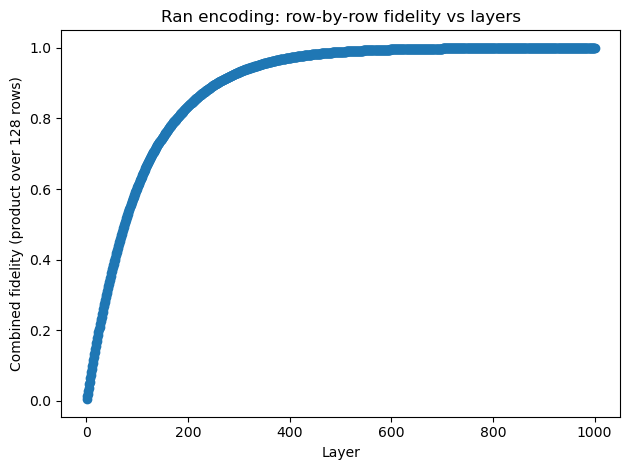

In [20]:
#Make sure to change n here as different groupings need different number of qubits on registers
#M=8
n = 12
L=1000
register_fids=[]
g= 16 #group size
for i in range(0,128,g):
    full_sv = np.concatenate([Y.T[i+j] for j in range(g)])
    full_sv = full_sv / np.linalg.norm(full_sv)
    exact_mps = dense_to_exact_mps(full_sv, n)
    final_ref = exact_mps.copy()
    approx_mps = exact_to_approx_mps(exact_mps)

    print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

    circs, register_layer_fids = layers_funct(exact_mps, n, L=L)
    register_fids.append(register_layer_fids)
max_layers = max(len(f) for f in register_fids)

# Pad each row's fidelities to max_layers (converged rows stay at last value)
padded = [f + [f[-1]] * (max_layers - len(f)) for f in register_fids]

# Product across all 128 rows at each layer
combined_fids = [1.0] * max_layers
for row_fids in padded:
    for l in range(max_layers):
        combined_fids[l] *= row_fids[l]

print(f"Final combined fidelity (all layers): {combined_fids[-1]:.6f}")
combined_fids_M8=combined_fids
plt.plot(range(1, max_layers + 1), combined_fids, marker='o')
plt.xlabel('Layer')
plt.ylabel('Combined fidelity (product over 128 rows)')
plt.title(f'Ran encoding: row-by-row fidelity vs layers')
plt.tight_layout()
plt.show()

## Full matrix

In [13]:
Y.T.flatten()

array([-1.18175533e-18, -1.96471333e-18, -1.90577618e-18, ...,
        6.57927727e-07,  9.05650643e-08,  7.84452701e-12], shape=(32768,))

In [14]:
n = 15
full_sv = Y.T.flatten()
full_sv = full_sv / np.linalg.norm(full_sv)
exact_mps = dense_to_exact_mps(full_sv, n)
final_ref = exact_mps.copy()
approx_mps = exact_to_approx_mps(exact_mps)

print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

circs,full_state_fids = layers_funct(exact_mps, n, L=1000)
rebuilt = rebuildfunc(circs, n)
print(f"Multi-layer rebuilt fidelity:  {abs((rebuilt | final_ref).contract()):.4f}")

Single-layer approx fidelity: 0.3176
  layer 1: approx fidelity = 0.3176
  layer 2: approx fidelity = 0.3409
  layer 3: approx fidelity = 0.3529
  layer 4: approx fidelity = 0.3686
  layer 5: approx fidelity = 0.3790
  layer 6: approx fidelity = 0.3862
  layer 7: approx fidelity = 0.3952
  layer 8: approx fidelity = 0.4007
  layer 9: approx fidelity = 0.4076
  layer 10: approx fidelity = 0.4182
  layer 11: approx fidelity = 0.4226
  layer 12: approx fidelity = 0.4273
  layer 13: approx fidelity = 0.4328
  layer 14: approx fidelity = 0.4385
  layer 15: approx fidelity = 0.4426
  layer 16: approx fidelity = 0.4501
  layer 17: approx fidelity = 0.4559
  layer 18: approx fidelity = 0.4593
  layer 19: approx fidelity = 0.4638
  layer 20: approx fidelity = 0.4678
  layer 21: approx fidelity = 0.4721
  layer 22: approx fidelity = 0.4764
  layer 23: approx fidelity = 0.4808
  layer 24: approx fidelity = 0.4836
  layer 25: approx fidelity = 0.4870
  layer 26: approx fidelity = 0.4908
  layer 27

## Graphs comparing the outputs.

In [ ]:
#Load in saved data
data = np.load('encoding_fids.npz')
combined_fids_M128 = data['M128']
combined_fids_M64  = data['M64']
combined_fids_M32  = data['M32']
combined_fids_M16  = data['M16']
combined_fids_M8   = data['M8']
full_state_fids    = data['full_state']


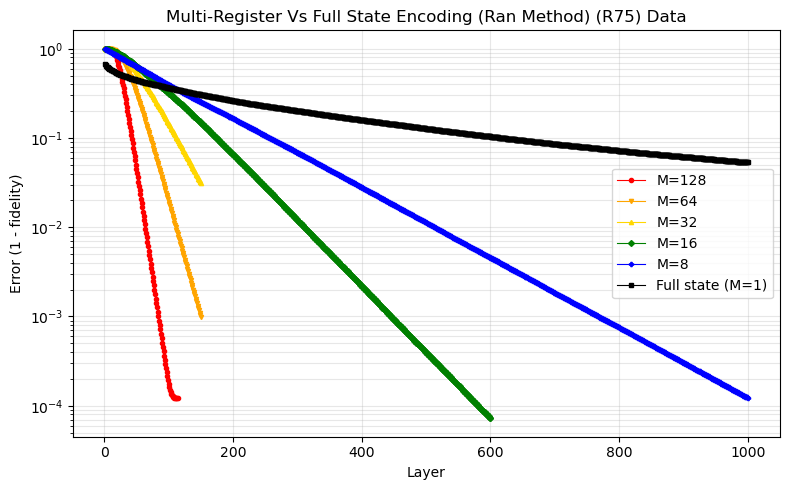

In [25]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

# Convert to error
combined_errs_M128 = 1 - np.array(combined_fids_M128)
combined_errs_M64 = 1 - np.array(combined_fids_M64)
combined_errs_M32 = 1 - np.array(combined_fids_M32)
combined_errs_M16 = 1 - np.array(combined_fids_M16)
combined_errs_M8 = 1 - np.array(combined_fids_M8)
full_state_errs = 1 - np.array(full_state_fids)

ax.plot(range(1, len(combined_errs_M128) + 1), combined_errs_M128,
        marker='o', color='red',    markersize=3, linewidth=0.8, label='M=128')
ax.plot(range(1, len(combined_errs_M64)  + 1), combined_errs_M64,
        marker='v', color='orange', markersize=3, linewidth=0.8, label='M=64')
ax.plot(range(1, len(combined_errs_M32)  + 1), combined_errs_M32,
        marker='^', color='gold',   markersize=3, linewidth=0.8, label='M=32')
ax.plot(range(1, len(combined_errs_M16)  + 1), combined_errs_M16,
        marker='D', color='green',  markersize=3, linewidth=0.8, label='M=16')
ax.plot(range(1, len(combined_errs_M8)   + 1), combined_errs_M8,
        marker='P', color='blue',   markersize=3, linewidth=0.8, label='M=8')
ax.plot(range(1, len(full_state_errs)    + 1), full_state_errs,
        marker='s', color='black',  markersize=3, linewidth=0.8, label='Full state (M=1)')



ax.set_yscale('log') 

ax.set_xlabel('Layer')
ax.set_ylabel('Error (1 - fidelity)')
ax.set_title('Multi-Register Vs Full State Encoding (Ran Method) (R75) Data')
ax.legend()
ax.grid(True, alpha=0.3, which='both')

plt.tight_layout()
plt.show()

In [26]:
#To save results!
np.savez('encoding_fids.npz',
         M128=combined_fids_M128,
         M64=combined_fids_M64,
         M32=combined_fids_M32,
         M16=combined_fids_M16,
         M8=combined_fids_M8,
         full_state=full_state_fids)


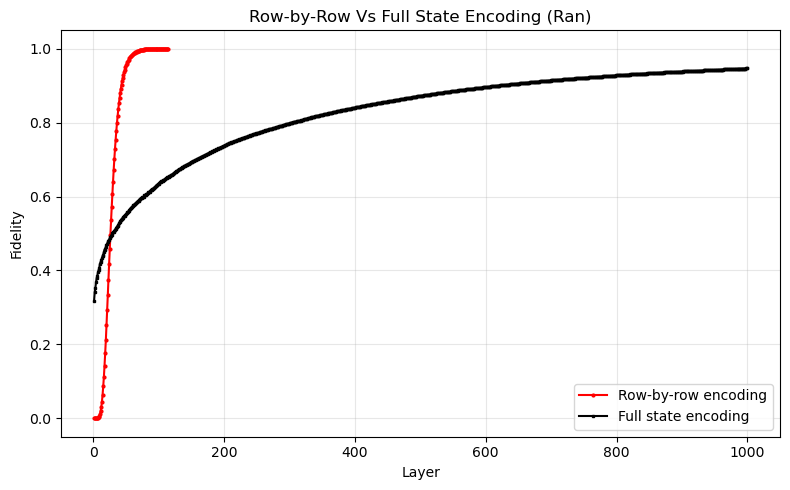

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(range(1, max_layers + 1), combined_fids,
        marker='o', color='red',  markersize=2,label='Row-by-row encoding')

ax.plot(range(1, len(full_state_fids) + 1), full_state_fids,
        marker='s', color='black',  markersize=2,label='Full state encoding')

ax.set_xlabel('Layer')
ax.set_ylabel('Fidelity')
ax.set_title('Multi-register Encoding Vs Full State Encoding (Ran) R75 Ultrasound data')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Same but with SSO (Josh Snow)

In [25]:
# =====================================================================
#  SSO framework -- full setup in one cell.
#  Paste into a single Jupyter cell and run once; defines everything the
#  encoding notebooks use (warm-start + cold SSO drivers, image<->MPS,
#  chi_fidelity, replay/reconstruction helpers).
#  Needs (phys env): numpy, torch, scipy, quimb, qiskit, mps_to_circuit.
#  Verbatim copy of `archie_test_ultrasound copy.ipynb` setup cells.
# =====================================================================

# --- Definition cell (from new.ipynb cell 2) ---
import numpy as np
import torch
import quimb as qu
import quimb.tensor as qtn
from quimb.tensor import PTensor
from functools import partial
import math

qtn.set_contract_strategy("auto-hq")

# complex128 everywhere so identity checks are numerically sharp
torch.set_default_dtype(torch.float64)
RNG = np.random.default_rng(0)
torch.manual_seed(0)

# --- Definition cell (from new.ipynb cell 4) ---
def su2_matrix(params: torch.Tensor) -> torch.Tensor:
    """3 real params -> SU(2) unitary, reshaped as a 2x2 tensor."""
    device = params.device
    dtype = torch.complex128
    sx = torch.tensor([[0, 1],  [1, 0]],   dtype=dtype, device=device)
    sy = torch.tensor([[0,-1j], [1j, 0]],  dtype=dtype, device=device)
    sz = torch.tensor([[1, 0],  [0,-1]],   dtype=dtype, device=device)
    Theta = params[0]*sx + params[1]*sy + params[2]*sz
    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2)


def su4_matrix(params: torch.Tensor) -> torch.Tensor:
    """15 real params -> SU(4) unitary, reshaped as a rank-4 tensor (2,2,2,2)."""
    N = 4
    device = params.device
    dtype = torch.complex128

    Theta = torch.zeros((N, N), dtype=dtype, device=device)

    # Diagonal generators (Cartan subalgebra)
    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0
        vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)

    # Off-diagonal generators (real-symmetric + imag-antisymmetric)
    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = mr[j, i] = 1.0
            mi[i, j] = 1.0j
            mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2

    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2, 2, 2)


def su8_matrix(params: torch.Tensor) -> torch.Tensor:
    """63 real params -> SU(8) unitary, reshaped as a rank-6 tensor (2,2,2,2,2,2)."""
    N = 8
    device = params.device
    dtype = torch.complex128

    Theta = torch.zeros((N, N), dtype=dtype, device=device)

    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0
        vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)

    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = mr[j, i] = 1.0
            mi[i, j] = 1.0j
            mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2

    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2, 2, 2, 2, 2)


# Sanity: zero params must give exact identity (this is what the original
# notebook paid a whole optimisation to approximate).
def _check_identity_from_zero():
    for nparams, fn, dim in [(3, su2_matrix, 2), (15, su4_matrix, 4), (63, su8_matrix, 8)]:
        M = fn(torch.zeros(nparams, dtype=torch.float64)).reshape(dim, dim)
        err = torch.linalg.norm(M - torch.eye(dim, dtype=torch.complex128)).item()
        assert err < 1e-12, f"{fn.__name__}(0) != I (err={err})"
    print("OK: su2_matrix(0) == I, su4_matrix(0) == I, su8_matrix(0) == I.")


_check_identity_from_zero()

# --- Definition cell (from new.ipynb cell 6) ---
def make_hybrid_staircase(n: int, eps: float = 0.0, seed: int | None = None) -> qtn.TensorNetwork:
    """
    Build the SU4 -> SU8 x (n-3) -> SU4 -> SU2 staircase for an n-qubit system.

    Parameters
    ----------
    n : int
        Number of qubits (>= 4 so that we have at least one middle SU8 block).
    eps : float
        Std-dev of the Gaussian perturbation applied to the zero initialisation.
        eps = 0.0  -> the staircase is exactly the identity map k{i} -> b{i}.
        eps > 0    -> gives a small random perturbation so the optimiser can
                      see a non-zero gradient.
    seed : int | None
        RNG seed for the perturbation. ``None`` means use torch's default stream.
    """
    assert n >= 4, "Need n >= 4 for the SU4 -> SU8 ... -> SU4 -> SU2 staircase."

    if seed is not None:
        torch.manual_seed(seed)

    def _init(nparams):
        p = torch.zeros(nparams, dtype=torch.float64)
        if eps > 0:
            p = p + eps * torch.randn(nparams, dtype=torch.float64)
        p.requires_grad_(True)
        return p

    tensors = []
    k_free = 0
    b_free = 0
    c_counter = 0
    n_mid = n - 3  # number of SU8 blocks in the middle

    # 1) Leading SU4 on (k0, k1) -> (b0, c0)
    in_inds  = [f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", "L0"}))
    prev_wire = out_inds[1]

    # 2) First SU8: in = (prev_wire, k2, k3) -> out = (b1, c1, c2)
    in_inds  = [prev_wire, f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}", f"c{c_counter + 1}"]
    b_free += 1; c_counter += 2
    tensors.append(PTensor(su8_matrix, _init(63),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU8", "L1"}))
    prev_top = out_inds[1:]

    # 3) Remaining SU8 blocks
    for i in range(1, n_mid):
        in_inds  = [prev_top[0], prev_top[1], f"k{k_free}"]; k_free += 1
        out_inds = [f"b{b_free}", f"c{c_counter}", f"c{c_counter + 1}"]
        b_free += 1; c_counter += 2
        tensors.append(PTensor(su8_matrix, _init(63),
                               inds=tuple(in_inds + out_inds),
                               tags={"SU8", f"L{i + 1}"}))
        prev_top = out_inds[1:]

    # 4) Trailing SU4: in = (prev_top[0], prev_top[1]) -> out = (b_{n-2}, c_last)
    in_inds  = [prev_top[0], prev_top[1]]
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", f"L{n_mid + 1}"}))
    prev_wire = out_inds[1]

    # 5) Trailing SU2: in = prev_wire -> b_{n-1}
    in_inds  = [prev_wire]
    out_inds = [f"b{b_free}"]; b_free += 1
    tensors.append(PTensor(su2_matrix, _init(3),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU2", f"L{n_mid + 2}"}))

    tn = qtn.TensorNetwork(tensors)
    return tn

# --- Definition cell (from new.ipynb cell 12) ---
def _swap_kb(tn: qtn.TensorNetwork) -> None:
    """In-place: relabel `k{i}` <-> `b{i}` on the outer indices of `tn`."""
    k_inds = sorted((ix for ix in tn.outer_inds() if ix.startswith("k")),
                    key=lambda s: int(s[1:]))
    b_inds = sorted((ix for ix in tn.outer_inds() if ix.startswith("b")),
                    key=lambda s: int(s[1:]))
    tmp = [f"__tmp{i}" for i in range(len(k_inds))]
    tn.reindex_({k_inds[i]: tmp[i]    for i in range(len(k_inds))})
    tn.reindex_({b_inds[i]: k_inds[i] for i in range(len(b_inds))})
    tn.reindex_({tmp[i]:    b_inds[i] for i in range(len(tmp))})


def dense_state_from_op_mps(op: qtn.TensorNetwork,
                            mps: qtn.MatrixProductState) -> torch.Tensor:
    """
    Contract `op | mps` to a dense state tensor of shape ``(2,)*n`` indexed
    by ``(b0, b1, ..., b_{n-1})``.

    This is the gradient-clean contraction: it uses only index relabelling
    and dense contractions (no QR, no truncation), so autograd flows
    through every operation. For the circuit sizes in this notebook
    (``n <= 10``), a dense state is ~2^n complex128 numbers, which is
    cheap (2^10 = 1024 numbers).
    """
    op = op.copy()
    mps = mps.copy()
    n = mps.L

    _swap_kb(op)

    # Force mps tensors to torch complex128 so the "torch" contraction backend
    # has a homogeneous view of the combined TN. (`op` tensors are already
    # torch because their PTensor parameters were built as torch tensors.)
    def _to_torch_complex(x):
        if isinstance(x, torch.Tensor):
            return x.to(torch.complex128) if x.dtype != torch.complex128 else x
        return torch.as_tensor(np.asarray(x), dtype=torch.complex128)

    mps.apply_to_arrays(_to_torch_complex)

    combined = op | mps

    b_inds = tuple(f"b{i}" for i in range(n))
    T = combined.contract(all, output_inds=b_inds,
                          optimize="auto-hq", backend="torch")
    data = T.data
    if not isinstance(data, torch.Tensor):
        data = torch.as_tensor(data)
    return data


def contract_layer_to_mps(op: qtn.TensorNetwork,
                          mps: qtn.MatrixProductState,
                          max_bond: int | None = None) -> qtn.MatrixProductState:
    """
    Produce the evolved state as a proper (detached) left-canonical MPS
    with torch complex128 tensors.

    Goes through `dense_state_from_op_mps` and then reshapes / MPS-decomposes
    the result. Detached from autograd (the evolved state is a fact about the
    optimised layer; subsequent layers should not back-prop through it).
    """
    psi = dense_state_from_op_mps(op, mps).detach()
    psi_np = psi.cpu().numpy()
    n = mps.L
    new = qtn.MatrixProductState.from_dense(psi_np.reshape(*([2] * n)),
                                            dims=[2] * n,
                                            site_ind_id="k{}",
                                            site_tag_id="I{}")
    if max_bond is not None:
        new.compress(max_bond=max_bond)
    new.left_canonicalize(inplace=True)
    # Convert MPS tensors to torch so downstream contractions with other
    # torch-backed TNs are homogeneous (mixing numpy + torch tensors in one
    # contract call triggers backend-dispatch errors in autoray/cotengra).
    new.apply_to_arrays(lambda x: torch.as_tensor(np.asarray(x),
                                                  dtype=torch.complex128))
    return new

# --- Definition cell (from new.ipynb cell 14) ---
def _schmidt_sq_at_cut(psi_nd: torch.Tensor, cut: int) -> torch.Tensor:
    """
    Schmidt-squared spectrum for the bipartition ``[0..cut] | [cut+1..n-1]``
    of a dense state tensor of shape ``(2,)*n``.

    Returns the squared singular values of the reshaped matrix, already
    normalised so that they sum to ``<psi|psi>``.
    """
    n = psi_nd.ndim
    left_dim  = 2 ** (cut + 1)
    right_dim = 2 ** (n - cut - 1)
    M = psi_nd.reshape(left_dim, right_dim)
    s = torch.linalg.svdvals(M)
    return (s * s).to(torch.float64)


def tail_mass_loss(op: qtn.TensorNetwork,
                   init_tn: qtn.MatrixProductState,
                   g: float = 0.0,
                   topk: int = 4, #Change for different loss functions
                   eps: float = 1e-12) -> torch.Tensor:
    """
    Sum over all ``n-1`` bipartite cuts of ``T_j * (1 + g * H_tail_norm)``.

    The state ``|psi> = op |init_tn>`` is computed densely, its Schmidt
    spectrum at every cut is read off via ``torch.linalg.svdvals``
    (which is differentiable), and the tail mass at each cut is summed.
    When ``g = 0`` this is just the total tail mass - a chi=k infidelity
    proxy.
    """
    psi = dense_state_from_op_mps(op, init_tn)
    n = psi.ndim
    # Normalise psi defensively; if op is unitary and init_tn is normalised,
    # this is a no-op (up to floating point).
    norm_sq = (psi.conj() * psi).sum().real
    psi = psi / torch.sqrt(torch.clamp(norm_sq, min=eps))

    vals = []
    for cut in range(n - 1):
        lam2 = _schmidt_sq_at_cut(psi, cut)  # already normalised (sum ~ 1)
        lam2 = torch.clamp(lam2, min=0.0)
        p_sorted, _ = torch.sort(lam2, descending=True)

        d = p_sorted.numel()
        if d <= topk:
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=psi.device))
            continue

        Tj = 1.0 - p_sorted[:topk].sum()
        if g == 0.0:
            vals.append(Tj)
            continue

        tail = p_sorted[topk:]
        d_tail = tail.numel()
        if d_tail <= 1 or Tj <= eps:
            vals.append(Tj)
            continue
        r = torch.clamp(tail / torch.clamp(Tj, min=eps), min=eps)
        H_tail = -(r * (r.log() / math.log(2.0))).sum()
        H_tail_norm = H_tail / math.log2(d_tail)
        vals.append(Tj * (1.0 + g * H_tail_norm))

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    return torch.stack(vals).sum()

# --- Definition cell (from new.ipynb cell 16) ---
def chi_fidelity(mps: qtn.MatrixProductState, chi: int) -> float:
    """|<compressed_chi | original>|^2 after both are normalised."""
    m = mps.copy()
    m.apply_to_arrays(lambda x: x.detach() if isinstance(x, torch.Tensor) else x)
    m_np = m.copy()
    m_np.apply_to_arrays(lambda x: x.numpy() if isinstance(x, torch.Tensor) else np.asarray(x))
    x = m_np.copy()
    x.compress(max_bond=chi)
    x /= x.norm()
    ref = m_np / m_np.norm()
    return float(abs((x.conj() | ref).contract(all)) ** 2)


def assert_layer_unitary(tn: qtn.TensorNetwork, atol: float = 1e-5) -> None:
    """Every staircase gate should still be a unitary after optimisation."""
    for t in tn.tensors:
        if len(t.inds) == 4:
            M = t.data.reshape(4, 4)
        elif len(t.inds) == 6:
            M = t.data.reshape(8, 8)
        elif len(t.inds) == 2:
            M = t.data.reshape(2, 2)
        else:
            raise ValueError(f"Unexpected tensor rank {len(t.inds)}.")
        if isinstance(M, torch.Tensor):
            M = M.detach().cpu().numpy()
        I = np.eye(M.shape[0])
        err = np.linalg.norm(M.conj().T @ M - I)
        assert err < atol, f"Gate is not unitary (err = {err:.3e})"

# --- Definition cell (from new.ipynb cell 18) ---
def _to_numpy(a):
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def optimise_one_layer(mps: qtn.MatrixProductState,
                       loss_fn,
                       n_iter: int = 300,
                       tol: float = 1e-14,
                       eps_init: float = 1e-3,
                       seed: int | None = None,
                       verbose: bool = False):
    """
    Optimise a fresh hybrid staircase to minimise `loss_fn(layer, mps)`.

    - Guarantees the returned layer's loss <= loss of the identity staircase.
    - Returns the *best-loss* iterate seen during optimisation, not the last.

    `loss_fn` must be callable as `loss_fn(op, init_tn=mps)` and return a
    scalar torch tensor (this is satisfied by `tail_mass_loss` and any
    `functools.partial` over its `g`/`topk` keyword arguments).
    """
    n = mps.L
    layer = make_hybrid_staircase(n, eps=eps_init, seed=seed)

    # Identity layer and its loss - this is our absolute lower bound on output quality.
    id_layer = make_hybrid_staircase(n, eps=0.0)
    with torch.no_grad():
        id_loss = float(loss_fn(id_layer, init_tn=mps))
        init_loss = float(loss_fn(layer, init_tn=mps))
    if verbose:
        print(f"  identity loss = {id_loss:.6e}   "
              f"perturbed init loss = {init_loss:.6e}")

    # Best-loss tracker. We wrap the loss so that every forward evaluation
    # (including those L-BFGS-B does for line searches) has a chance to
    # update the snapshot.
    best = {"val": float("inf"), "params": None}

    def _tracked(op, init_tn):
        val = loss_fn(op, init_tn=init_tn)
        scalar = float(val.detach()) if isinstance(val, torch.Tensor) else float(val)
        if scalar < best["val"]:
            params = op.get_params()
            best["val"] = scalar
            best["params"] = {k: _to_numpy(v).copy() for k, v in params.items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer,
        _tracked,
        loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b",
        autodiff_backend="torch",
        progbar=verbose,
    )
    _ = tnopt.optimize(n=n_iter, tol=tol)

    # Restore the best-loss iterate
    if best["params"] is not None:
        layer_best = layer.copy()
        layer_best.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        best_loss = best["val"]
    else:
        layer_best = layer
        with torch.no_grad():
            best_loss = float(loss_fn(layer_best, init_tn=mps))

    # Make sure layer tensors are torch so downstream contractions work.
    layer_best.apply_to_arrays(lambda x: torch.as_tensor(x))

    # ----- Identity fallback. ------------------------------------------------
    # If the optimiser never beat the identity, use the identity instead.
    if best_loss > id_loss - 1e-12:
        if verbose:
            print(f"  [fallback] optimised loss {best_loss:.6e} >= identity "
                  f"loss {id_loss:.6e}; returning identity layer.")
        id_layer.apply_to_arrays(lambda x: torch.as_tensor(x))
        return id_layer, id_loss

    assert_layer_unitary(layer_best)
    return layer_best, best_loss

# --- Definition cell (from new.ipynb cell 20) ---
def sequential_disentangle(target_mps: qtn.MatrixProductState,
                           num_layers: int,
                           g: float = 0.0,
                           topk: int = 2,
                           n_iter: int = 300,
                           eps_init: float = 1e-3,
                           mono_tol: float = 1e-8,
                           verbose: bool = True) -> dict:
    """
    Run `num_layers` staircases and return:
      {'mps_states': [mps after each layer],
       'params':     [layer params],
       'layers':     [the layer TNs],
       'chi2_fids':  [chi=2 fidelity at each stage, including stage 0 = input],
       'chi4_fids':  [chi=4 fidelity at each stage, including stage 0 = input]}
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    loss = partial(tail_mass_loss, g=g, topk=topk)

    chi2_fids = [chi_fidelity(mps, 2)]
    chi4_fids = [chi_fidelity(mps, 4)]
    layers = []
    params = []
    mps_states = [mps.copy()]

    if verbose:
        print(f"[init]   chi=2 fid = {chi2_fids[0]:.6f}   "
              f"chi=4 fid = {chi4_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n---- layer {L} ----")
        layer, layer_loss = optimise_one_layer(
            mps, loss, n_iter=n_iter, eps_init=eps_init, seed=L, verbose=verbose,
        )
        layers.append(layer)
        params.append(layer.get_params())

        new_mps = contract_layer_to_mps(layer, mps)

        # Detach torch graph to prevent memory blow-up across layers.
        for t in new_mps.tensors:
            t.modify(data=t.data.detach().clone())

        # Renormalise (contract_layer_to_mps returns a left-canonical MPS,
        # which should already be normalised to 1, but enforce defensively).
        new_mps /= new_mps.norm()

        f2 = chi_fidelity(new_mps, 2)
        f4 = chi_fidelity(new_mps, 4)

        # ---- Monotonicity guarantee ----------------------------------------
        # assert f2 >= chi2_fids[-1] - mono_tol, (
        #     f"chi=2 fidelity DROPPED at layer {L}: "
        #     f"{chi2_fids[-1]:.8f} -> {f2:.8f}"
        # )
        # assert f4 >= chi4_fids[-1] - mono_tol, (
        #     f"chi=4 fidelity DROPPED at layer {L}: "
        #     f"{chi4_fids[-1]:.8f} -> {f4:.8f}"
        # )

        chi2_fids.append(f2)
        chi4_fids.append(f4)
        mps = new_mps
        mps_states.append(mps.copy())

        if verbose:
            print(f"[layer {L}] chi=2 fid = {f2:.6f}   chi=4 fid = {f4:.6f}   "
                  f"max_bond = {mps.max_bond()}   loss = {layer_loss:.4e}")

    return {
        "mps_states": mps_states,
        "params": params,
        "layers": layers,
        "chi2_fids": chi2_fids,
        "chi4_fids": chi4_fids,
    }

# --- Definition cell (from new.ipynb cell 37) ---
def make_chi2_staircase(n: int, eps: float = 0.0, seed: int | None = None) -> qtn.TensorNetwork:
    """
    Build the chi=2 staircase: SU(4) -> SU(4) x (n-2) -> SU(2) for n qubits.

    Each SU(4) carries one chi=2 wire along the chain, so the produced state
    has maximum bipartite Schmidt rank 2. This is the chi=2-compressed
    analogue of `make_hybrid_staircase` (which carries chi=4 via SU(8)s).

    Parameters
    ----------
    n : int
        Number of qubits (>= 2).
    eps : float
        Std-dev of the Gaussian perturbation applied to the zero initialisation.
        eps = 0.0  -> the staircase is exactly the identity map k{i} -> b{i}.
        eps > 0    -> small random perturbation so the optimiser sees gradient.
    seed : int | None
        RNG seed for the perturbation. None means use torch's default stream.
    """
    assert n >= 2, "Need n >= 2 for the SU4 -> SU4 ... -> SU2 staircase."

    if seed is not None:
        torch.manual_seed(seed)

    def _init(nparams):
        p = torch.zeros(nparams, dtype=torch.float64)
        if eps > 0:
            p = p + eps * torch.randn(nparams, dtype=torch.float64)
        p.requires_grad_(True)
        return p

    tensors = []
    k_free = 0
    b_free = 0
    c_counter = 0
    n_mid = n - 2  # number of middle SU4 blocks

    # 1) Leading SU4 on (k0, k1) -> (b0, c0)
    in_inds  = [f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", "L0"}))
    prev_wire = out_inds[1]

    # 2) Middle SU4 blocks: (prev_wire, k_new) -> (b_new, c_new)
    for i in range(n_mid):
        in_inds  = [prev_wire, f"k{k_free}"]; k_free += 1
        out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
        tensors.append(PTensor(su4_matrix, _init(15),
                               inds=tuple(in_inds + out_inds),
                               tags={"SU4", f"L{i + 1}"}))
        prev_wire = out_inds[1]

    # 3) Trailing SU2: (prev_wire) -> b_{n-1}
    in_inds  = [prev_wire]
    out_inds = [f"b{b_free}"]; b_free += 1
    tensors.append(PTensor(su2_matrix, _init(3),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU2", f"L{n_mid + 1}"}))

    tn = qtn.TensorNetwork(tensors)
    return tn

# --- Definition cell (from new.ipynb cell 45) ---
def optimise_one_layer_chi2(mps: qtn.MatrixProductState,
                            loss_fn,
                            n_iter: int = 300,
                            tol: float = 1e-14,
                            eps_init: float = 1e-3,
                            seed: int | None = None,
                            verbose: bool = False):
    """
    Optimise a fresh chi=2 staircase to minimise ``loss_fn(layer, mps)``.

    Same contract as ``optimise_one_layer``:
      - Returns the *best-loss* iterate seen during optimisation.
      - Falls back to the identity layer if the optimiser never beats it.
      - Returns ``(layer, best_loss)``.
    """
    n = mps.L
    layer = make_chi2_staircase(n, eps=eps_init, seed=seed)

    id_layer = make_chi2_staircase(n, eps=0.0)
    with torch.no_grad():
        id_loss   = float(loss_fn(id_layer, init_tn=mps))
        init_loss = float(loss_fn(layer,    init_tn=mps))
    if verbose:
        print(f"  identity loss = {id_loss:.6e}   "
              f"perturbed init loss = {init_loss:.6e}")

    best = {"val": float("inf"), "params": None}

    def _tracked(op, init_tn):
        val = loss_fn(op, init_tn=init_tn)
        scalar = float(val.detach()) if isinstance(val, torch.Tensor) else float(val)
        if scalar < best["val"]:
            params = op.get_params()
            best["val"] = scalar
            best["params"] = {k: _to_numpy(v).copy() for k, v in params.items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer,
        _tracked,
        loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b",
        autodiff_backend="torch",
        progbar=verbose,
    )
    _ = tnopt.optimize(n=n_iter, tol=tol)

    if best["params"] is not None:
        layer_best = layer.copy()
        layer_best.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        best_loss = best["val"]
    else:
        layer_best = layer
        with torch.no_grad():
            best_loss = float(loss_fn(layer_best, init_tn=mps))

    layer_best.apply_to_arrays(lambda x: torch.as_tensor(x))

    if best_loss > id_loss - 1e-12:
        if verbose:
            print(f"  [fallback] optimised loss {best_loss:.6e} >= identity "
                  f"loss {id_loss:.6e}; returning identity layer.")
        id_layer.apply_to_arrays(lambda x: torch.as_tensor(x))
        return id_layer, id_loss

    assert_layer_unitary(layer_best)
    return layer_best, best_loss

# --- Definition cell (from new.ipynb cell 47) ---
def sequential_disentangle_chi2(target_mps: qtn.MatrixProductState,
                                num_layers: int,
                                g: float = 0.0,
                                topk: int = 2,
                                n_iter: int = 300,
                                eps_init: float = 1e-3,
                                mono_tol: float = 1e-8,
                                verbose: bool = True) -> dict:
    """
    Run ``num_layers`` chi=2 staircases sequentially. Returns the same dict
    shape as ``sequential_disentangle``:

        {'mps_states', 'params', 'layers', 'chi2_fids', 'chi4_fids'}
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    loss = partial(tail_mass_loss, g=g, topk=topk)

    chi2_fids = [chi_fidelity(mps, 2)]
    chi4_fids = [chi_fidelity(mps, 4)]
    layers = []
    params = []
    mps_states = [mps.copy()]

    if verbose:
        print(f"[init]   chi=2 fid = {chi2_fids[0]:.6f}   "
              f"chi=4 fid = {chi4_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n---- chi=2 layer {L} ----")
        layer, layer_loss = optimise_one_layer_chi2(
            mps, loss, n_iter=n_iter, eps_init=eps_init, seed=L, verbose=verbose,
        )
        layers.append(layer)
        params.append(layer.get_params())

        new_mps = contract_layer_to_mps(layer, mps)
        for t in new_mps.tensors:
            t.modify(data=t.data.detach().clone())
        new_mps /= new_mps.norm()

        f2 = chi_fidelity(new_mps, 2)
        f4 = chi_fidelity(new_mps, 4)

        # assert f2 >= chi2_fids[-1] - mono_tol, (
        #     f"chi=2 fidelity DROPPED at layer {L}: "
        #     f"{chi2_fids[-1]:.8f} -> {f2:.8f}"
        # )
        # assert f4 >= chi4_fids[-1] - mono_tol, (
        #     f"chi=4 fidelity DROPPED at layer {L}: "
        #     f"{chi4_fids[-1]:.8f} -> {f4:.8f}"
        # )

        chi2_fids.append(f2)
        chi4_fids.append(f4)
        mps = new_mps
        mps_states.append(mps.copy())

        if verbose:
            print(f"[layer {L}] chi=2 fid = {f2:.6f}   chi=4 fid = {f4:.6f}   "
                  f"max_bond = {mps.max_bond()}   loss = {layer_loss:.4e}")

    return {
        "mps_states": mps_states,
        "params": params,
        "layers": layers,
        "chi2_fids": chi2_fids,
        "chi4_fids": chi4_fids,
    }

# --- Definition cell (from new.ipynb cell 58) ---
def su16_matrix(params: torch.Tensor) -> torch.Tensor:
    """255 real params -> SU(16) unitary, reshaped as a rank-8 tensor (2,)*8."""
    N = 16
    device = params.device
    dtype = torch.complex128

    Theta = torch.zeros((N, N), dtype=dtype, device=device)

    # Diagonal generators (Cartan subalgebra): N - 1 of them.
    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0
        vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)

    # Off-diagonal generators (real-symmetric + imag-antisymmetric pairs):
    # N*(N-1) of them. Total params = (N-1) + N*(N-1) = N^2 - 1 = 255.
    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = mr[j, i] = 1.0
            mi[i, j] = 1.0j
            mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2

    U = torch.linalg.matrix_exp(1j * Theta)
    return U.reshape(2, 2, 2, 2, 2, 2, 2, 2)


# Sanity: zero params -> exact identity, and the basis must give 255 params.
def _check_su16_identity():
    M = su16_matrix(torch.zeros(255, dtype=torch.float64)).reshape(16, 16)
    err = torch.linalg.norm(M - torch.eye(16, dtype=torch.complex128)).item()
    assert err < 1e-12, f"su16_matrix(0) != I (err={err:.3e})"
    # Also check perturbed version is unitary.
    p = 1e-2 * torch.randn(255, dtype=torch.float64)
    Mp = su16_matrix(p).reshape(16, 16)
    err2 = torch.linalg.norm(Mp.conj().T @ Mp - torch.eye(16, dtype=torch.complex128)).item()
    assert err2 < 1e-8, f"su16_matrix perturbed not unitary (err={err2:.3e})"
    print(f"OK: su16_matrix(0) == I  (err={err:.3e}); "
          f"perturbed unitarity err = {err2:.3e}")


_check_su16_identity()

# --- Definition cell (from new.ipynb cell 60) ---
def make_chi8_staircase(n: int, eps: float = 0.0,
                        seed: int | None = None) -> qtn.TensorNetwork:
    """
    Build the SU4 -> SU8 -> SU16 x (n-5) -> SU8 -> SU4 -> SU2 staircase.

    Each interior SU(16) carries three chi=2 wires (chi=8 in total) along
    the chain. The leading SU(4) -> SU(8) ramp grows the bus from 1 wire
    to 3 wires; the trailing SU(8) -> SU(4) -> SU(2) ramp brings it back
    down. With ``eps = 0`` every gate is the identity and the whole
    staircase is the identity map ``k{i} -> b{i}``.

    Parameters
    ----------
    n : int
        Number of qubits. Must be >= 6 so there is at least one middle
        SU(16) block.
    eps : float
        Std-dev of the Gaussian perturbation on the zero initialisation.
    seed : int | None
        RNG seed for the perturbation. ``None`` uses torch's default stream.
    """
    assert n >= 6, "Need n >= 6 for the SU4 -> SU8 -> SU16 ... -> SU8 -> SU4 -> SU2 staircase."

    if seed is not None:
        torch.manual_seed(seed)

    def _init(nparams):
        p = torch.zeros(nparams, dtype=torch.float64)
        if eps > 0:
            p = p + eps * torch.randn(nparams, dtype=torch.float64)
        p.requires_grad_(True)
        return p

    tensors = []
    k_free = 0
    b_free = 0
    c_counter = 0
    n_mid = n - 5  # number of interior SU(16) blocks

    # 1) Leading SU(4) on (k0, k1) -> (b0, c0).
    in_inds  = [f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", "L0"}))
    prev_c = [out_inds[1]]  # bus has 1 wire

    # 2) Leading SU(8) on (prev_c[0], k2, k3) -> (b1, c1, c2). Bus -> 2 wires.
    in_inds  = [prev_c[0], f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}",
                f"c{c_counter}", f"c{c_counter + 1}"]
    b_free += 1; c_counter += 2
    tensors.append(PTensor(su8_matrix, _init(63),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU8", "L1"}))
    prev_c = out_inds[1:]  # bus has 2 wires

    # 3) First SU(16) on (prev_c[0], prev_c[1], k4, k5) -> (b2, c3, c4, c5).
    #    Bus -> 3 wires.
    in_inds  = [prev_c[0], prev_c[1],
                f"k{k_free}", f"k{k_free + 1}"]; k_free += 2
    out_inds = [f"b{b_free}",
                f"c{c_counter}", f"c{c_counter + 1}", f"c{c_counter + 2}"]
    b_free += 1; c_counter += 3
    tensors.append(PTensor(su16_matrix, _init(255),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU16", "L2"}))
    prev_c = out_inds[1:]  # bus has 3 wires

    # 4) Remaining (n_mid - 1) middle SU(16)s.
    for i in range(1, n_mid):
        in_inds  = [prev_c[0], prev_c[1], prev_c[2], f"k{k_free}"]; k_free += 1
        out_inds = [f"b{b_free}",
                    f"c{c_counter}", f"c{c_counter + 1}", f"c{c_counter + 2}"]
        b_free += 1; c_counter += 3
        tensors.append(PTensor(su16_matrix, _init(255),
                               inds=tuple(in_inds + out_inds),
                               tags={"SU16", f"L{i + 2}"}))
        prev_c = out_inds[1:]

    # 5) Trailing SU(8) on (prev_c[0], prev_c[1], prev_c[2]) -> (b, c, c).
    #    Bus -> 2 wires.
    in_inds  = [prev_c[0], prev_c[1], prev_c[2]]
    out_inds = [f"b{b_free}",
                f"c{c_counter}", f"c{c_counter + 1}"]
    b_free += 1; c_counter += 2
    tensors.append(PTensor(su8_matrix, _init(63),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU8", f"L{n_mid + 2}"}))
    prev_c = out_inds[1:]  # bus has 2 wires

    # 6) Trailing SU(4) on (prev_c[0], prev_c[1]) -> (b, c). Bus -> 1 wire.
    in_inds  = [prev_c[0], prev_c[1]]
    out_inds = [f"b{b_free}", f"c{c_counter}"]; b_free += 1; c_counter += 1
    tensors.append(PTensor(su4_matrix, _init(15),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU4", f"L{n_mid + 3}"}))
    prev_c = [out_inds[1]]

    # 7) Trailing SU(2) on (prev_c[0]) -> b_{n-1}.
    in_inds  = [prev_c[0]]
    out_inds = [f"b{b_free}"]; b_free += 1
    tensors.append(PTensor(su2_matrix, _init(3),
                           inds=tuple(in_inds + out_inds),
                           tags={"SU2", f"L{n_mid + 4}"}))

    tn = qtn.TensorNetwork(tensors)
    return tn

# --- Definition cell (from new.ipynb cell 68) ---
def optimise_one_layer_chi8(mps: qtn.MatrixProductState,
                            loss_fn,
                            n_iter: int = 300,
                            tol: float = 1e-14,
                            eps_init: float = 1e-3,
                            seed: int | None = None,
                            verbose: bool = False):
    """
    Optimise a fresh chi=8 staircase to minimise ``loss_fn(layer, mps)``.

    Same contract as ``optimise_one_layer`` / ``optimise_one_layer_chi2``:
      - Returns the *best-loss* iterate seen during optimisation.
      - Falls back to the identity layer if the optimiser never beats it.
      - Returns ``(layer, best_loss)``.
    """
    n = mps.L
    layer = make_chi8_staircase(n, eps=eps_init, seed=seed)

    id_layer = make_chi8_staircase(n, eps=0.0)
    with torch.no_grad():
        id_loss   = float(loss_fn(id_layer, init_tn=mps))
        init_loss = float(loss_fn(layer,    init_tn=mps))
    if verbose:
        print(f"  identity loss = {id_loss:.6e}   "
              f"perturbed init loss = {init_loss:.6e}")

    best = {"val": float("inf"), "params": None}

    def _tracked(op, init_tn):
        val = loss_fn(op, init_tn=init_tn)
        scalar = float(val.detach()) if isinstance(val, torch.Tensor) else float(val)
        if scalar < best["val"]:
            params = op.get_params()
            best["val"] = scalar
            best["params"] = {k: _to_numpy(v).copy() for k, v in params.items()}
        return val

    tnopt = qtn.TNOptimizer(
        layer,
        _tracked,
        loss_constants={"init_tn": mps},
        optimizer="l-bfgs-b",
        autodiff_backend="torch",
        progbar=verbose,
    )
    _ = tnopt.optimize(n=n_iter, tol=tol)

    if best["params"] is not None:
        layer_best = layer.copy()
        layer_best.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        best_loss = best["val"]
    else:
        layer_best = layer
        with torch.no_grad():
            best_loss = float(loss_fn(layer_best, init_tn=mps))

    layer_best.apply_to_arrays(lambda x: torch.as_tensor(x))

    if best_loss > id_loss - 1e-12:
        if verbose:
            print(f"  [fallback] optimised loss {best_loss:.6e} >= identity "
                  f"loss {id_loss:.6e}; returning identity layer.")
        id_layer.apply_to_arrays(lambda x: torch.as_tensor(x))
        return id_layer, id_loss

    assert_layer_unitary_chi8(layer_best)
    return layer_best, best_loss

# --- Definition cell (from new.ipynb cell 70) ---
def sequential_disentangle_chi8(target_mps: qtn.MatrixProductState,
                                num_layers: int,
                                g: float = 0.0,
                                topk: int = 2,
                                n_iter: int = 300,
                                eps_init: float = 1e-3,
                                mono_tol: float = 1e-8,
                                verbose: bool = True) -> dict:
    """
    Run ``num_layers`` chi=8 staircases sequentially. Returns:

        {'mps_states', 'params', 'layers',
         'chi2_fids', 'chi4_fids', 'chi8_fids'}
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    loss = partial(tail_mass_loss, g=g, topk=topk)

    chi2_fids = [chi_fidelity(mps, 2)]
    chi4_fids = [chi_fidelity(mps, 4)]
    chi8_fids = [chi_fidelity(mps, 8)]
    layers = []
    params = []
    mps_states = [mps.copy()]

    if verbose:
        print(f"[init]   chi=2 fid = {chi2_fids[0]:.6f}   "
              f"chi=4 fid = {chi4_fids[0]:.6f}   "
              f"chi=8 fid = {chi8_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n---- chi=8 layer {L} ----")
        layer, layer_loss = optimise_one_layer_chi8(
            mps, loss, n_iter=n_iter, eps_init=eps_init, seed=L, verbose=verbose,
        )
        layers.append(layer)
        params.append(layer.get_params())

        new_mps = contract_layer_to_mps(layer, mps)
        for t in new_mps.tensors:
            t.modify(data=t.data.detach().clone())
        new_mps /= new_mps.norm()

        f2 = chi_fidelity(new_mps, 2)
        f4 = chi_fidelity(new_mps, 4)
        f8 = chi_fidelity(new_mps, 8)

        # assert f2 >= chi2_fids[-1] - mono_tol, (
        #     f"chi=2 fidelity DROPPED at layer {L}: "
        #     f"{chi2_fids[-1]:.8f} -> {f2:.8f}"
        # )
        # assert f4 >= chi4_fids[-1] - mono_tol, (
        #     f"chi=4 fidelity DROPPED at layer {L}: "
        #     f"{chi4_fids[-1]:.8f} -> {f4:.8f}"
        # )
        # assert f8 >= chi8_fids[-1] - mono_tol, (
        #     f"chi=8 fidelity DROPPED at layer {L}: "
        #     f"{chi8_fids[-1]:.8f} -> {f8:.8f}"
        # )

        chi2_fids.append(f2)
        chi4_fids.append(f4)
        chi8_fids.append(f8)
        mps = new_mps
        mps_states.append(mps.copy())

        if verbose:
            print(f"[layer {L}] chi=2 fid = {f2:.6f}   "
                  f"chi=4 fid = {f4:.6f}   chi=8 fid = {f8:.6f}   "
                  f"max_bond = {mps.max_bond()}   loss = {layer_loss:.4e}")

    return {
        "mps_states": mps_states,
        "params": params,
        "layers": layers,
        "chi2_fids": chi2_fids,
        "chi4_fids": chi4_fids,
        "chi8_fids": chi8_fids,
    }

# --- Definition cell (from new.ipynb cell 152) ---
# === Warm-start Schmidt SSO helpers ===

import numpy as np
import torch
import quimb as qu
import quimb.tensor as qtn
from quimb.tensor import PTensor
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
import mps_to_circuit as mtc
import scipy.linalg as _scipy_linalg


# --- 1) Analytic Ran mapping (same path used in global_optimisation_claude.ipynb) ---
def _ws_qiskit_gate_info(qc_qiskit):
    gates = []
    for ci in qc_qiskit.data:
        instr = ci.operation
        qubits = [qc_qiskit.find_bit(q).index for q in ci.qubits]
        try:
            gates.append((instr.name, qubits, Operator(instr).data))
        except Exception:
            pass
    return gates


def _ws_ensure_mps_shape_lrp(mps):
    mps = mps.copy(); N = mps.L
    for i in range(N):
        T = mps[i]; p = mps.site_ind(i)
        virt = [ix for ix in T.inds if ix != p]
        if i == 0:    T.transpose(virt[0], p, inplace=True)
        elif i == N-1: T.transpose(virt[0], p, inplace=True)
        else:
            left = set(mps[i - 1].inds); right = set(mps[i + 1].inds)
            vL = next(ix for ix in virt if ix in left)
            vR = next(ix for ix in virt if ix in right)
            T.transpose(vL, vR, p, inplace=True)
    return mps


def mps_to_circuit_quimb_warm(mps):
    """Return (qc, gate_info) such that qc.psi == mps via the analytic
    mps-to-circuit decomposition. Same as global_optimisation_claude."""
    psi = _ws_ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)
    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]
    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp', method='exact')
    gates_info = _ws_qiskit_gate_info(qiskit_qc)
    qc = qtn.Circuit(mps.L)
    for name, qubits, U in gates_info:
        qc.apply_gate(U, *list(reversed(qubits)))
    return qc, gates_info


# --- 2) SU(N) parameterisations. ---
#
# IMPORTANT: SU(2), SU(4), SU(8), SU(16) all use the SAME generator basis
# (the `_ws_su_n_unitary` family). This is critical: an earlier version
# used Pauli (X, Y, Z) for SU(2) but the SU_N basis [Z, X, mi] for the
# generator-basis decomposition, causing recovered params to produce the
# WRONG matrix when fed through `_ws_su2`. The per-gate fit fid was 1.0
# (because both bases span SU(2)) but composed circuit fid dropped.
#
# UNIFIED CONVENTION (used everywhere):
#   Theta = sum_k params[k] * T_k,
#   T_0...T_{N-2} = traceless diagonal generators (diag([1,...,1,-(k+1),0,...]))
#   T_{N-1}...T_{N^2-2} = real off-diagonal (mr) and imag off-diagonal (mi) pairs.
#   U = exp(i Theta).

def _ws_su_n_unitary(params, N):
    device = params.device; dtype = torch.complex128
    Theta = torch.zeros((N, N), dtype=dtype, device=device)
    for k in range(N - 1):
        vec = torch.zeros(N, dtype=torch.float64, device=device)
        vec[: k + 1] = 1.0; vec[k + 1] = -(k + 1)
        Theta = Theta + params[k] * torch.diag(vec).to(dtype)
    idx = N - 1
    for i in range(N):
        for j in range(i + 1, N):
            mr = torch.zeros((N, N), dtype=dtype, device=device)
            mi = torch.zeros((N, N), dtype=dtype, device=device)
            mr[i, j] = 1.0; mr[j, i] = 1.0
            mi[i, j] = 1.0j; mi[j, i] = -1.0j
            Theta = Theta + params[idx] * mr + params[idx + 1] * mi
            idx += 2
    return torch.linalg.matrix_exp(1j * Theta)


# All SU(N) functions go through _ws_su_n_unitary so the basis is unified.
def _ws_su2(p):  return _ws_su_n_unitary(p, 2).reshape(2, 2)
def _ws_su4(p):  return _ws_su_n_unitary(p, 4).reshape(2,2,2,2)
def _ws_su8(p):  return _ws_su_n_unitary(p, 8).reshape(*([2]*6))
def _ws_su16(p): return _ws_su_n_unitary(p, 16).reshape(*([2]*8))


_WS_RANK = {
    2: ('SU2',  3,   ('k0', 'b0'), _ws_su2),
    4: ('SU4',  15,  ('k0', 'k1', 'b0', 'b1'), _ws_su4),
    6: ('SU8',  63,  ('k0', 'k1', 'k2', 'b0', 'b1', 'b2'), _ws_su8),
    8: ('SU16', 255, ('k0', 'k1', 'k2', 'k3', 'b0', 'b1', 'b2', 'b3'), _ws_su16),
}


def _ws_su_n_generators_np(N):
    """Return the N^2-1 Hermitian generators used inside ``_ws_su_n_unitary``.

    These are the SAME generators as the torch su_fn functions above, so the
    forward (params -> matrix) and inverse (matrix -> params) are CONSISTENT.
    """
    gens = []
    for k in range(N - 1):
        vec = np.zeros(N, dtype=np.float64)
        vec[: k + 1] = 1.0; vec[k + 1] = -(k + 1)
        gens.append(np.diag(vec).astype(np.complex128))
    for i in range(N):
        for j in range(i + 1, N):
            mr = np.zeros((N, N), dtype=np.complex128); mr[i, j] = 1.0; mr[j, i] = 1.0
            mi = np.zeros((N, N), dtype=np.complex128); mi[i, j] = 1.0j; mi[j, i] = -1.0j
            gens.append(mr); gens.append(mi)
    return gens


def _ws_params_from_unitary(U, N):
    """Recover params theta s.t. ``_ws_su_n_unitary(theta, N)`` equals U
    (modulo a global phase).

    Algorithm:
      1. Strip determinant: U_su = U / det(U)^{1/N}.
      2. Take matrix log: H = -i logm(U_su). (H may not be traceless if the
         principal-branch eigenvalues sum to a nonzero multiple of 2*pi.)
      3. FORCE H traceless (subtract Tr(H)/N * I). This costs a global phase
         on the reconstruction but lets us decompose H onto the SU(N)
         traceless-Hermitian generator basis.
      4. theta_k = Tr(T_k H) / Tr(T_k T_k) (generators are mutually
         orthogonal, so the Gram matrix is diagonal).

    The recon `_ws_su_n_unitary(theta, N)` matches U up to a global phase
    (an N-th root of unity). State fidelity is unaffected by this global
    phase; per-gate phases compose to a single global phase on the full
    circuit.
    """
    U = np.asarray(U).reshape(N, N).astype(np.complex128)
    det_U = np.linalg.det(U)
    # det_U^{1/N} via principal branch (np.power uses principal log).
    phase = det_U ** (1.0 / N)
    U_su = U / phase

    H = -1j * _scipy_linalg.logm(U_su)
    H = (H + H.conj().T) / 2  # symmetrise for numerical Hermiticity
    # Force traceless (handles the log-branch issue).
    H = H - (np.trace(H) / N) * np.eye(N, dtype=np.complex128)

    gens = _ws_su_n_generators_np(N)
    n_params = N * N - 1
    theta = np.zeros(n_params)
    for k in range(n_params):
        T = gens[k]
        gram_kk = float(np.real(np.trace(T @ T)))
        rhs_k   = float(np.real(np.trace(T @ H)))
        theta[k] = rhs_k / gram_kk
    return theta


# --- 3) Build the warm-start layer ---
#
# Two CRITICAL implementation choices (vs an earlier broken version):
#
# (a) We DO NOT canonicalise targ inds to canonical k0/b0/... labels and
#     then inverse-reindex. Instead, we read the target tensor's data
#     directly as a (N, N) matrix, recover params via _ws_params_from_unitary,
#     and build a PTensor with inds = targ.inds in the SAME axis order.
#     Why: quimb's qc.uni tensors have inds in some particular order with
#     internal wire labels; the old approach was sensitive to axis order
#     assumptions. The new approach is structurally identical to the
#     original gate (modulo a per-gate global phase from the log branch).
#
# (b) We store the **complex conjugate** ``conj(V_analytic)`` instead of
#     ``V_analytic`` itself. Why: new.ipynb's ``dense_state_from_op_mps``
#     applies the operator as ``V^T mps`` (matrix transpose, not adjoint),
#     because it just relabels k<->b and contracts. For REAL V this equals
#     ``V^{-1} mps`` (V is orthogonal), so applying it to ``V|0>`` gives
#     ``|0>``. For COMPLEX V, ``V^T V != I`` and the action is wrong.
#     By storing ``conj(V)``, the dense_state_from_op_mps action becomes
#     ``(conj V)^T mps = V^dag mps``, which IS the proper adjoint, so
#     applied to ``V|0>`` it gives ``|0>``. Verified on bond-8 random:
#     layer 1's approx is real (the original code worked), but layer 2+'s
#     approx becomes complex (chi-trunc of dense-rebuilt residual), where
#     storing V (the old way) gave only 0.85 overlap with |0> vs 1.000 with
#     conj(V).

def build_warm_layer(current_mps, chi, verbose=False):
    """Build the warm-init parameterised disentangler for chi-bond SSO.

    The warm-start layer is the parameterised representation of the
    analytic Ran circuit V where V|0> = chi-truncation of current_mps:

      approx        = compress(current_mps, max_bond=chi)
      V             = mps_to_circuit_quimb(approx)        # V|0> = approx (EXACT)
      warm_layer    = (PTensor replacement of V's gates)  # V_param ~ V (mod global phase)

    By construction (when applied via new.ipynb's `dense_state_from_op_mps`,
    which contracts the op acting AS V^dag — its effect on state):

      warm_layer  applied to  approx        -> |0...0>   (EXACT)
      warm_layer  applied to  current_mps   -> a state with
                                                |<.|0...0>|^2 = chi-truncation fidelity

    With ``verbose=True`` every step prints a diagnostic so you can
    interrogate whether each piece is working as intended. In particular:
      STEP 1: chi-truncation fidelity
      STEP 2: analytic V|0> exactly equals approx
      STEP 3: composed parameterised V_param|0> matches V_analytic|0>
      STEP 3a: V_param|0> matches approx
      STEP 3b: warm_layer acts as the chi-truncation disentangler
    """
    import numpy as _np
    n = current_mps.L

    # ============================================================
    # STEP 1: Truncate current_mps to bond=chi  ->  approx.
    # ============================================================
    approx = current_mps.copy()
    approx.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else _np.asarray(x))
    approx.compress(max_bond=chi)
    approx /= approx.norm()

    if verbose:
        ref = current_mps.copy()
        ref.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else _np.asarray(x))
        ref_d = ref.to_dense().reshape(-1); ref_d /= _np.linalg.norm(ref_d)
        approx_d = approx.to_dense().reshape(-1); approx_d /= _np.linalg.norm(approx_d)
        trunc_fid = float(abs(_np.vdot(approx_d, ref_d)) ** 2)
        print(f"    [warm STEP 1] chi={chi} truncation:")
        print(f"      current_mps max_bond = {ref.max_bond()}    approx max_bond = {approx.max_bond()}")
        print(f"      |<approx | current_mps>|^2 = {trunc_fid:.10f}  (truncation fidelity)")

    # ============================================================
    # STEP 2: Build analytic forward circuit V s.t. V|0> = approx.
    # ============================================================
    qc, gate_info = mps_to_circuit_quimb_warm(approx)
    qc_uni = qc.uni

    if verbose:
        psi_built = qc.psi
        psi_built_d = psi_built.to_dense().reshape(-1); psi_built_d /= _np.linalg.norm(psi_built_d)
        fid_VzeroToApprox = float(abs(_np.vdot(psi_built_d, approx_d)) ** 2)
        print(f"    [warm STEP 2] analytic forward circuit V (mps_to_circuit_quimb):")
        print(f"      {len(gate_info)} gates total")
        print(f"      |<V|0> | approx>|^2 = {fid_VzeroToApprox:.12f}  "
              f"(EXPECT ~1.0 to machine precision)")
        if fid_VzeroToApprox < 0.999:
            print(f"      !!! WARNING: analytic V|0> != approx; fid = {fid_VzeroToApprox}")

    # ============================================================
    # STEP 3: For each tensor in qc.uni, build a PTensor with EXACT params
    # (via _ws_params_from_unitary) and SAME inds. This is structurally
    # identical to the original gate (modulo a per-gate global phase).
    # ============================================================
    new_tensors = []
    per_gate_fits = []
    for k, targ in enumerate(qc_uni.tensors):
        rank = len(targ.inds)
        tag, n_params, canon, su_fn = _WS_RANK[rank]
        N_dim = 2 ** (rank // 2)

        # Read targ.data as a (N_dim, N_dim) matrix in axis order of targ.inds,
        # then take complex conjugate (see header comment (b)). The stored
        # warm_layer represents conj(V_analytic); dense_state_from_op_mps's
        # V^T-style action turns this into V_analytic^dag (the proper
        # disentangler).
        U_targ = _np.asarray(targ.data).reshape(N_dim, N_dim).astype(_np.complex128)
        U_targ_conj = U_targ.conj()
        theta = _ws_params_from_unitary(U_targ_conj, N_dim)
        params_t = torch.tensor(theta, dtype=torch.float64, requires_grad=True)

        # Per-gate state fidelity (vs the conjugated target -- this is what
        # the PTensor should match).
        recon = su_fn(params_t).detach().cpu().numpy().reshape(N_dim, N_dim)
        hs = _np.vdot(recon.ravel(), U_targ_conj.ravel())
        per_gate_fid = abs(hs) ** 2 / (_np.linalg.norm(recon) ** 2 * _np.linalg.norm(U_targ_conj) ** 2)
        per_gate_fits.append(per_gate_fid)

        # Build PTensor with EXACT same inds (no canonical reindex).
        pt = PTensor(su_fn, params_t, inds=targ.inds, tags=[tag])
        new_tensors.append(pt)

    warm_layer = qtn.TensorNetwork(new_tensors)

    if verbose:
        worst_gate = min(per_gate_fits)
        avg_gate = sum(per_gate_fits) / len(per_gate_fits)
        print(f"    [warm STEP 3] PTensor replacement (exact params):")
        print(f"      per-gate state fid: worst = {worst_gate:.12f}  "
              f"avg = {avg_gate:.12f}  ({len(per_gate_fits)} gates)")

        # STEP 3a: composed parameterised V_param vs analytic V_analytic.
        # warm_layer stores conj(V_analytic). To get V_param|0>, we need to
        # contract conj(warm_layer) with |0>. Use .H (which conjugates data
        # without swapping inds) and then contract.
        psi_analytic = qc.psi
        psi_analytic_d = psi_analytic.to_dense().reshape(-1)
        psi_analytic_d /= _np.linalg.norm(psi_analytic_d)
        zero_mps = qtn.MPS_computational_state('0' * n)
        zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        # warm_layer stores conj(V). warm_layer.H conjugates data -> V.
        # Then (V | zero_at_k).contract(output=b) gives V|0>_at_b.
        Vparam_zero = (warm_layer.H | zero_mps).contract(
            backend='torch', output_inds=tuple(f'b{j}' for j in range(n)),
        )
        vp_d = Vparam_zero.data.detach().cpu().numpy().reshape(-1)
        vp_d /= _np.linalg.norm(vp_d)
        fid_paramVS_analytic = float(abs(_np.vdot(vp_d, psi_analytic_d)) ** 2)
        fid_paramVS_approx = float(abs(_np.vdot(vp_d, approx_d)) ** 2)
        print(f"    [warm STEP 3a] composed parameterised vs analytic:")
        print(f"      |<V_param|0> | V_analytic|0>|^2 = {fid_paramVS_analytic:.12f}  "
              f"(EXPECT ~1.0)")
        print(f"      |<V_param|0> | approx>|^2       = {fid_paramVS_approx:.12f}  "
              f"(EXPECT ~1.0)")
        if fid_paramVS_analytic < 0.999:
            print(f"      !!! WARNING: composed circuit drift > 1e-3; "
                  f"fid = {fid_paramVS_analytic}")

        # STEP 3b: action of warm_layer as the disentangler via
        # dense_state_from_op_mps. Should give |0...0> exactly when fed
        # approx (the chi-truncation that V_analytic prepares from |0>).
        # For complex circuits, this only works with the conj(V) storage
        # convention (see header comment (b)).
        approx_t = approx.copy()
        approx_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        s = dense_state_from_op_mps(warm_layer, approx_t).detach().cpu().numpy().reshape(-1)
        s /= _np.linalg.norm(s)
        overlap_approx = float(abs(s[0]) ** 2)

        current_t = current_mps.copy()
        if not isinstance(current_t[0].data, torch.Tensor):
            current_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        sc = dense_state_from_op_mps(warm_layer, current_t).detach().cpu().numpy().reshape(-1)
        sc /= _np.linalg.norm(sc)
        overlap_current = float(abs(sc[0]) ** 2)
        print(f"    [warm STEP 3b] disentangler action via dense_state_from_op_mps:")
        print(f"      warm_layer | approx      -> |<.|0...0>|^2 = "
              f"{overlap_approx:.12f}  (EXPECT ~1.0)")
        print(f"      warm_layer | current_mps -> |<.|0...0>|^2 = "
              f"{overlap_current:.12f}  (EXPECT ~truncation fid {trunc_fid:.6f})")

    return warm_layer

# --- Definition cell (from new.ipynb cell 156) ---
# === Warm-start sequential disentangler ===
from functools import partial


def optimise_warm_layer(mps, chi, n_iter=300, verbose=False):
    """Build warm layer from `mps` at bond=chi, then optimise it against
    tail_mass_loss(topk=chi). Returns (opt_layer, init_loss, final_loss).

    Safety: among {opt_layer, warm_layer, id_layer} pick whichever has
    the LOWEST tail_mass loss. This guarantees final_loss <= min(warm,
    identity) at every layer.
    """
    warm_layer = build_warm_layer(mps, chi, verbose=verbose)

    mps_t = mps.copy()
    mps_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    loss_fn = partial(tail_mass_loss, g=0.0, topk=chi)

    init_loss = float(loss_fn(warm_layer, init_tn=mps_t))

    # Identity baseline (the upper bound on opt's output loss).
    if chi == 2:
        id_layer = make_chi2_staircase(mps.L, eps=0.0)
    elif chi == 4:
        id_layer = make_hybrid_staircase(mps.L, eps=0.0)
    else:
        id_layer = make_chi8_staircase(mps.L, eps=0.0)
    id_loss = float(loss_fn(id_layer, init_tn=mps_t))

    if verbose:
        print(f"    [warm-opt] init loss (warm) = {init_loss:.6e}   "
              f"id loss = {id_loss:.6e}")

    tnopt = qtn.TNOptimizer(
        warm_layer, loss_fn,
        loss_constants={'init_tn': mps_t},
        optimizer='l-bfgs-b', autodiff_backend='torch', progbar=False,
    )
    opt_layer_lbfgs = tnopt.optimize(n=n_iter, tol=1e-14)
    final_loss_lbfgs = float(loss_fn(opt_layer_lbfgs, init_tn=mps_t))

    # Three-way safety: pick whichever of {opt, warm, id} has the lowest loss.
    candidates = [
        ('opt',  opt_layer_lbfgs, final_loss_lbfgs),
        ('warm', warm_layer,      init_loss),
        ('id',   id_layer,        id_loss),
    ]
    best_name, best_layer, best_loss = min(candidates, key=lambda c: c[2])
    if verbose:
        if best_name != 'opt':
            print(f"    [warm-opt] SAFETY: L-BFGS-B final ({final_loss_lbfgs:.4e}) "
                  f"is not the lowest; using {best_name} (loss={best_loss:.4e}) instead.")
        else:
            print(f"    [warm-opt] final loss = {best_loss:.6e}  "
                  f"(gain over warm init = {init_loss - best_loss:+.4e})")
    return best_layer, init_loss, best_loss


def sequential_disentangle_warm(target_mps, chi, num_layers,
                                 n_iter=300, verbose=False):
    """K-iteration warm-start sequential disentangler at fixed chi.

    Returns {'layers', 'chi_fids' (per layer), 'init_losses', 'final_losses'}.
    """
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    chi_fids = [chi_fidelity(mps, chi)]
    layers = []
    init_losses = []
    final_losses = []

    if verbose:
        print(f"  [init] chi={chi} fid = {chi_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")

    for L in range(num_layers):
        if verbose:
            print(f"\n  ---- layer {L+1}/{num_layers} (warm-start) ----")
        # Make a numpy-side copy of mps for build_warm_layer (which
        # calls compress + mps_to_circuit_quimb on numpy arrays).
        mps_np = mps.copy()
        mps_np.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else np.asarray(x))

        # chi_fid of the input mps -- baseline to monotonicity-check the layer.
        input_chi_fid = chi_fidelity(mps_np, chi)

        layer, init_loss, final_loss = optimise_warm_layer(
            mps_np, chi, n_iter=n_iter, verbose=verbose,
        )

        # Apply opt layer to current mps -> new mps.
        new_state = dense_state_from_op_mps(layer, mps)
        new_state = new_state.detach()
        new_state_np = new_state.cpu().numpy().reshape(-1)
        new_state_np = new_state_np / np.linalg.norm(new_state_np)
        new_mps = qtn.MatrixProductState.from_dense(
            new_state_np, dims=[2] * target_mps.L,
        )
        new_mps /= new_mps.norm()

        # === Monotonicity safety net (per-layer chi_fid check) ===
        # If applying the optimised layer would DROP chi_fid (the metric
        # we ultimately care about), revert to the identity layer for
        # this iteration. Identity-applied gives back the input mps
        # unchanged, so chi_fid is preserved.
        output_chi_fid_pre = chi_fidelity(new_mps, chi)
        if output_chi_fid_pre < input_chi_fid - 1e-6:
            if verbose:
                print(f"    [post-apply SAFETY] chi_fid would drop: "
                      f"{input_chi_fid:.6f} -> {output_chi_fid_pre:.6f}; "
                      f"reverting THIS LAYER to identity (mps unchanged).")
            # Identity layer applied to mps gives mps back; just keep mps.
            new_mps = mps_np.copy()
            new_mps /= new_mps.norm()
            # Replace the stored "layer" with the identity one so the
            # final rebuild circuit reflects what was actually applied.
            if chi == 2:
                layer = make_chi2_staircase(target_mps.L, eps=0.0)
            elif chi == 4:
                layer = make_hybrid_staircase(target_mps.L, eps=0.0)
            else:
                layer = make_chi8_staircase(target_mps.L, eps=0.0)

        layers.append(layer)
        init_losses.append(init_loss)
        final_losses.append(final_loss)

        # Update mps (as torch).
        mps = new_mps.copy()
        mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

        f_chi = chi_fidelity(new_mps, chi)
        chi_fids.append(f_chi)
        if verbose:
            print(f"    [post layer {L+1}] chi={chi} fid = {f_chi:.6f}   "
                  f"max_bond = {new_mps.max_bond()}   "
                  f"(input was {input_chi_fid:.6f}, "
                  f"{'KEPT layer' if f_chi >= input_chi_fid - 1e-6 else 'identity-reverted'})")

    return {
        'chi':           chi,
        'num_layers':    num_layers,
        'layers':        layers,
        'chi_fids':      chi_fids,
        'init_losses':   init_losses,
        'final_losses':  final_losses,
        'final_mps':     mps,
    }


print('Warm-start helpers loaded.')
print('  build_warm_layer / optimise_warm_layer / sequential_disentangle_warm.')

# --- Definition cell (from new.ipynb cell 224) ---
def image_to_mps(img_array, max_bond=None, cutoff=0.0):
    """Convert a 2D image (H, W) to an MPS.

    Flatten row-by-row (C-order), pad with zeros to next power of 2,
    normalise to a state vector, then build the MPS. Optionally
    compress to ``max_bond``.

    IMPORTANT: ``from_dense`` defaults to ``cutoff=1e-10`` which silently
    drops tiny Schmidt values during the SVD chain. For large images
    (e.g. 128x128 has 13 cuts) the accumulated error can reach ~1e-6.
    We pass ``cutoff=0.0`` to keep every Schmidt component for an exact
    full-bond representation. Compression then happens only if the
    caller asks for it via ``max_bond``.

    Returns ``(mps, meta)``. ``meta`` records everything needed for the
    inverse: original ``shape``, the pre-normalisation ``norm``, number
    of qubits ``n_qubits``, and ``padded_len``.
    """
    img = np.asarray(img_array, dtype=np.float64)
    H, W = img.shape
    vec = img.flatten()                         # row-by-row (C-order)
    L = len(vec)
    n = int(np.ceil(np.log2(L)))
    padded_len = 2 ** n

    state = np.zeros(padded_len, dtype=np.complex128)
    state[:L] = vec
    norm = float(np.linalg.norm(state))
    if norm > 0:
        state = state / norm

    # cutoff=0.0 -> keep ALL Schmidt components (no implicit compression).
    mps = qtn.MatrixProductState.from_dense(state, dims=[2] * n, cutoff=0.0)
    if max_bond is not None:
        mps.compress(max_bond=max_bond, cutoff=cutoff)

    meta = {
        'shape':       (H, W),
        'norm':        norm,
        'n_qubits':    n,
        'padded_len':  padded_len,
    }
    return mps, meta


def mps_to_image(mps, meta):
    """Inverse of ``image_to_mps``. Returns a (H, W) numpy array.

    If the MPS was compressed (so its state-vector norm has drifted
    from 1), we renormalise back to the tracked ``meta['norm']`` so
    the recovered image scale matches the original.
    """
    H, W = meta['shape']
    state = np.asarray(mps.to_dense()).reshape(-1)
    # Compressed MPS may not be unit-norm; re-scale to tracked norm.
    cur_norm = float(np.linalg.norm(state))
    if cur_norm > 0:
        state = state * (meta['norm'] / cur_norm)
    else:
        state = state * meta['norm']
    vec = state[:H * W].real
    return vec.reshape(H, W)


print("Image <-> MPS helpers defined: image_to_mps, mps_to_image.")

# --- Definition cell (from new.ipynb cell 234) ---
# Gate-by-gate state propagation helpers, plus the SSO replay /
# reconstruction utilities. Use the warm-start "stored = conj(V)"
# convention so the dispatch matches dense_state_from_op_mps exactly.
#
# Smoke-verified (cf. _smoke_image_sso.py):
#   1. gate-by-gate V^dag MATCHES dense_state_from_op_mps to 1e-15.
#   2. SSO reconstruction fid vs target MATCHES recorded chi_fid to 1e-15.


def _img_apply_gate_to_psi(psi, U, qubits, n_qubits):
    """Apply a 2^q x 2^q gate U at ``qubits`` on the state psi (shape (2,)*n)."""
    q = len(qubits)
    N = 2 ** q
    perm = list(qubits) + [i for i in range(n_qubits) if i not in qubits]
    psi_p = np.transpose(psi, perm).reshape(N, -1)
    psi_p = U @ psi_p
    psi_p = psi_p.reshape([2] * q + [2] * (n_qubits - q))
    inv = [0] * n_qubits
    for i, p in enumerate(perm):
        inv[p] = i
    return np.transpose(psi_p, inv)


def _img_apply_layer_V_dag(state_flat, layer, gate_info, n_qubits):
    """Apply a layer's V^dag (disentangler) gate-by-gate to a state.

    Stored data per gate = ``conj(V_gate)``; V_gate^dag = stored.T.
    Within a layer, V^dag applies gates in REVERSE within-layer order.
    """
    psi = state_flat.reshape([2] * n_qubits)
    for i in range(len(gate_info) - 1, -1, -1):
        t = layer.tensors[i]
        rank = len(t.inds); N = 2 ** (rank // 2)
        arr = t.data.detach().cpu().numpy() if hasattr(t.data, 'detach') else np.asarray(t.data)
        U_apply = arr.reshape(N, N).T            # V^dag
        _, qubits, _ = gate_info[i]
        psi = _img_apply_gate_to_psi(psi, U_apply, list(reversed(qubits)), n_qubits)
    return psi.flatten()


def _img_apply_layer_V(state_flat, layer, gate_info, n_qubits):
    """Apply a layer's V (forward) gate-by-gate. V_gate = stored.conj().
    Within a layer, V applies gates in FORWARD within-layer order."""
    psi = state_flat.reshape([2] * n_qubits)
    for i, (_, qubits, _) in enumerate(gate_info):
        t = layer.tensors[i]
        rank = len(t.inds); N = 2 ** (rank // 2)
        arr = t.data.detach().cpu().numpy() if hasattr(t.data, 'detach') else np.asarray(t.data)
        U_apply = arr.reshape(N, N).conj()       # V
        psi = _img_apply_gate_to_psi(psi, U_apply, list(reversed(qubits)), n_qubits)
    return psi.flatten()


def img_sso_replay(target_mps, layers, chi):
    """Replay the warm-start SSO sweep gate-by-gate.

    Returns (gate_infos, residual_states, bond_dims, chi_fids):
      * gate_infos[L] = analytic gate_info used at layer L (qubit assignments).
      * residual_states[L] = dense state vector AFTER applying layer L.
      * bond_dims[L] = max_bond of the MPS form of residual_states[L]
        (using cutoff=0.0 so this reflects the true rank, not a cutoff
        artefact).
      * chi_fids[L] = global chi-trunc fid of residual_states[L].
    residual_states has length K+1 (index 0 = the input target).
    """
    n = target_mps.L
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)

    residual_states = [state.copy()]
    bond_dims = []
    chi_fids = []
    gate_infos = []

    # Initial bond_dim / chi_fid (before any disentangler).
    mps0 = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0); mps0 /= mps0.norm()
    bond_dims.append(mps0.max_bond())
    chi_fids.append(float(chi_fidelity(mps0, chi)))

    for L, layer in enumerate(layers):
        # Build MPS to get analytic gate_info at this layer.
        mps_now = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
        mps_now /= mps_now.norm()
        approx = mps_now.copy(); approx.compress(max_bond=chi, cutoff=0.0)
        approx /= approx.norm()
        _, gi = mps_to_circuit_quimb_warm(approx)
        gate_infos.append(gi)

        # Apply V^dag gate-by-gate to advance the state.
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)
        residual_states.append(state.copy())

        # Bond + chi_fid of new residual.
        mps_step = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
        mps_step /= mps_step.norm()
        bond_dims.append(mps_step.max_bond())
        chi_fids.append(float(chi_fidelity(mps_step, chi)))

    return {
        'gate_infos':       gate_infos,
        'residual_states':  residual_states,
        'bond_dims':        bond_dims,
        'chi_fids':         chi_fids,
    }


def img_sso_reconstruct(target_mps, layers, gate_infos, chi, K):
    """Compute the SSO forward-reconstruction state vector at (chi, K).

    1. Forward-disentangle target through first K layers.
    2. chi-truncate the residual.
    3. Apply each of those K layers in REVERSE order, each as forward V.

    The resulting state has fidelity ``chi_fid`` vs the target (= the
    recorded chi_fid at layer K).
    """
    n = target_mps.L
    layers_used = layers[:K]
    gate_infos_used = gate_infos[:K]

    # Step 1: forward V^dag through K layers.
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)
    for L, (layer, gi) in enumerate(zip(layers_used, gate_infos_used)):
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)

    # Step 2: chi-truncate the final residual.
    final_mps = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
    final_mps /= final_mps.norm()
    final_mps.compress(max_bond=chi, cutoff=0.0)
    final_mps /= final_mps.norm()
    state = final_mps.to_dense().reshape(-1)
    state = state / np.linalg.norm(state)

    # Step 3: reverse-apply layers, each as forward V.
    for L_idx in range(K - 1, -1, -1):
        layer = layers_used[L_idx]
        gi = gate_infos_used[L_idx]
        state = _img_apply_layer_V(state, layer, gi, n)
        state = state / np.linalg.norm(state)

    return state


print("Image-SSO helpers defined: img_sso_replay, img_sso_reconstruct, "
      "_img_apply_gate_to_psi, _img_apply_layer_V, _img_apply_layer_V_dag.")

# --- Definition cell (from new.ipynb cell 240) ---
from qiskit import QuantumCircuit, transpile
import time


def build_sso_reconstruction_qiskit_circuit(target_mps, layers, gate_infos, chi):
    """Build a Qiskit QuantumCircuit that implements the full SSO
    reconstruction at (chi, K=len(layers))."""
    n = target_mps.L

    # Step 1: forward V^dag through all layers to get final residual.
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)
    for L, (layer, gi) in enumerate(zip(layers, gate_infos)):
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)

    # Step 2: chi-truncate the final residual and build its analytic prep circuit.
    final_mps = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
    final_mps /= final_mps.norm()
    final_chi_trunc = final_mps.copy()
    final_chi_trunc.compress(max_bond=chi, cutoff=0.0)
    final_chi_trunc /= final_chi_trunc.norm()
    _, prep_gate_info = mps_to_circuit_quimb_warm(final_chi_trunc)

    # Step 3: assemble Qiskit circuit.
    qc = QuantumCircuit(n)

    # Apply prep gates (analytic V_prep |0> = final_chi_trunc).
    for _, qubits, U in prep_gate_info:
        qc.unitary(U, list(reversed(qubits)))

    # Apply layers in REVERSE order, each as forward V (gates in forward
    # within-layer order with U_apply = stored.conj()).
    for L_idx in range(len(layers) - 1, -1, -1):
        layer = layers[L_idx]
        gi = gate_infos[L_idx]
        for i, (_, qubits, _) in enumerate(gi):
            t = layer.tensors[i]
            rank = len(t.inds); N = 2 ** (rank // 2)
            arr = t.data.detach().cpu().numpy() if hasattr(t.data, 'detach') else np.asarray(t.data)
            U_apply = arr.reshape(N, N).conj()
            qc.unitary(U_apply, list(reversed(qubits)))

    return qc

# --- Definition cell (from new.ipynb cell 284) ---
# Modified replay that uses a configurable cutoff (default 1e-12)
# in the MPS reconstruction step. With cutoff=1e-12 the bond drops to
# the EFFECTIVE rank (number of Schmidt values above 1e-12 * largest).

def img_sso_replay_with_cutoff(target_mps, layers, chi, cutoff=1e-12):
    """Same as img_sso_replay but uses a non-zero cutoff in
    ``MatrixProductState.from_dense`` calls. Returns the same dict
    with 'bond_dims' reflecting the effective bond, not the full rank."""
    n = target_mps.L
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)

    residual_states = [state.copy()]
    bond_dims = []
    chi_fids = []
    gate_infos = []

    mps0 = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=cutoff)
    mps0 /= mps0.norm()
    bond_dims.append(mps0.max_bond())
    chi_fids.append(float(chi_fidelity(mps0, chi)))

    for L, layer in enumerate(layers):
        # gate_info from analytic chi-trunc (always cutoff=0 here for exactness).
        mps_now = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
        mps_now /= mps_now.norm()
        approx = mps_now.copy(); approx.compress(max_bond=chi, cutoff=0.0)
        approx /= approx.norm()
        _, gi = mps_to_circuit_quimb_warm(approx)
        gate_infos.append(gi)

        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)
        residual_states.append(state.copy())

        # Effective bond uses the configurable cutoff.
        mps_step = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=cutoff)
        mps_step /= mps_step.norm()
        bond_dims.append(mps_step.max_bond())
        chi_fids.append(float(chi_fidelity(mps_step, chi)))

    return {
        'gate_infos':       gate_infos,
        'residual_states':  residual_states,
        'bond_dims':        bond_dims,
        'chi_fids':         chi_fids,
        'cutoff':           cutoff,
    }


def reconstruction_bond_growth(target_mps, layers, gate_infos, chi, cutoff=1e-12):
    """Apply inverse layers to chi-trunc, recording bond after each
    inverse layer is applied. Returns a list of length K+1 with the
    bond starting at chi and growing as inverse layers are applied."""
    n = target_mps.L

    # Forward to get final residual, then chi-trunc.
    state = target_mps.to_dense().reshape(-1).astype(np.complex128)
    state = state / np.linalg.norm(state)
    for layer, gi in zip(layers, gate_infos):
        state = _img_apply_layer_V_dag(state, layer, gi, n)
        state = state / np.linalg.norm(state)
    final_mps = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=0.0)
    final_mps /= final_mps.norm()
    final_mps.compress(max_bond=chi, cutoff=0.0)
    final_mps /= final_mps.norm()
    state = final_mps.to_dense().reshape(-1)
    state = state / np.linalg.norm(state)

    bonds = [chi]   # starting bond is chi (chi-trunc)

    # Apply each inverse layer in reverse order; record bond after each.
    for L_idx in range(len(layers) - 1, -1, -1):
        state = _img_apply_layer_V(state, layers[L_idx], gate_infos[L_idx], n)
        state = state / np.linalg.norm(state)
        mps_step = qtn.MatrixProductState.from_dense(state, dims=[2]*n, cutoff=cutoff)
        mps_step /= mps_step.norm()
        bonds.append(mps_step.max_bond())
    return bonds


print("Heis16-SSO bond helpers defined: img_sso_replay_with_cutoff, "
      "reconstruction_bond_growth.")

# Identity init = warm STRUCTURE + eps-perturbed identity params.

def build_identity_layer_with_warm_structure(target_mps, chi, eps=1e-3,
                                                seed=None, verbose=False):
    """Identical gate structure to ``build_warm_layer(target_mps, chi)``
    but every PTensor's params reset to ``eps * randn`` (so the layer
    is near-identity instead of near the analytic warm V^dag)."""
    if seed is not None:
        torch.manual_seed(seed)
    init_layer = build_warm_layer(target_mps, chi, verbose=False)
    for t in init_layer.tensors:
        # PTensor stores .params (a torch tensor of free parameters).
        if hasattr(t, 'params'):
            t.params = eps * torch.randn_like(t.params)
    if verbose:
        print(f"    [id-init] built identity-like layer with warm structure, "
              f"eps={eps}, seed={seed}")
    return init_layer


def optimise_identity_layer(mps, chi, eps=1e-3, seed=None, n_iter=300, verbose=False):
    """Identity-init version of ``optimise_warm_layer``: starts L-BFGS-B
    from the eps-perturbed identity layer and runs the same loss."""
    init_layer = build_identity_layer_with_warm_structure(
        mps, chi, eps=eps, seed=seed, verbose=verbose,
    )
    mps_t = mps.copy()
    mps_t.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

    from functools import partial as _partial
    loss_fn = _partial(tail_mass_loss, g=0.0, topk=chi)
    init_loss = float(loss_fn(init_layer, init_tn=mps_t))

    tnopt = qtn.TNOptimizer(
        init_layer, loss_fn,
        loss_constants={'init_tn': mps_t},
        optimizer='l-bfgs-b', autodiff_backend='torch', progbar=False,
    )
    opt_layer = tnopt.optimize(n=n_iter, tol=1e-14)
    final_loss = float(loss_fn(opt_layer, init_tn=mps_t))
    if verbose:
        print(f"    [id-opt] init = {init_loss:.4e}   final = {final_loss:.4e}   "
              f"gain = {init_loss - final_loss:+.4e}")
    # 2-way safety: pick best of (opt, init).
    if final_loss <= init_loss:
        return opt_layer, init_loss, final_loss
    else:
        if verbose:
            print(f"    [id-opt] SAFETY: opt is worse than init; using init.")
        return init_layer, init_loss, init_loss


def sequential_disentangle_identity_struct(target_mps, chi, num_layers,
                                              n_iter=300, eps=1e-3, seed=None,
                                              verbose=False):
    """Identity-init version of ``sequential_disentangle_warm``: each
    layer is initialised as eps-perturbed identity with warm gate
    structure, then optimised against tail_mass."""
    mps = target_mps.copy()
    mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    chi_fids = [chi_fidelity(mps, chi)]
    layers = []
    init_losses = []
    final_losses = []
    if verbose:
        print(f"  [id-init] chi={chi} fid = {chi_fids[0]:.6f}   "
              f"max_bond = {mps.max_bond()}")
    for L in range(num_layers):
        if verbose:
            print(f"\n  ---- layer {L+1}/{num_layers} (identity-init) ----")
        mps_np = mps.copy()
        mps_np.apply_to_arrays(lambda x: x.detach().cpu().numpy() if hasattr(x, 'detach') else np.asarray(x))
        input_chi_fid = chi_fidelity(mps_np, chi)

        layer, init_loss, final_loss = optimise_identity_layer(
            mps_np, chi, eps=eps, seed=seed if seed is None else seed + L,
            n_iter=n_iter, verbose=verbose,
        )

        # Apply layer to advance mps.
        new_state = dense_state_from_op_mps(layer, mps).detach().cpu().numpy().reshape(-1)
        new_state = new_state / np.linalg.norm(new_state)
        new_mps = qtn.MatrixProductState.from_dense(new_state, dims=[2] * target_mps.L)
        new_mps /= new_mps.norm()
        # Monotonicity safety: revert if chi_fid would drop.
        output_chi_fid = chi_fidelity(new_mps, chi)
        if output_chi_fid < input_chi_fid - 1e-6:
            if verbose:
                print(f"    [id-init SAFETY] chi_fid would drop "
                      f"{input_chi_fid:.6f} -> {output_chi_fid:.6f}; reverting.")
            new_mps = mps_np.copy(); new_mps /= new_mps.norm()
            # Use warm-built layer with eps-perturbed identity (close to identity
            # so applying it leaves chi_fid unchanged).
            layer = build_identity_layer_with_warm_structure(
                mps_np, chi, eps=0.0, seed=seed,
            )

        layers.append(layer)
        init_losses.append(init_loss)
        final_losses.append(final_loss)
        mps = new_mps.copy()
        mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
        f_chi = chi_fidelity(new_mps, chi)
        chi_fids.append(f_chi)
        if verbose:
            print(f"    [post layer {L+1}] chi={chi} fid = {f_chi:.6f}   "
                  f"max_bond = {new_mps.max_bond()}")

    return {
        'chi':           chi,
        'num_layers':    num_layers,
        'layers':        layers,
        'chi_fids':      chi_fids,
        'init_losses':   init_losses,
        'final_losses':  final_losses,
        'final_mps':     mps,
    }


print('Identity-init helpers loaded: build_identity_layer_with_warm_structure, '
      'optimise_identity_layer, sequential_disentangle_identity_struct.')

OK: su2_matrix(0) == I, su4_matrix(0) == I, su8_matrix(0) == I.
OK: su16_matrix(0) == I  (err=0.000e+00); perturbed unitarity err = 1.909e-15
Warm-start helpers loaded.
  build_warm_layer / optimise_warm_layer / sequential_disentangle_warm.
Image <-> MPS helpers defined: image_to_mps, mps_to_image.
Image-SSO helpers defined: img_sso_replay, img_sso_reconstruct, _img_apply_gate_to_psi, _img_apply_layer_V, _img_apply_layer_V_dag.
Heis16-SSO bond helpers defined: img_sso_replay_with_cutoff, reconstruction_bond_growth.
Identity-init helpers loaded: build_identity_layer_with_warm_structure, optimise_identity_layer, sequential_disentangle_identity_struct.


raw shape: (382, 128)
resized: (256, 128)
normalised: ||Y|| = 1.000000


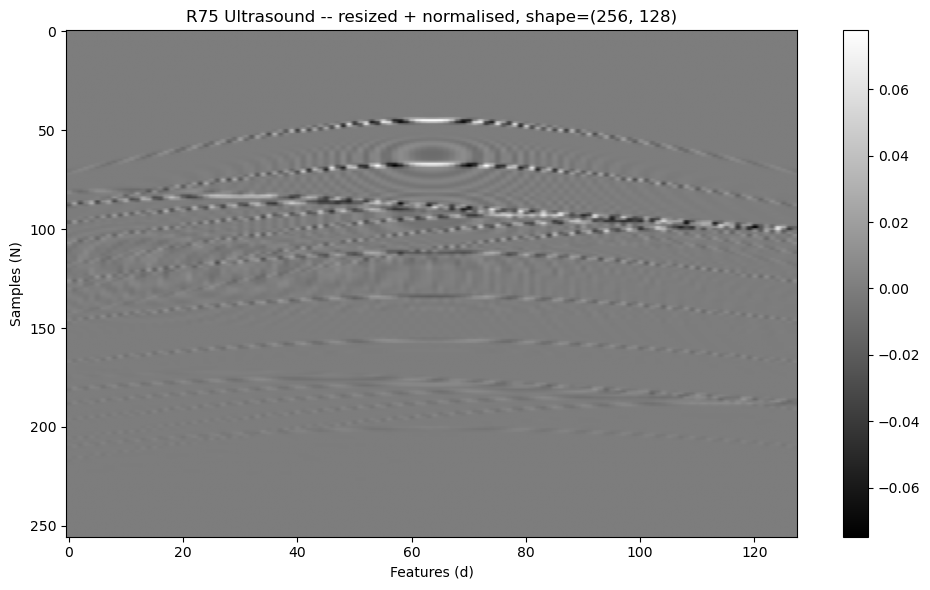

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import resize

df = pd.read_excel('R75 Ultrasound data.xlsx', header=None)
print(f"raw shape: {df.shape}")

Y_np = resize(df.to_numpy(), (256, 128), anti_aliasing=True)
print(f"resized: {Y_np.shape}")
Y = Y_np / np.linalg.norm(Y_np)
print(f"normalised: ||Y|| = {np.linalg.norm(Y):.6f}")

fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(Y, aspect='auto', cmap='gray')
ax.set_title(f'R75 Ultrasound -- resized + normalised, shape={Y.shape}')
ax.set_xlabel('Features (d)'); ax.set_ylabel('Samples (N)')
plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

In [27]:
#HERE SET THE TARGET
v = Y.T[60]
print(f"flat vector: shape={v.shape}, norm={np.linalg.norm(v):.6f}")
print(f"  2^15 = {2**15}, matches 256*128 = {256*128}")
N_QUBITS = 8
ultra_mps = qtn.MatrixProductState.from_dense(
    v.astype(np.complex128),
    dims=[2] * N_QUBITS,
    cutoff=0.0,
)
ultra_mps /= ultra_mps.norm()
print(f"\nMPS: n_qubits={N_QUBITS}, max_bond={ultra_mps.max_bond()}")

ultra_meta = {
    'shape':       Y.shape,
    'flatten':     'Y.T.flatten()',
    'norm':        float(np.linalg.norm(v)),
    'n_qubits':    N_QUBITS,
}
#Number of chi layers 
ULTRA_K_CHI2 = 30
ULTRA_K_CHI4 = 1
ULTRA_K_CHI8 = 1
#Number of iterations per layer for optimiser, cutoff is schimdt coefficient cutoff after each layer to contorl schidt spectra
ULTRA_N_ITER = 200
ULTRA_CUTOFF = 1e-7


WARM_RESULTS = {}
for chi, K_max in [(2, ULTRA_K_CHI2), (4, ULTRA_K_CHI4), (8, ULTRA_K_CHI8)]:
    print(f"\n========== WARM chi={chi} K_max={K_max} ==========")
    res = sequential_disentangle_warm(
        ultra_mps, chi=chi, num_layers=K_max,
        n_iter=ULTRA_N_ITER, verbose=False,
    )
    print(f"  chi_fids: {[f'{v:.4f}' for v in res['chi_fids']]}")
    replay = img_sso_replay_with_cutoff(ultra_mps, res['layers'], chi,
                                          cutoff=ULTRA_CUTOFF)
    print(f"  residual bond per L: {replay['bond_dims']}")
    recon_bonds = reconstruction_bond_growth(
        ultra_mps, res['layers'], replay['gate_infos'], chi, cutoff=ULTRA_CUTOFF,
    )
    print(f"  reconstruction bond per L (0..K): {recon_bonds}")
    WARM_RESULTS[chi] = {
        'sweep':         res,
        'gate_infos':    replay['gate_infos'],
        'bond_dims':     replay['bond_dims'],
        'recon_bonds':   recon_bonds,
    }

flat vector: shape=(256,), norm=0.093241
  2^15 = 32768, matches 256*128 = 32768

MPS: n_qubits=8, max_bond=16

========== WARM chi=2 K_max=30 ==========


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(
C:\Users\archi\AppData\Local\Temp\ipykernel_6884\3344678349.py:1425: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:837.)
  init_loss = float(loss_fn(warm_layer, init_tn=mps_t))


  chi_fids: ['0.5641', '0.7585', '0.8806', '0.9317', '0.9556', '0.9661', '0.9780', '0.9823', '0.9855', '0.9894', '0.9917', '0.9939', '0.9949', '0.9960', '0.9970', '0.9978', '0.9983', '0.9987', '0.9990', '0.9991', '0.9993', '0.9994', '0.9995', '0.9996', '0.9997', '0.9998', '0.9998', '0.9999', '0.9999', '0.9999', '0.9999']
  residual bond per L: [13, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 15, 16, 16, 15, 16, 16, 15, 16, 15, 15, 15, 15, 16, 16, 15, 15, 15, 15, 15]
  reconstruction bond per L (0..K): [2, 4, 8, 11, 12, 15, 14, 15, 15, 15, 15, 16, 16, 15, 16, 16, 16, 15, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16, 16]

========== WARM chi=4 K_max=1 ==========
  chi_fids: ['0.9180', '0.9981']
  residual bond per L: [13, 16]
  reconstruction bond per L (0..K): [4, 15]

========== WARM chi=8 K_max=1 ==========
  chi_fids: ['0.9990', '1.0000']
  residual bond per L: [13, 8]
  reconstruction bond per L (0..K): [8, 13]


# Same, but with SSO (Josh Green)

In [1]:
import quimb.tensor as qtn
import quimb as qu
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from math import cos, sin, pi
from autoray import do
from scipy.linalg import qr, null_space
from typing import Dict, List, Tuple, Optional
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from collections import Counter
import autoray as ar
import jax.numpy as jnp
from skimage import data
from skimage.transform import resize
from scipy.stats import unitary_group
#import geoopt
#import geotorch
import math
import torch
import torch.nn as nn
from torch.nn.utils import parametrize

from functools import partial

'''This is the contraction method for the tensor networks ie For all future tensor contractions, automatically search for a high-quality contraction path (using a slower but smarter optimizer), so that contractions run efficiently on large networks '''
qtn.set_contract_strategy('auto-hq')

import mps_to_circuit as mtc
from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator


''' This allows us to get the information from the qiskit circuit '''
def get_qiskit_gate_info(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for ci in qc.data:                      # ci is a CircuitInstruction
        instr = ci.operation                # was: instr
        qargs = ci.qubits                   # was: qargs
        qubits = [qc.find_bit(q).index for q in qargs]

        try:
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")

    return gates


'''Ensures the indicies of the TN are lrp'''
def ensure_mps_shape_lrp(mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Return a copy of `mps` whose site tensors have a consistent axis order:
      - interior sites: (vL, vR, p)
      - left edge:      (vR, p)
      - right edge:     (vL, p)

    This is the default 'lrp' format used by quimb.
    """
    mps = mps.copy()
    N = mps.L

    for i in range(N):
        T = mps[i]
        p = mps.site_ind(i)
        # all non-physical indices on this site
        virt = [ix for ix in T.inds if ix != p]

        if i == 0:
            # left edge: single virtual = vR
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vR = virt[0]
            T.transpose(vR, p, inplace=True)

        elif i == N - 1:
            # right edge: single virtual = vL
            assert len(virt) == 1, f"Site {i} expected 1 virtual leg, found {len(virt)}."
            vL = virt[0]
            T.transpose(vL, p, inplace=True)

        else:
            # interior: two virtuals; identify left vs right by neighbor sharing
            assert len(virt) == 2, f"Site {i} expected 2 virtual legs, found {len(virt)}."
            left_neighbor_inds = set(mps[i - 1].inds)
            right_neighbor_inds = set(mps[i + 1].inds)

            # the bond shared with the left/right neighbor
            vL = next(ix for ix in virt if ix in left_neighbor_inds)
            vR = next(ix for ix in virt if ix in right_neighbor_inds)

            T.transpose(vL, vR, p, inplace=True)

    return mps


'''Make the circuit in qiskit then map to quimb'''
def mps_to_circuit_quimb(mps: qtn.MatrixProductState) -> qtn.Circuit:
    """ Functionality thanks to https://github.com/qiskit-community/mps-to-circuit. MPS must have shape (vL,vR, phys) unless shape is specified. """
    
    psi = ensure_mps_shape_lrp(mps.copy())
    psi.left_canonicalize(inplace=True)

    arrays = [np.asarray(A, dtype=np.complex128) for A in psi.arrays]

    qiskit_qc = mtc.mps_to_circuit(arrays, shape='lrp',method='exact')

    gates_info = get_qiskit_gate_info(qiskit_qc)

    qc = qtn.Circuit(mps.L)
   
    for gate in gates_info:
        name, qubits, U = gate
        qubits.reverse()
        qc.apply_gate(U, *qubits)

    return qc

"""def optimise_to_zero(n: int,eps: float = 1e-2):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    
    to_opt = qc.uni

    targ_qc = qtn.Circuit(n)
    I4 = qu.eye(4)  # two-qubit identity (4×4)
    for i in range(n - 1): targ_qc.apply_gate(I4, i, i + 1, tags=['SU4'])
    targ_uni = targ_qc.uni 

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ_uni},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    #opt_uni = tnopt.optimize_basinhopping(n=600,tol=1e-14,nhop=100)

    params = opt_uni.get_params()

    return params"""


'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_identity(eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(np.eye(4).reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    return params


'''Gives the paramters of a complete unity circuit not just a gate'''
def optimise_to_zero(n: int,eps: float = 1e-2):
    params = optimise_su4_gate_to_identity(eps=eps)[2]
        
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params


'''Gives the parameterised identity circ'''
def near_zero_parametrized_circ_layer(n: int, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised near-identity """

    #params = optimise_to_zero(n)
    params = GLOBAL_IDENTITY_LAYER_PARAMS ###--what is this????
    qc = qtn.Circuit(n)
    #for idx in range(n-1):
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc

'''Using the optimised identity params this becomes an idenity circuit layer'''
def parametrized_circ_layer(n: int, params: np.ndarray, eps: float = 1e-3):
    """ Create a single-layer SU(4) parametrised quantum circuit, initialised with params. """
    qc = qtn.Circuit(n)
    for idx, base in zip(range(n - 1), params.values()):
        base = np.asarray(base, dtype=float).reshape(15)
        qc.apply_gate("SU4",*(base+eps*np.random.standard_normal(size=(15))),idx,idx+1,tags=["SU4"],parametrize=True)
    return qc


'''Computes the Schmidt coefficients (or their squares, i.e. entanglement spectrum) for a bipartition of a quantum state, given the left and right Gram matrices'''
'''def schmidt_from_gram(L,R,square: bool = True, cut_zeros: bool = True) -> torch.Tensor:
    L = (L + L.conj().T) / 2
    R = (R + R.conj().T) / 2

    # 2) eigensqrt of L
    w, U = torch.linalg.eigh(L)
    w = torch.clip(w, 0, None)
    Lh = (U * torch.sqrt(w)[None, :]) @ U.conj().T

    # 3) build A and solve
    A = Lh @ R @ Lh
    A = (A + A.conj().T) / 2
    mu = torch.linalg.eigvalsh(A)
    mu = torch.clip(mu.real, 0, None)

    # Schmidt coefficients
    s = torch.sqrt(mu).flip(0)

    if square:
        s = s**2

    if cut_zeros:
        s = s[s > 1e-14]
        
    return s'''
import torch
from typing import Tuple, Optional

def schmidt_from_gram(
    L: torch.Tensor,
    R: torch.Tensor,
    square: bool = True,
    cut_zeros: bool = True,
    *,
    eps_abs: float = 1e-16,
    eps_rel: float = 1e-12,
    cond_limit: float = 1e10,
    jitter: float = 1e-8,
    return_info: bool = False,
) -> torch.Tensor:
    """
    Compute Schmidt coefficients from Gram matrices L, R in a numerically robust way.

    L, R: (..., N, N) complex or real tensors. Supports batching.
    eps_abs: absolute minimum eigenvalue (very tiny floor).
    eps_rel: relative floor as a fraction of the max eigenvalue per matrix.
    cond_limit: maximum allowed condition number ~ max_eig / min_allowed_eig.
                If cond_limit is finite, min_allowed_eig = max(max_eig/cond_limit, eps_rel*max_eig, eps_abs)
    jitter: extra additive jitter to the diagonal (useful to force PD for cholesky; typically 0).
    return_info: if True returns (s, info_dict) where info_dict contains diagnostics.

    Returns:
      s: Schmidt coefficients (descending), optionally squared if square=True and filtered if cut_zeros=True.
    """
    # 0) basic checks and symmetrize
    if L.shape[-2] != L.shape[-1] or R.shape[-2] != R.shape[-1]:
        raise ValueError("L and R must be square matrices (..., N, N).")
    if L.shape[-2] != R.shape[-2]:
        raise ValueError("L and R must be same size.")
    if not torch.isfinite(L).all() or not torch.isfinite(R).all():
        raise ValueError("L or R contains NaN/Inf.")
    
    # Hermitize (works for complex data too)
    herm = lambda X: (X + X.conj().transpose(-2, -1)) / 2
    L = herm(L)
    R = herm(R)

    # Optionally add tiny jitter first (keeps reconstruction stable)
    if jitter > 0:
        N = L.shape[-1]
        eye = torch.eye(N, device=L.device, dtype=L.dtype)
        L = L + jitter * eye

    # eigendecompose L
    # PREVIOUS 06/11
    '''w, U = torch.linalg.eigh(L)   # w: (..., N) ascending order by torch convention

    # diagnostics
    max_w = w.amax(dim=-1, keepdim=True)   # (..., 1)
    max_w_safe = torch.clamp(max_w, min=1e-30)  # avoid divide-by-zero
    # compute allowed minimum eigenvalue per matrix (batched)
    min_allowed = torch.maximum(
        torch.full_like(max_w_safe, eps_abs),
        torch.maximum(eps_rel * max_w_safe, max_w_safe / cond_limit)
    )  # (..., 1)

    # clamp eigenvalues (relative threshold)
    w_clamped = torch.clamp(w, min=min_allowed.squeeze(-1))

    # optional info
    num_clamped = (w < w_clamped).to(torch.int64).sum(dim=-1)  # count per batch
    frac_clamped = num_clamped.to(torch.get_default_dtype()) / w.shape[-1]

    # build sqrt(L) = U diag(sqrt(w_clamped)) U^†
    sqrt_w = torch.sqrt(w_clamped)
    # broadcasting: (.., N) -> (.., 1, N) for left-multiplication on U
    Lh = (U * sqrt_w.unsqueeze(-2)) @ U.conj().transpose(-2, -1)


    # construct A and symmetrize
    A = Lh @ R @ Lh
    A = herm(A)'''

    # ----- NEW: Cholesky-based "square root" (no eigenvectors; phase-safe) -----
    # We already hermitized L above and added optional jitter.
    # Make sure L is PD enough for Cholesky by adapting jitter if needed.
    def chol_with_adaptive_jitter(M: torch.Tensor, base_jitter: float):
        N = M.shape[-1]
        eye = torch.eye(N, device=M.device, dtype=M.dtype)
        jitter = base_jitter
        for _ in range(6):  # try a few times, up to ~1e-6 if starting at 1e-12
            try:
                return torch.linalg.cholesky(M + (jitter * eye)), jitter
            except RuntimeError:
                jitter = max(jitter * 10.0, 1e-12) if jitter > 0 else 1e-12
        # final attempt with cholesky_ex to get info
        C, info = torch.linalg.cholesky_ex(M + (jitter * eye))
        if (info > 0).any():
            raise RuntimeError("Cholesky failed: L not PD even after jitter.")
        return C, jitter

    C, used_jitter = chol_with_adaptive_jitter(L, jitter)

    # Build A = C^H R C (Hermitian if R is Hermitian); this is
    # unitarily similar to L^{1/2} R L^{1/2} so it has the same eigenvalues.
    A = C.conj().transpose(-2, -1) @ R @ C
    A = (A + A.conj().transpose(-2, -1)) / 2  # re-hermitize numerically

    # eigenvalues of A (real, ascending)
    mu = torch.linalg.eigvalsh(A)
    # numerical safety: clamp small negatives to zero
    mu = torch.clip(mu.real, 0.0, None)

    # Schmidt coefficients: sqrt(mu) in descending order
    s = torch.sqrt(mu).flip(-1)

    if square:
        s = s**2

    if cut_zeros:
        # flatten last dimension and cut tiny entries
        # we'll return per-batch concatenated tensors, so handle batch case by converting to list
        out_list = []
        if s.ndim == 1:
            out_list = [s[s > 1e-14]]
        else:
            # batch handling: return a list of 1D tensors (one per batch)
            # but to keep same return type as before (tensor) we'll concatenate if batch size == 1,
            # otherwise return list if multiple batches (safer).
            batch_shape = s.shape[:-1]
            s_reshaped = s.reshape(-1, s.shape[-1])  # (B, N)
            for row in s_reshaped:
                out_list.append(row[row > 1e-14])
            if s_reshaped.shape[0] == 1:
                s = out_list[0]
            else:
                # when multiple batches present, return a list of tensors (doable) or pad to rectangular array.
                # Here we return a list for explicitness.
                if return_info:
                    info = {
                        "num_clamped": num_clamped,
                        "frac_clamped": frac_clamped,
                        "w_max": max_w.squeeze(-1),
                        "min_allowed": min_allowed.squeeze(-1),
                    }
                    return out_list, info
                return out_list

    if return_info:
        info = {
            "num_clamped": num_clamped,
            "frac_clamped": frac_clamped,
            "w_max": max_w.squeeze(-1),
            "min_allowed": min_allowed.squeeze(-1),
        }
        return s, info

    return s


'''Contruct the left and right contracted tensors so we are only looking at the required bypartition'''
def construct_L_R_Gram_matrices(tn: qtn.TensorNetwork, ind: str, *, device=None, dtype=None) -> qtn.TensorNetwork:
    """ Construct L_a,a' and R_a,a' Gram matrices. """
    ket = tn.copy()
    bra = ket.copy().conj()
    bra.reindex_({i: i + '_bra' for i in bra._inner_inds})

    comb = (bra|ket)

    #Find relevant tags of border tensors
    tidL, tidR = comb.ind_map[ind]
    L_tag = [tag for tag in comb.tensor_map[tidL].tags if tag.startswith('I')]
    R_tag = [tag for tag in comb.tensor_map[tidR].tags if tag.startswith('I')]
    if len(L_tag)!=1 or len(R_tag)!=1:
        print(comb)
        print(L_tag)
        print(R_tag)
    assert len(L_tag)==1 and len(R_tag)==1, "Tensors in combined TN should have unique identifying tag"
    L_tag = L_tag[0]
    R_tag = R_tag[0]

    L_tag_id = int(str(L_tag[1:]))
    R_tag_id = int(str(R_tag[1:]))

    L_tag = f'I{min(L_tag_id,R_tag_id)}'
    R_tag = f'I{max(L_tag_id,R_tag_id)}'
    assert R_tag_id > L_tag_id, "Right border unique tag should be greater than the left border unique tag"

    L_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])<=L_tag_id]
            
    R_tags = [tag for T in comb
              for tag in T.tags 
              if isinstance(tag,str) and tag.startswith('I') and int(tag[1:])>=R_tag_id]
    
    #Form subnetworks and contract
    L_subnetwork = comb.select(L_tags,which='any')
    R_subnetwork = comb.select(R_tags,which='any')

    output_inds = (ind, ind+'_bra')
    L_contracted = L_subnetwork.contract(all,output_inds=output_inds,backend='torch')
    R_contracted = R_subnetwork.contract(all,output_inds=output_inds,backend='torch')

    L_mat = L_contracted.data
    R_mat = R_contracted.data

    return L_mat, R_mat


'''Cumulated the above two functions as to find the scmidt coeffs'''
'''def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    s = schmidt_from_gram(L_mat,R_mat)
    return s'''

def schmidt_coeffs_from_ind(tn: qtn.TensorNetwork, ind:str):
    L_mat,R_mat = construct_L_R_Gram_matrices(tn,ind)
    # 2) Compute Schmidt coefficients using safe numerical parameters
    s = schmidt_from_gram(
        L_mat,
        R_mat,
        square=True,
        cut_zeros=True,
        eps_abs=1e-16,     # absolute floor
        eps_rel=1e-12,     # relative floor
        cond_limit=1e10,   # cap condition number
        jitter=1e-12,      # tiny diagonal regularization
        return_info=False, # only return s
    )
    return s



'''Is the code to apply the circuit to the mps ie does the contractions'''
def apply_single_layer(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState, gauge: bool = False) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    #print(new)
    #print(new.outer_inds())
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)

    for t in new:
        site_ind_idx = int([ind for ind in t.inds if ind.startswith('b')][0][1:])
        t.modify(tags = (f'I{site_ind_idx}'))

    if gauge:
        new.gauge_all(method='simple',inplace=True)
    
    """to_split = new.tensors[-1]
    num_phys = [i for i in to_split.inds if i.startswith('b')]
    if len(num_phys)>1:
        left_phys_idx = new.L-2
        virt = [i for i in to_split.inds if not i.startswith('b')][0]
        TL,TR = to_split.split(
            left_inds=(f'b{left_phys_idx}',virt),
            right_inds=(f'b{left_phys_idx+1}'),
            method='svd',
            absorb='both'
        )

        TL.add_tag(f"I{left_phys_idx}")
        TR.drop_tags()
        TR.add_tag(f"I{left_phys_idx+1}")
        new = qtn.TensorNetwork([new.tensors[:-1],TL,TR])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='b{}',site_tag_id='I{}',cyclic=False)"""

    return new
    #return ensure_mps_shape_lrp(new)

'''This is the same functinality as the above but might do it in a slightly differnt way'''
def apply_single_layer_to_mps(circ_tn: qtn.TensorNetwork, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """
    Apply a single layer of 2-qubit unitaries to evolve an MPS.
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)

    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    bL = f'b{mps.L-2}'
    bR = f'b{mps.L-1}'
    T = next(T for T in new.tensors if bL in T.inds and bR in T.inds)
    virt, = [ind for ind in T.inds if ind not in (bL,bR)]
    
    kept = []
    for t in new:
        if bL not in t.inds and bR not in t.inds:
            kept.append(t)
    
    TL,TR = T.split(
        left_inds=(bL,virt),
        right_inds=(bR,),
        method='svd',
        absorb='right'
    )
    
    ordered_list = []
    idx = 0
    while idx < mps.L:
        for t in kept+[TL,TR]:
            for ind in t.inds:
                if ind[0]=='b':
                    id = int(ind[1:])
                    if idx == id:
                        ordered_list.append(t)
                        break
        idx+=1

    new = qtn.TensorNetwork(ordered_list)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    
    for idx,t in enumerate(new):
        t.modify(tags=(f"I{idx}"))        
        if t.ndim==3:
            if f'k{new.L-2}' in t.inds:
                a,b,c = t.inds
                new_ind_ordering = (b,c,a)
                t.transpose(*new_ind_ordering, inplace=True)
            else:
                a,b,c = t.inds
                new_ind_ordering = (c,b,a)
                t.transpose(*new_ind_ordering, inplace=True)

    return new

def ordered_mps(tn: qtn.MatrixProductState):
    tn = tn.copy()
    tensors = []
    num_added = 0
    while num_added < tn.L:
        for t in tn:
            if f'k{num_added}' in t.inds:
                tensors.append(t)
                num_added+=1
                if f'k{num_added}' in t.inds:
                    num_added+=1
                break
    new = qtn.TensorNetwork(tensors)
    new.view_as(qtn.MatrixProductState, inplace=True, L=tn.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
    return new


'''This applies the adjoint of the circuit we give to the mps'''
def apply_single_layer_to_mps(circ_tn: qtn.Circuit, mps: qtn.MatrixProductState) -> qtn.MatrixProductState:
    """ 
    
    Contract a circuit layer MPO with an MPS, reshaping it into an MPS form.

    Provide the circuit for which the adjoint is applied.
    
    """
    mps = mps.copy()
    circ_tn = circ_tn.copy()

    #circ_tn.reindex({f'b{x}': f't{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f'k{x}': f'b{x}' for x in range(mps.L)},inplace=True)
    #circ_tn.reindex({f't{x}': f'k{x}' for x in range(mps.L)},inplace=True)

    new = circ_tn | mps

    shared = qtn.bonds(circ_tn, mps)
    for ix in shared:
        new.contract_ind(ix)
    new.fuse_multibonds(inplace=True)

    new.reindex({f'b{x}': f'k{x}' for x in range(mps.L)},inplace=True)
    new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)

    if new.max_bond()==1:
        return new
    
    new.full_simplify(seq='ADCR',atol=0.0,inplace=True)
    
    new = ordered_mps(new)
    
    current_idx = 0
    last_tensor_inds = ()
    while current_idx < new.L:
        T = new.tensors[current_idx].copy()

        phys_inds = np.array([i for i in T.inds if i[0]=='k'])

        if len(phys_inds) == 1:
            last_tensor_inds = T.inds
            current_idx+=1 
            continue

        current_phys = f'k{current_idx}'
        left_inds = [i for i in T.inds if i in last_tensor_inds]
        left_inds = tuple(left_inds + [current_phys])

        if current_idx == mps.L-2:
            left_inds = tuple([i for i in T.inds if i != f'k{current_idx+1}'])
        
        right_inds = tuple([i for i in T.inds if i not in left_inds])
        
        #print(f'current phys = {current_phys}. left inds = {left_inds}. right inds = {right_inds}. All inds = {T.inds}. Prev inds = {last_tensor_inds}.')
        TL,TR = qtn.tensor_split(T, left_inds=left_inds, method='svd', absorb='left', cutoff=1e-14)

        new = qtn.TensorNetwork(new.tensors[:current_idx] + (TL,TR) + new.tensors[current_idx+1:])
        new.view_as(qtn.MatrixProductState, inplace=True, L=mps.L, site_ind_id='k{}',site_tag_id='I{}',cyclic=False)
                
        last_tensor_inds = left_inds
        current_idx+=1

    for t in new:
        for i in t.inds:
            if i[0]=='k':
                idx = i[1:]
        t.modify(tags = {f'I{idx}'})

    new.compress(cutoff=1e-16)
    new.left_canonicalize(inplace=True)

    new_inds = (new.tensors[-1].inds[1],new.tensors[-1].inds[0])
    new.tensors[-1].transpose(*new_inds,inplace=True)
    new = ensure_mps_shape_lrp(new)

    return new


'''THis functions shows the fidelity of a chi = bond approximation of the MPS'''
def test_bond_accuracy(tn,bond):
    tn = tn.copy()
    x = tn.copy()
    x.compress(max_bond=bond)
    x/=x.norm()
    return abs((x.conj() | (tn / tn.norm())).contract(all))**2


'''ALLL BELOW ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''This function defines the loss function for the optimisation of layers, op = circuit, intit_tn = intial mps'''
'''def torch_schmidt_loss_fn(op: qtn.TensorNetwork, init_tn: qtn.MatrixProductState, target_bond_dim: int = 1, gamma: float = 4.0, alpha: float = 0.2) -> torch.Tensor:
    """
    C(lambda) = sum(w_i*lambda_i) + alpha (1 - sum(lambda_i^2)) + beta * RELU(m - (lambda_D - lambda_(D+1))) = tail mass + alpha*linear entropy + beta*gap penalty. w_i = (i-D)^gamma. D = target_bond_dim.
    """
    init_tn = init_tn.copy()
    op = op.copy()
    #op.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)#here we contact the mps with the circuit
    
    vals = []
    for ind in new_tn.inner_inds():
        schmidt_coeffs = schmidt_coeffs_from_ind(new_tn,ind)

        tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
        idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
        weights = idx**gamma

        C_tail_mass = (weights * tail).sum()
        #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

        loss = C_tail_mass #+ alpha*C_lin_entropy
        vals.append(loss)

    vals = torch.stack(vals)

    return vals.sum()'''

'''This is the entanglement as the loss function'''
'''def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = torch.finfo(torch.float64).tiny  # ~2e-308
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0
        p = p / (p.sum() + eps)                                        # normalize
        Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0:
            Tj = 1.0 - (p[0] + p[1] + p[2] + p[3]) ###FIND ME HERE #Immediate compressibility proxy
            Cj = (1.0-g)*Sj + g*Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum() 

import math'''

def torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.0
) -> torch.Tensor:
    """
    Net entanglement loss = sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = (lambda_i)^2 / sum_k (lambda_k)^2
    Optional: + alpha * (1 - sum_i p_i^2) per cut (linear entropy smoothing).
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    eps = 1e-12
    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)   # λ_i ≥ 0, p_i =  λ_i^2
        
        d = p.numel()
        if d== 0:
            continue
        p = torch.clamp(p, min=0.0)

        p = p / p.sum()

        # --- Entropy (use change-of-base to avoid log2 instability under AMP) ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        
        #ADDED NORMALISATION
        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max #normalise in [0,1] 

        #Sj = -(p * torch.log2(p.clamp_min(1e-12))).sum()               # bits

        if g > 0.0: #1-(p_1^2+p_2^2) 
            #print(len(p))
            #print(p.numel())
            topk = min(2, p.numel())
            Tj = 1.0 - p.narrow(0, 0, topk).sum()
            Cj = (1.0 - g) * Sj + g * Tj
        else:
            Cj = Sj

        vals.append(Cj)
    vals = torch.stack(vals)
    return vals.sum()

def new_torch_schmidt_loss_fn(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    g: float = 0.5,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-parameter loss aligned with final chi=2 fidelity.

    For each internal bond, let p be the normalised Schmidt probabilities
    (lambda^2 / sum lambda^2), sorted in descending order.

      T_j      = 1 - (p_1 + p_2)                   # tail mass (chi=2 infidelity)
      r_i      = p_i / T_j for i >= 3             # tail distribution (if T_j > 0)
      H_tail   = -sum_{i>=3} r_i log2 r_i         # entropy of tail
      H_tail_n = H_tail / log2(d_tail) in [0,1]   # d_tail = len(tail), if >= 2

    Per-cut cost:
      C_j(g) = T_j * (1 + g * H_tail_n)

    - T_j drives you towards high chi=2 fidelity.
    - H_tail_n only cares about *how messy the tail is*.
    - g in [0,1] controls how much you value "cleaning up / structuring the tail"
      vs purely greedy chi=2.

    When T_j -> 0, C_j -> 0 regardless of H_tail_n, so late stages are effectively greedy.
    """
    # clamp g to [0, 1]
    #g = float(max(0.0, min(1.0, g)))

    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ^2 already
        lam2 = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if lam2.numel() == 0:
            continue

        lam2 = torch.clamp(lam2, min=0.0)
        Z = lam2.sum()
        if Z <= eps:
            continue

        p = lam2 / Z  # probabilities

        # sort so top entries are really the largest
        p_sorted, _ = torch.sort(p, descending=True)
        d = p_sorted.numel()

        if d <= 2:
            # no tail -> already rank<=2 across this cut
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        # chi=2 tail mass
        topk = 2
        Tj = 1.0 - p_sorted[:topk].sum()

        if Tj <= eps:
            # effectively no tail, cost ~ 0
            vals.append(torch.tensor(0.0, dtype=torch.float64, device=p.device))
            continue

        tail = p_sorted[topk:]          # shape (d_tail,)
        d_tail = tail.numel()

        if d_tail <= 1:
            # a single tail mode still present: no entropy structure
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            # tail distribution r_i = p_i / T_j
            r = tail / Tj
            r = torch.clamp(r, min=eps)

            H_tail = - (r * (r.log() / math.log(2.0))).sum()
            H_max = math.log2(d_tail)
            H_tail_norm = H_tail / H_max

        # multiplicative planning: penalise large & messy tails
        Cj = Tj * (1.0 + g * H_tail_norm)
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)
    #if np.random.randint(0,200)==0:
    #   print(f'Tj = {Tj}, H_tail_n = {H_tail_norm}, Cj = {Cj}')
    vals = torch.stack(vals)
    return vals.sum()


def loss_renyi2_sum(op, init_tn):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    total = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        total = total - torch.log2((p*p).sum().clamp_min(1e-300))  # Σ_j S2^(j)
    return total

def loss_smoothmax_entropy(op, init_tn, tau=0.1):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        S = -(p * torch.log2(p.clamp_min(1e-12))).sum()
        vals.append(S)
    vals = torch.stack(vals)
    return tau * torch.logsumexp(vals / tau, dim=0)

def loss_weighted_tail(op, init_tn, D=4, gamma=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    tot = 0.0
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        tail = p[D:]
        if tail.numel():
            idx = torch.arange(1, tail.numel()+1, dtype=tail.dtype, device=tail.device)
            w = idx**gamma                     # gamma↑ => weight deeper tail more
            tot = tot + (w * tail).sum()
    return tot

def loss_effective_rank(op, init_tn, target_R=None, beta=1.0):
    new = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)
    vals = []
    for ind in new.inner_inds():
        p = schmidt_coeffs_from_ind(new, ind).to(torch.float64)
        p = p / (p.sum() + 1e-300)
        R = 1.0 / (p*p).sum().clamp_min(1e-300)
        vals.append(torch.log2(R))  # ≡ S2
        if target_R is not None:    # optional hinge to keep R below target
            vals.append(beta * torch.relu(torch.log2(R) - torch.log2(torch.tensor(target_R))))
    return torch.stack(vals).sum()



def cost_from_s(schmidt_coeffs):
    target_bond_dim = 2
    gamma = 4

    tail = schmidt_coeffs[target_bond_dim:] #/ torch.sum(schmidt_coeffs[target_bond_dim:])
    idx = torch.arange(1, tail.numel()+1, device=schmidt_coeffs.device, dtype=schmidt_coeffs.dtype)
    weights = idx**gamma

    C_tail_mass = (weights * tail).sum()
    #C_lin_entropy = 1.0 - (schmidt_coeffs**2).sum()

    loss = C_tail_mass #+ alpha*C_lin_entropy
    return loss

'''ALLL ABOVE ARE SOME LOSS FUNCTION EXAMPLES******************************************'''

'''Turns Torch backend to numpy backend'''
def to_numpy(a):
    # Works for both torch and numpy inputs
    if isinstance(a, torch.Tensor):
        return a.detach().cpu().numpy()
    return np.asarray(a)


def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        d = p.numel()
        if d== 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        # Entropy in bits: S_j
        Sj = - (p * (p.log() / math.log(2.0))).sum()

        #if d>1:
        #    S_max = math.log2(d)
        #    Sj = Sj / S_max
        vals.append(Sj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()

def torch_schmidt_entropy_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    g = 0 part: sum_j S^{(j)}, where
      S^{(j)} = -sum_i p_i^{(j)} log2 p_i^{(j)},  p_i = λ_i^2 / sum_k λ_k^2

    Additionally (for diagnostics), prints the *normalised tail entropy* per cut,
    where the tail is everything beyond the top-2 Schmidt probabilities,
    and also prints a single scalar "new tail entropy term" = sum_j H_tail_n^{(j)}.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    entropies = []
    tail_entropies = []

    for ind in new_tn.inner_inds():
        # p are λ^2 already
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)
        d = p.numel()
        if d == 0:
            continue

        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z  # probabilities

        # --- Net entropy S_j over full spectrum ---
        Sj = - (p * (p.log() / math.log(2.0))).sum()
        entropies.append(Sj)

        # --- Tail entropy part (for printing only) ---
        # Sort so "top-2" really means largest 2
        p_sorted, _ = torch.sort(p, descending=True)
        d_sorted = p_sorted.numel()

        if d_sorted <= 2:
            # no tail beyond chi=2
            H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
        else:
            topk = 2
            Tj = 1.0 - p_sorted[:topk].sum()  # tail mass
            if Tj <= eps:
                H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
            else:
                tail = p_sorted[topk:]
                d_tail = tail.numel()
                if d_tail <= 1:
                    H_tail_norm = torch.tensor(0.0, dtype=torch.float64, device=p.device)
                else:
                    r = tail / Tj  # tail distribution
                    r = torch.clamp(r, min=eps)
                    H_tail = - (r * (r.log() / math.log(2.0))).sum()
                    H_max = math.log2(d_tail)
                    H_tail_norm = H_tail / H_max

        tail_entropies.append(H_tail_norm)

    if not entropies:
        print("No internal bonds found; tail entropy = []")
        return torch.tensor(0.0, dtype=torch.float64)

    entropies = torch.stack(entropies)
    tail_entropies = torch.stack(tail_entropies)

    # --- print the tail entropy diagnostics ---
    print("Tail entropy (normalised) per cut:",
          tail_entropies.detach().cpu().numpy())

    new_tail_entropy_term = tail_entropies.sum().item()
    print("New tail entropy term =", new_tail_entropy_term)

    return entropies.sum()



def torch_schmidt_tail_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    topk: int = 2,
) -> torch.Tensor:
    """
    g = 1 part: sum_j T^{(j)}, where
      T^{(j)} = 1 - sum_{i=1}^{topk} p_i^{(j)},
    with p_i as in the entropy loss.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        p = torch.clamp(p, min=0.0)
        p = p / p.sum()

        k = min(topk, p.numel())
        Tj = 1.0 - p.narrow(0, 0, k).sum()
        vals.append(Tj)

    vals = torch.stack(vals)
    print(vals)
    return vals.sum()


def torch_schmidt_kl_rank2_loss(
    op: qtn.TensorNetwork,
    init_tn: qtn.MatrixProductState,
    alpha: float = 1e-3,
    eps: float = 1e-12,
) -> torch.Tensor:
    """
    Single-term planning-friendly cost.

    For each internal bond, let p be the normalised Schmidt probabilities.
    Define a smoothed rank-2 target spectrum q:
        q_1 = q_2 = (1 - alpha)/2,
        q_i (i>=3) share total mass = alpha.

    Loss = sum_j D_KL(p^{(j)} || q^{(j)}).

    This consolidates:
      - entropy reduction (concentration of p),
      - tail suppression (penalising mass where q_i is tiny),
    into a single divergence to the 'ideal' chi=2 spectrum.
    """
    init_tn = init_tn.copy()
    op = op.copy()

    # Apply one optimisation layer
    new_tn = apply_single_layer(circ_tn=op, mps=init_tn, gauge=False)

    vals = []
    for ind in new_tn.inner_inds():
        # λ_i >= 0  -> convert to probabilities
        p = schmidt_coeffs_from_ind(new_tn, ind).to(torch.float64)

        if p.numel() == 0:
            continue

        # Numerical hygiene
        p = torch.clamp(p, min=0.0)
        Z = p.sum()
        if Z <= eps:
            continue
        p = p / Z

        d = p.numel()

        # Build target q
        if d <= 2:
            # If there is no tail, just aim for equal split
            q = torch.full_like(p, 0.5)
        else:
            tail_mass = float(alpha)
            tail_mass = max(min(tail_mass, 0.5), 0.0)  # safety clip

            q_top = (1.0 - tail_mass) / 2.0
            q_tail = tail_mass / float(d - 2)

            q = torch.full_like(p, q_tail)
            q[0] = q_top
            q[1] = q_top

        # Clamp for log stability
        p_safe = torch.clamp(p, min=eps)
        q_safe = torch.clamp(q, min=eps)

        # KL(p || q) in nats (constant factor doesn't matter for optimisation)
        Cj = (p_safe * (p_safe.log() - q_safe.log())).sum()
        vals.append(Cj)

    if not vals:
        return torch.tensor(0.0, dtype=torch.float64)

    vals = torch.stack(vals)
    return vals.sum()


'''THIS IS THE OPTIMISATION for a layer%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%'''
def optimise_circ_layer(init_mps: qtn.TensorNetwork, loss = torch_schmidt_loss_fn, verbose: bool = False, get_best_result: bool = True, gauge_iteratively: bool = False) -> qtn.TensorNetwork:
    init_mps = init_mps.copy()
    #init_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    
    
    circ = near_zero_parametrized_circ_layer(init_mps.L,1e-3)#intitialise our ciruit at identity
    layer = circ.uni #turn into tensor network form
    layer.apply_to_arrays(lambda x: torch.as_tensor(x)) #make sure torch backend
    to_opt = layer.copy()

    #new_tn = apply_single_layer(circ_tn=to_opt.copy(), mps=init_mps.copy(), gauge=False)
    #print('new mps outcome:')
    #t1 = new_tn.copy()
    #print(t1.contract(all,output_inds=[f'b{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
    #new_tn.draw(figsize=(15,15))
    #t = new_tn.tensors[-1]
    #t.add_tag("I7")
    """print(new_tn)
    for idx,ind in enumerate(new_tn.inner_inds()):
        print(f'ind: {ind} - {schmidt_coeffs_from_ind(new_tn.copy(),ind)}')
        #if idx < len(new_tn.inner_inds())-3:
        #    print(f'check: {new_tn.copy().schmidt_values(idx+1)}')
        print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(new_tn.copy(),ind))}')"""

    #init_mps.left_canonicalize(inplace=True,normalize=True)

    if verbose:
        with torch.no_grad():
            print(f'initial loss = {loss(to_opt,init_mps)}')

    if get_best_result: #essentially we are looking for the best parameters if this is true
        if verbose:
            print('Ensuring best parameters are retrieved...')

        _best = {"val": None, "params": None}

        with torch.no_grad():
            best_val = loss(to_opt,init_tn=init_mps)
        
        _best["val"] = best_val
        
        '''if this iteration is the best store the parameters and continue returing psi as it was inputted'''
        def get_best(psi):
            #global best_val,best_params
            with torch.no_grad():
                val = loss(psi,init_tn=init_mps)
            if val<_best["val"]:
                tn_np = psi.copy()
                tn_np.apply_to_arrays(to_numpy)
                _best["params"] = tn_np.get_params()
                _best["val"] = val
            return psi
        
        def get_best_fn(psi):
            with torch.no_grad():#Ensures that the operations inside do not track gradients in PyTorch ie does this outside the optimisation
                _ = get_best(psi.copy())#makes a separate copy of the tensor network so the bookkeeping doesn’t alter the main object.

                if gauge_iteratively:#boolean ie renormalsiation for stability
                    psi.gauge_all(method='simple',inplace=True)#a tensor network normalization/gauge-fixing step.“Simple” method ensures numerical stability of MPS contractions.Done inplace, modifying the original
            return psi

        print(f'At init net entropy comp = {torch_schmidt_entropy_loss(to_opt.copy(),init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(to_opt.copy(),init_mps.copy())}')
        #this is the actual optimisation, note using get best we store the params of the best
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            norm_fn=get_best_fn,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    else:
    #here we dont have norm_fn=get_best_fn, so not storing the best parameters
        tnopt = qtn.TNOptimizer(
            to_opt,
            loss,
            loss_constants={'init_tn': init_mps},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

    #this is the optimised tn
    opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
    x = opt_layer_tn
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))#make sure optimised tn is all torch

    if verbose: #essentially is a boolean to switch on and off the print statements
        with torch.no_grad():
            print(f'final loss = {loss(opt_layer_tn,init_mps)}')

    if get_best_result: #gives the best results ie the best tn layer
        with torch.no_grad():
            print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,init_mps)}')
            best_layer_tn = opt_layer_tn.copy()
            best_layer_tn.set_params(_best["params"])
            best_copy = best_layer_tn.copy()
            best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
            print(f'after updating, final loss = {loss(best_copy,init_mps)}')

            print(f'After opt: net entropy comp = {torch_schmidt_entropy_loss(best_copy,init_mps.copy())} // tail loss = {torch_schmidt_tail_loss(best_copy,init_mps.copy())}')

        return best_layer_tn
    else:
        return opt_layer_tn
    
def find_optimal_chi(schmidts, target_error):
    """
    schmidts: list of 1D arrays of Schmidt coeffs (one per bond)
    target_error: desired upper bound on total discarded weight
    """
    # preprocess: squared, normalised, sorted descending
    spectra = []
    for lam in schmidts:
        lam = np.asarray(lam, dtype=float).ravel()
        lam2 = lam**2
        lam2 /= lam2.sum()
        spectra.append(np.sort(lam2)[::-1])

    max_rank = max(len(s) for s in spectra)

    def global_error(chi):
        # sum of tail weights across all bonds
        err = 0.0
        for lam2 in spectra:
            if chi < len(lam2):
                err += lam2[chi:].sum()
        return err

    lo, hi = 1, max_rank
    while lo < hi:
        mid = (lo + hi) // 2
        if global_error(mid) <= target_error:
            hi = mid
        else:
            lo = mid + 1
    return lo  # minimal chi with error <= target_error

def construct_circ_from_params(param_set,n):
        layers = len(param_set)
        qc = qtn.Circuit(n)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

def reconstruct_circuit(disentangled_mps: qtn.MatrixProductState, param_set: list):
    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    
    circ = construct_circ_from_params(param_set,n=disentangled_mps.L)
    circ_tn = circ.uni.H
    circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'b{x}': f'k{x}' for x in range(disentangled_mps.L)},inplace=True)
    circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(disentangled_mps.L)},inplace=True)
    
    full_circ_tn = circ_tn | final_state.copy()
    
    return full_circ_tn

def test_circuit_fidelity(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list):
    targ_mps = targ_mps.copy()
    targ_mps /= targ_mps.norm()
    disentangled_mps = disentangled_mps.copy()

    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    disentangled_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    full_circ_tn = reconstruct_circuit(disentangled_mps, param_set)
    full_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    full_circ_tn /= full_circ_tn.norm()

    fidelity = np.abs((full_circ_tn.conj() | targ_mps).contract(all))**2
    return fidelity

    '''Collects the above but does it automatically for as many alyers as we need'''
def optimise_sequential_layers(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        #This is THE optimising step, it gets initialised atidenty the nloss function is minimised.
        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        '''if verbose:
            print(f'Testing true fidelity from circuit reconstruction...')
            targ = targ_mps.copy()
            disentangled_state = new_mps.copy()
            targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            fidelity = test_circuit_fidelity(targ, new_mps, param_set)
            print(f'True fidelity after reconstruction = {fidelity}')'''
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        mps_states.append(current_mps)

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2

def subsequent_fid_opt(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5):
    ''' layer by layer (identity-initialised) fidelity maximisation -- to replace with MPD warm-start initialisation'''
    targ_mps = targ_mps.copy()
    targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    targ_mps.left_canonicalize(inplace=True,normalize=True)
    current_mps = targ_mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    targ_mps.reindex({f'k{x}': f'b{x}' for x in range(targ_mps.L)},inplace=True)

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    def chi_upper_bound_from_schmidts(mps, chi):
        bounds = []
        for j in range(1, mps.L):  # cuts between sites
            lam = mps.schmidt_values(j)  # assumes mps is normalized
            lam2 = np.sort(np.asarray(lam)**2)[::-1]
            bounds.append(lam2[:chi].sum())
        return min(bounds), np.array(bounds)
    
    print(chi_upper_bound_from_schmidts(targ_mps.copy(),2))
    uni_layers = []
    param_set = []
    mps_states = []

    if verbose:
        print('doing subsequent fidelity maximising')
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        ind = targ_mps.inner_inds()[mid_idx]
        
        #print(f'Central schmidt coefficients = {targ_mps.schmidt_values(mid_idx+1)}')
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

        targ_mps.gauge_all(method='simple',inplace=True)
        t = targ_mps.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')


    bond2 = [test_bond_accuracy(targ_mps,2)]

    current_state = qtn.MPS_computational_state('0'*targ_mps.L)
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = psi | current_state
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')
        
        current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

        current_state.reindex({f'b{x}': f'k{x}' for x in range(current_state.L)},inplace=True)
        current_state/=current_state.norm()

        to_opt = near_zero_parametrized_circ_layer(n=targ_mps.L, eps = 1e-2)
        to_opt = to_opt.uni

        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        #targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.float64))
        #print(to_opt.dtype)
        #print(targ_mps.dtype)
        #print(targ_mps.dtype)
        #test = (to_opt | current_state)
        #test.draw(figsize=(10,10))

        #targ_mps.draw(figsize=(10,10))
        print(f'init = {torch_infidelity(to_opt.copy(),targ_mps.copy(),current_state.copy())}')
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            #norm_fn=get_best_fn,
            loss_constants={'targ': targ_mps.copy(), 'current_state': current_state.copy()},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
        #print(opt_layer_tn.get_params())
        opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

        current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
        #current_state.gauge_all(method='simple',inplace=True)
        current_state.right_canonicalize(inplace=True,normalize=True)
        current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)
        #print(current_state.norm())
        #print(targ_mps.norm())
        if verbose:
            print(f'fidelity after layer {L} = {np.abs((current_state.copy().conj()/current_state.norm() | targ_mps.copy()/targ_mps.norm()).contract(all))**2}')

        t = current_state.copy()
        t.compress(max_bond=2)
        t/=t.norm()
        print(f'chi2 fid = {np.abs((t.copy().conj() | current_state.copy()).contract(all))**2}')

        #t = targ_mps.copy()
        #t.compress(max_bond=2)
        #t/=t.norm()
        #print(f'chi2 fid of targ = {np.abs((t.copy().conj() | targ_mps.copy()).contract(all))**2}')

        print(f'new max bond = {current_state.max_bond()}')
        #print(current_state)
        mid_idx = int(current_state.L//2)
        ind = current_state.inner_inds()[mid_idx]
        print(f'2. Central schmidt coefficients of updated state = {schmidt_coeffs_from_ind(current_state.copy(),ind)}')
        
    return None

'''Convert a Matrix Product State into a sequence of trainable 2-qubit SU(4) gates'''#WHY????
def mps_to_su4_layer_params(mps: qtn.MatrixProductState):
    mps_copy = mps.copy()
    n = mps_copy.L

    param_set = []

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        #psi = uni | zero
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    circ = mps_to_circuit_quimb(mps_copy)

    for gate_idx in range(n-1):
        gate_tensor = circ.uni.select(f"GATE_{gate_idx}").tensors[0].copy()
        ### NEED TO CHECK GATE INDEX ORDERING HERE...
        gate_tensor.modify(inds=('k0','k1','b0','b1'),inplace=True)
        qc = qtn.Circuit(2,gate_contract=False)
        qc.apply_gate("SU4",*(1e-2*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)#makes random gates with parameters

        to_opt = qc.uni
        tnopt = qtn.TNOptimizer(
            to_opt,
            torch_infidelity,
            loss_constants={'targ': gate_tensor},
            tags=['SU4'],
            optimizer='l-bfgs-b',
            autodiff_backend='torch',
            progbar=True,
        )

        opt_uni = tnopt.optimize(n=600,tol=1e-14)
        params = opt_uni.get_params()
        param_set.append(params)

    return param_set

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation

    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params

def global_optimise(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False, optimise_final_layer: bool = False):
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()#need disentangled mps as it doesnt neccessarily train to the zero product state
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
    #final_state.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    def loss(uni: qtn.TensorNetwork, targ: qtn.TensorNetwork, final_state: qtn.TensorNetwork) -> torch.Tensor:
        psi = uni | final_state.copy()
        ov   = psi.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = psi.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    

    '''These getbest functions are the same as the single layer optimisation'''
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy,final_state=final_state.copy())
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
        return psi
    
    """if optimise_final_layer:
        param_dict = mps_to_su4_layer_params(final_state)
        for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                if len(p)==15:
                    p = np.asarray(p, dtype=float).reshape(15)
                    qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)"""

    #make layers
    def construct_circ(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc
    
    circ = construct_circ(param_set)
    to_opt = circ.uni.H
    to_opt.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))

    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        print('Drawing circuit...')
        circ.draw(figsize=(12,12))

    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    
    for t in to_opt:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Initial tensors are not unitary!"

    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy,'final_state': final_state.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    #opt_layer_tn = tnopt.optimize_basinhopping(n=300,tol=1e-14,lr=0.5,nhop=2)
    opt_layer_tn = tnopt.optimize(n=600,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy,final_state=final_state.copy())}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy,final_state=final_state.copy())}')

    for t in best_copy:
        u = t.data.reshape(4,4)
        assert np.allclose(u.conj().T@u,np.eye(4),atol=1e-6), "Final tensors are not unitary!"
    
    return best_layer_tn

# save.py
import pickle, gzip, sys, datetime


'''Converts any PyTorch tensor to a CPU tensor detached from autograd.

Why?

Ensures saved tensors don’t carry GPU context or gradient history.

Makes them loadable on any machine, even without GPU.'''
def save_run(path, mps_states, param_set, fids):
    # (optional) move any tensors to CPU so loading works anywhere
    def _to_cpu(x):
        return x.detach().cpu() if isinstance(x, torch.Tensor) else x

    mps_cpu = []
    for m in mps_states:
        try:
            m = m.copy().apply_to_arrays(_to_cpu)  # works for quimb TNs
        except Exception:
            pass
        mps_cpu.append(m)

    bundle = {
        "mps_states": mps_cpu,
        "param_set": param_set,
        "fids": fids,
        "meta": {
            "saved_at": datetime.datetime.now().isoformat(),
            "python": sys.version.split()[0],
            "torch": getattr(torch, "__version__", None),
            "quimb": getattr(qu, "__version__", None),
        },
    }
    with gzip.open(path, "wb") as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)


'''Opens a compressed pickle file.

Loads the saved MPS states, parameters, fidelities, and metadata.

Returns them as separate variables ready to use.'''
def load_run(path):
    with gzip.open(path, "rb") as f:
        bundle = pickle.load(f)
    return bundle["mps_states"], bundle["param_set"], bundle["fids"], bundle.get("meta", {})

'''Returns a list of N dictionaries, each mapping gate indices to small random 15-element arrays.

Typical use: initializing tensor network gate parameters before global optimization. ie essentially makes sure the paramtetrs are small for global opt'''
def near_zero_param_dict(n: int, N:int, eps: float = 1e-3, seed: int | None = None, dtype=float) -> dict[int, np.ndarray]:
    """
    Return {i: near-zero np.array(shape=(15,))} for i in 0..n-1.
    Values are sampled uniformly from [-eps, eps].
    To use for the generation of empty params for global opt.
    """
    rng = np.random.default_rng(seed)
    param_set = []
    for j in range(N):
        param_set.append({i: rng.uniform(-eps, eps, 15) for i in range(n-1)})
    return param_set


'''specific state simulation ie common example'''
def generate_haar_random_mps(n: int, num_layers: int, *, seed: int = None):
    """Generate an MPS by stacking `num_layers` of nearest-neighbour Haar-random two-qubit unitaries."""

    if seed is not None:
        qu.gen.rand.seed_rand(seed)

    mps_state = qtn.MPS_computational_state('0' * n)

    for _ in range(num_layers):
        qc = qtn.Circuit(n, gate_contract=False)
        for idx in range(n - 1):
            U = qu.rand_uni(4)  # Haar on U(4); global phase vs SU(4) is irrelevant
            qc.apply_gate(U, idx, idx + 1, tags=["SU4"])
        circ_tn = qc.uni
        mps_state = apply_single_layer_to_mps(circ_tn, mps_state)

    return mps_state

def lrp_to_lpr(final_state):
    for i in range(final_state.L):
        if i == 0:
            inds = final_state.tensors[i].inds
            bond, phys = inds[0], inds[1]
            final_state.tensors[i].transpose(phys,bond,inplace = True)
        if i!=0 and i!=final_state.L-1:
            inds = final_state.tensors[i].inds
            bond1,bond2, phys = inds[0], inds[1], inds[2]
            final_state.tensors[i].transpose(bond1,phys,bond2,inplace = True)
    return final_state

'''This function with parameterise our 4 by 4 gates and train them from random to a unitary tensor'''
def optimise_su4_gate_to_generalU(U,eps: float = 1e-2):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14)

    params = opt_uni.get_params()

    ### simple check that we created the right unitary 
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    print((opt_uni.conj()|targ1).contract())

    return params
import numpy as np
import quimb.tensor as qtn


def _complete_to_unitary(M, tol=1e-12):
    """
    Complete a partial 4x4 isometry (some columns possibly zero)
    to a full 4x4 unitary by Gram–Schmidt, keeping existing
    non-zero columns fixed (up to normalization).
    """
    M = np.asarray(M, dtype=complex)
    d, d2 = M.shape
    assert d == 4 and d2 == 4

    cols = []
    filled = []
    # normalize non-zero columns, leave zeros marked
    for j in range(4):
        col = M[:, j]
        n = np.linalg.norm(col)
        if n > tol:
            cols.append(col / n)
            filled.append(True)
        else:
            cols.append(None)
            filled.append(False)

    # existing orthonormal basis (assume input isometry so already orthogonal)
    basis = [c for c in cols if c is not None]

    rng = np.random.default_rng()
    # add extra basis vectors until we span C^4
    while len(basis) < 4:
        v = rng.normal(size=4) + 1j * rng.normal(size=4)
        for b in basis:
            v -= np.vdot(b, v) * b
        n = np.linalg.norm(v)
        if n < tol:
            continue
        basis.append(v / n)

    # rebuild full unitary, preserving existing columns' directions
    U = np.zeros_like(M, dtype=complex)
    k = 0
    # first assign basis vectors to existing filled columns
    for j in range(4):
        if filled[j]:
            U[:, j] = basis[k]
            k += 1
    # then fill the empty columns
    for j in range(4):
        if not filled[j]:
            U[:, j] = basis[k]
            k += 1

    return U


def embed_tensor_in_SU4(U):
    """
    Embed a tensor U into a 2-qubit SU(4) unitary.

    Conventions:
      - If len(U.inds) == 2 and 'k0' in U.inds:
            boundary tensor with inds (r, p), shape (2, 2)
        -> treated as a map from a 1-d input subspace to (r, p) outputs.
      - If len(U.inds) == 2 and 'k0' not in U.inds:
            boundary tensor with inds (l, p), shape (2, 2)
        -> l is input, p is output; r is fixed (unused).
      - If len(U.inds) == 3:
            bulk tensor with inds (l, r, p), shape (2, 2, 2)
        -> l indices are input; r and p indices are output.

    Returns:
      qtn.Tensor with inds ('k0', 'k1', 'b0', 'b1')
      where ('k0','k1') are input indices and ('b0','b1') are output indices.
    """
    data = np.asarray(U.data, dtype=complex)
    inds = tuple(U.inds)
    rank = len(inds)

    # Matrix M has rows labelled by (b0, b1) and columns by (k0, k1)
    # i  = 2 * b0 + b1  in {0,...,3}
    # j  = 2 * k0 + k1  in {0,...,3}
    M = np.zeros((4, 4), dtype=complex)

    if rank == 2:
        # boundary tensors, shape (2, 2)
        assert data.shape == (2, 2)
        if 'k0' in inds:
            # Left boundary: inds = (r, p)
            # Embed as a single column for |k0=0, k1=0> (j = 0)
            j = 0
            for r in range(2):
                for p in range(2):
                    i = 2 * r + p          # b0 = r, b1 = p
                    M[i, j] = data[r, p]
        else:
            # Right boundary: inds = (l, p)
            # l is input qubit (mapped to k0), k1 is fixed to 0
            for l in range(2):
                j = 2 * l + 0             # k0 = l, k1 = 0
                for p in range(2):
                    i = 2 * 0 + p         # b0 = 0 (no r), b1 = p
                    M[i, j] = data[l, p]

    elif rank == 3:
        # bulk tensor, shape (l, r, p)
        assert data.shape == (2, 2, 2)
        for l in range(2):
            # input index l -> k0; k1 fixed to 0
            j = 2 * l + 0                 # k0 = l, k1 = 0
            for r in range(2):
                for p in range(2):
                    # outputs r, p -> b0, b1
                    i = 2 * r + p         # b0 = r, b1 = p
                    M[i, j] = data[l, r, p]
    else:
        raise ValueError("U must have 2 or 3 indices (boundary or bulk tensor).")

    # Complete to a full 4x4 unitary
    M = _complete_to_unitary(M)

    # Enforce det = 1 to make it SU(4) rather than just U(4)
    det = np.linalg.det(M)
    phase = np.angle(det)
    M *= np.exp(-1j * phase / 4.0)

    # Reshape to rank-4 tensor with inds ('k0', 'k1', 'b0', 'b1')
    # M is indexed as M[b0,b1; k0,k1]; we want T[k0,k1,b0,b1]
    data_su4 = np.transpose(M.reshape(2, 2, 2, 2), (2, 3, 0, 1))

    return qtn.Tensor(
        data=data_su4,
        inds=('k0', 'k1', 'b0', 'b1'),
        tags=getattr(U, "tags", None),
    )


def optimise_su4_to_tensor(U_tensor: qtn.Tensor,eps:float = 1e-2):
    qc = qtn.Circuit(2)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)
    to_opt = qc.uni
    targ = embed_tensor_in_SU4(U_tensor.copy())
    targ.apply_to_arrays(lambda x: torch.as_tensor(x))

    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    #to_opt.draw(figsize=(10,10))
    #targ.draw(figsize=(10,10))

    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_uni = tnopt.optimize(n=600,tol=1e-14)
    params = opt_uni.get_params()
    return params

def extract_su4_params_from_unitary(unitarylist):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary))
    return paramlist

'''Gives the paramters of a complete unity circuit not just a gate'''
def combine_layer_params_into_param_dict(paramslst: list, n: int):
    qc = qtn.Circuit(n)#,gate_contract=False)
    for idx in range(n-1):
        params = paramslst[idx][2]
        qc.apply_gate("SU4",*(params),idx,idx+1,tags=["SU4"],parametrize=True)
    
    circ_uni = qc.uni
    params = circ_uni.get_params()

    return params

def reindex_su4_tngen(tn):
    """
    Reindex all SU4 tensors in a TensorNetworkGenOperator according to:
        1->3, 2->4, 3->1, 4->2
    Works IN PLACE and preserves circuit structure.
    """
    tn_new = tn.copy()

    for t in tn_new.tensors:
        # Only modify SU4 gates with 4 legs
        if 'SU4' in t.tags and len(t.inds) == 4:
            i0, i1, i2, i3 = t.inds
            new_order = {
                i0: i2,
                i1: i3,
                i2: i0,
                i3: i1
            }
            t.reindex_(new_order)   # <--- in-place reindex

    return tn_new

def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv) 
    exact_mps = qtn.MatrixProductState.from_dense(
        full_sv, 
        dims=[2] * n, 
        cutoff=0.0,
        max_bond=None  # <-- ensures no truncation
    )
    return exact_mps
def exact_to_approx_mps(exact_mps,bond):
    approx_mps = exact_mps.copy()
    approx_mps.compress(max_bond=bond)
    approx_mps.right_canonicalize(normalize=True,inplace=True)
    return approx_mps
def makezeromps(n):
    #try from dense in mps form
    zerovect = np.zeros(2**n)
    zerovect[0] = 1
    zerovect_mps = qtn.MatrixProductState.from_dense(zerovect, dims=[2]*n)
    return zerovect_mps

from qiskit import QuantumCircuit
from qiskit.quantum_info import Operator
'''get gate info from qiskit'''
def extract_gates_with_qubits(qc: QuantumCircuit):
    """
    Given a QuantumCircuit, returns a list of tuples:
    (gate_name, qubit_indices, gate_matrix)
    """
    gates = []
    for instr, qargs, _ in qc.data:
        # Get the qubits this instruction acts on
        qubits = [qc.find_bit(q).index for q in qargs]
        
        try:
            # Get the unitary matrix of the gate itself
            U = Operator(instr).data
            gates.append((instr.name, qubits, U))
        except Exception as e:
            # Skip non-unitary operations (measure, reset, barrier)
            print(f"Skipping {instr.name} on qubits {qubits}: {e}")
    
    return gates


import quimb.tensor as qtn
'''Make our quimb circuit using gate info'''
def makequimbcirc(n, gates_info):
    """
    Rebuild a Quimb Circuit from gates_info
    gates_info = list of (name, qubits, U)
    n = number of qubits
    """
    qc = qtn.Circuit(n)
    
    for gate in gates_info:
        name, qubits, U = gate
        temp = []
        qubits.reverse()
        qc.apply_gate(U, *qubits)
    
    return qc

def param_dict_from_mps(mps: qtn.MatrixProductState):
    psi = ensure_mps_shape_lrp(mps.copy())
    print(psi)
    param_list = []
    for T in psi.tensors:
        params = optimise_su4_to_tensor(T)
        param_list.append(params)
    
    param_dict = combine_layer_params_into_param_dict(param_list,mps.L)
    return param_dict

def optimise_su4_gate_to_generalU(U,eps: float = 1e-2,verbose:bool = False):
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*(eps*np.random.standard_normal(size=(15))),0,1,tags=["SU4"],parametrize=True)

    to_opt = qc.uni #this is the mps version of the circuit to a tn
    targ = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1')) #ie start from identity
    targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128)) #converts numpy array to torch tensor

    #figures out the infidelity
    def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = psi.overlap(targ,backend='torch')               
        npsi = psi.norm(squared=True,backend='torch').real       
        ntar = targ.norm(squared=True,backend='torch').real
        return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

    '''This optimises the identity tn to some target tn ie sets it up - foundation'''
    tnopt = qtn.TNOptimizer(
        to_opt,
        torch_infidelity,
        loss_constants={'targ': targ},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=verbose,
    )

    #print('Finding params to initialise identity layer...')
    opt_uni = tnopt.optimize(n=600,tol=1e-14) #this runs the optimisation
    opt_uni /= opt_uni.norm()
    params = opt_uni.get_params()

    ### simple check that we created the right unitary
    targ1 = qtn.Tensor(U.reshape(2,2,2,2),inds=('k0','k1','b0','b1'))
    targ1 /= targ1.norm()
    #print(f' direct from opt circuit fidel: {np.abs((opt_uni.conj()|targ1).contract())**2}')

    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate("SU4",*params[2],0,1,tags=["SU4"],parametrize=True)
    newqc = qc.uni
    newqc /= qc.uni.norm()
    #print(f' direct from params fidel: {np.abs((newqc.conj()|targ1).contract())**2}')

    #check with unitary in the circuit::
    qc = qtn.Circuit(2)#ie the two means a two qubit register ,,,,,#,gate_contract=False)
    qc.apply_gate(U,0,1)
    newqc1 = qc.uni
    newqc1 /= qc.uni.norm()
    

    #checking indicie ordering
    '''opt_gate = opt_uni[("SU4",)]
    newqc_gate = newqc[("SU4",)]
    print(opt_gate.inds)
    print(newqc1.inds)
    print(newqc_gate.inds)
    print(targ1.inds)'''

    # okay we have found the indicy mapping is not correct for U:
    # after opt_uni created
    best_perm = ('k0','k1','b0','b1')

    mapping = {
        'b0': 'k0',
        'b1': 'k1',
        'k0': 'b0',
        'k1': 'b1',
    }
    #could it be that this remapping mean it has to act backwards to give tthe identity??
    G_fixed = opt_uni['SU4'].reindex(mapping)

    opt_uni['SU4'] = G_fixed

    #print("Fixed fidelity:", abs((opt_uni.conj() | newqc1).contract())**2)


    return params

def extract_su4_params_from_unitary(unitarylist,verbose:bool=False):
    paramlist = []
    for unitary in unitarylist:
        paramlist.append(optimise_su4_gate_to_generalU(unitary,verbose=verbose))
    return paramlist

def project_params_real(tn):
    """Force all parameter tensors to be real float64 (drop imaginary part)."""
    # Grab *all* parameters (in your case they’re the SU4 ones)
    params = tn.get_params()   # <- no 'tags=' kwarg

    new_params = []
    for p in params:
        # ensure torch tensor
        if not torch.is_tensor(p):
            p = torch.as_tensor(p)

        # detach, take real part, cast to float64, and re-enable grad
        pr = p.detach().real.to(torch.float64).requires_grad_()
        new_params.append(pr)

    # Write them back in the same order
    tn.set_params(new_params)  # <- no 'tags=' kwarg
    return tn

def SCS_all(targ_mps: qtn.TensorNetwork, disentangled_mps: qtn.MatrixProductState, param_set: list, verbose: bool = False):
    #Preliminaries: load final disentangled state (disentangled_mps // psi^(L))
    targ_copy = targ_mps.copy()
    targ_copy/=targ_copy.norm()

    final_state = disentangled_mps.copy()
    final_state.compress(max_bond=2)
    final_state/=final_state.norm()
    final_state.apply_to_arrays(lambda x: x.detach().cpu().numpy())

    zero_mps = qtn.MPS_computational_state('0'*targ_copy.L)

    #Map the disentangled state into a QC // psi^(L) = U_L|0>
    reindexed_final_state = lrp_to_lpr(final_state.copy())
    mps_arrays = reindexed_final_state.arrays
    qc = mtc.mps_to_circuit(mps_arrays, shape='lpr',method='exact')
    gates_info = extract_gates_with_qubits(qc)
    qc = makequimbcirc(targ_copy.L,gates_info)
    qctocheck = qc 

    #Absorb extra single qubit-gate into neighbours
    unitaries = []
    for g in qc.gates:
        unitaries.append(g.array)
    U_2q = unitaries[-2]
    U_1q = unitaries[-1]
    I2 = np.eye(2)
    U_new2 = np.kron(U_1q, I2) @ U_2q
    unitaries = unitaries[:-2] + [U_new2]

    #Check that U_L|0> has fidelity 1.0 with psi^(L)
    final_layer_b_ind_in = reindexed_final_state.copy()   
    final_layer_b_ind_in.reindex_({f'k{x}': f'b{x}' for x in range(len(final_layer_b_ind_in.outer_inds()))},inplace=True)
    qc_out = qc.uni | zero_mps
    fidelity_check = np.abs((qc_out.conj() | final_layer_b_ind_in).contract(all))**2
    if verbose:
        print(f'fidelity of the non-parametrised circuit vs chi2 state = {fidelity_check}')

    #Convert QC into parametrised SU4 layer
    paramlist = extract_su4_params_from_unitary(unitaries,verbose=verbose) #General U4 -> SU4 parameterisation
    layer_params = combine_layer_params_into_param_dict(paramlist,targ_copy.L) #Combine into a single dictionary

    def construct_circ_desc(layerparams,n):
        qc = qtn.Circuit(n)  # optionally gate_contract=False
        count = n

        for idx in range(n-1):
            p = layerparams[count]
            p = np.asarray(p, dtype=float).reshape(15)
            # Apply the SU4 gate
            qc.apply_gate("SU4", *(p), n-2-idx, n-1-idx, tags=["SU4"], parametrize=True)
            count += 1
        return qc

    def construct_circ_asc(param_set):
        layers = len(param_set)
        qc = qtn.Circuit(targ_copy.L)

        for L in range(layers):
            param_dict = param_set[L]
            for idx,p in enumerate(param_dict):
                p = param_dict[list(param_dict)[idx]]
                p = np.asarray(p, dtype=float).reshape(15)
                qc.apply_gate("SU4",*(p),idx,idx+1,tags=["SU4"],parametrize=True)

        return qc

    #Check: reconstruct the circuit from parameters
    circ = construct_circ_desc(layer_params,n=targ_mps.L)
    circ_tn = circ.uni
    #ARCHIE TESTING
    print("Archie Testing: should draw here")
    circ.draw()

    #Reindex circ_tn
    final_circ_tn = reindex_su4_tngen(circ_tn.copy()) 

    #Check fidelity of output state
    final_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    zero_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    parametrized_final_layer_applied = final_circ_tn.copy() | zero_mps.copy()
    parametrized_final_layer_applied/=parametrized_final_layer_applied.norm()

    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    qc_out.apply_to_arrays(lambda x: torch.as_tensor(x))
    final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        print(f'Fidelity of param circ with pre-param = {np.abs((parametrized_final_layer_applied.copy().conj() | qc_out.copy()).contract(all)**2)}')
        print(f'Fidelity of param circ with final_layer = {np.abs((parametrized_final_layer_applied.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    #At this stage, output indices of output_mps are b{x}

    #Set up optimisation requirements
    def loss(applied_uni: qtn.TensorNetwork, targ: qtn.TensorNetwork) -> torch.Tensor:
        ov   = applied_uni.overlap(targ.copy(),backend='torch')                # <targ|psi>
        npsi = applied_uni.norm(squared=True,backend='torch').to(torch.float64)           # ||psi||^2
        ntar = targ.norm(squared=True,backend='torch').to(torch.float64)          # ||targ||^2
        loss = 1 - (torch.abs(ov) ** 2) / (npsi * ntar)        
        return loss.to(torch.float64)

    _best = {"val": None, "params": None}
    _best["val"] = torch.inf
    
    def get_best(psi):
        with torch.no_grad():
            val = loss(psi,targ=targ_copy)
        if val<_best["val"]:
            tn_np = psi.copy()
            tn_np.apply_to_arrays(to_numpy)
            _best["params"] = tn_np.get_params()
            _best["val"] = val
        return psi
    
    def get_best_fn(psi):
        with torch.no_grad():
            _ = get_best(psi.copy())
            #project_params_real(psi)
        return psi

    #Convert parameter set into quantum circuit
    core_circ = construct_circ_asc(param_set)

    #We've prepared the backward circuit --> reverse + take its adjoint for state preparation
    core_circ_tn = core_circ.uni.conj() 
    core_circ_tn.reindex({f'k{x}': f'tmp{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'b{x}': f'k{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'tmp{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.apply_to_arrays(lambda x: torch.as_tensor(x))
    #Now outputs are b{x} and inputs are k{x}

    #We must invert b->k in target MPS indices to append it to the output end of the circuit TN
    targ_copy.reindex({f'k{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

    #Test that core circ is constructed properly
    if verbose:
        print(final_state.outer_inds())
        combined_core = core_circ_tn.copy() | final_state.copy()
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x))
        combined_core.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(combined_core.copy(),targ_copy.copy())}')

    #Reindex final layer to append it to the start (via z-index connection)
    #targ_copy.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    core_circ_tn.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    parametrized_final_layer_applied.reindex({f'b{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)

    #print('drawing param final layer')
    #parametrized_final_layer_applied.draw(figsize=(15,15))

    #Append final layer MPS
    parametrized_final_layer_applied.apply_to_arrays(lambda x: torch.as_tensor(x))
    to_opt = core_circ_tn.copy() | parametrized_final_layer_applied.copy() #output indices are k{x}
    #to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
    targ_copy.reindex({f'k{x}': f'z{x}' for x in range(targ_copy.L)},inplace=True)
    #targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    if verbose:
        test_tn = parametrized_final_layer_applied.copy()
        test_tn.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)
        test_tn.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        final_layer_b_ind_in.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Fidelity of param final circ with final layer = {np.abs((test_tn.copy().conj() | final_layer_b_ind_in.copy()).contract(all)**2)}')

    '''print(f'param final layer:')
    parametrized_final_layer_applied.draw(figsize=(20,20))
    print(f'core circ tn:')
    core_circ_tn.draw(figsize=(20,20))
    print(f'combined:')
    to_opt.draw(figsize=(20,20))
    print(to_opt)
    print(to_opt.outer_inds())'''
    #print(loss(to_opt, targ_copy))

    #Another test
    """if verbose:
        print('combined core:')
        combined_core.draw(figsize=(20,20))
        print(combined_core)
        print(f'combined with param:')
        to_opt.draw(figsize=(20,20))
        print(to_opt)

        test = to_opt.copy()
        test/=test.norm()
        test.reindex({f'b{x}': f'int{x}' for x in range(targ_copy.L)},inplace=True)
        test.reindex({f'z{x}': f'b{x}' for x in range(targ_copy.L)},inplace=True)

        ip = (test.conj() | combined_core.copy()/combined_core.norm())
        ip.draw(figsize=(20,20))
        
        print(f'Fidelity of constructed states = {np.abs(ip.contract(all)**2)}')"""


    #Test that core circ is combined with parametrized version of final layer correctly
    if verbose:
        comb = to_opt.copy() | targ_copy.copy()
        #comb.draw(figsize=(20,20))
        to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
        targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        print(f'Loss using final state = {loss(to_opt.copy(),targ_copy.copy())}')

    to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))#,dtype=torch.complex128))
    targ_copy.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))#,dtype=torch.complex128))

    #to_opt.draw(figsize=(20,20))
    tnopt = qtn.TNOptimizer(
        to_opt,
        loss,
        norm_fn=get_best_fn,
        loss_constants={'targ': targ_copy.copy()},
        tags=['SU4'],
        optimizer='l-bfgs-b',
        autodiff_backend='torch',
        progbar=True,
    )

    opt_layer_tn = tnopt.optimize(n=500,tol=1e-14,lr=0.5)
    opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

    if verbose:
        opt_layer_tn.draw(figsize=(20,20))
        print(f'params = {opt_layer_tn.get_params()}')
    print(f'best val = {_best["val"]}. Final loss = {loss(opt_layer_tn,targ_copy)}')
    best_layer_tn = opt_layer_tn.copy()
    best_layer_tn.set_params(_best["params"])
    best_copy = best_layer_tn.copy()
    best_copy.apply_to_arrays(lambda x: torch.as_tensor(x))
    print(f'after updating, final loss = {loss(best_copy,targ_copy)}')

    return best_layer_tn


In [2]:
#My various functions needed to run when starting up
def schmidt_analysis(targ_mps):
        targ_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
        print("MPS ENTANGLEMENT ANALYSIS: ")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        schmidt=schmidt_coeffs_from_ind(targ_mps,ind)
        print(f'Central schmidt coefficients (first 128)')
        # Convert to numpy for matplotlib
        s = schmidt.numpy()[:128]

        plt.figure(figsize=(6,4))
        plt.semilogy(s, marker='o')
        plt.title("Schmidt Coefficients (log scale)")
        plt.xlabel("Index")
        plt.ylabel("Value")
        plt.grid(True, which='both')  # grid on major + minor ticks
        plt.tight_layout()
        plt.show()
        
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')
def approx_state_to_image(approx_state,height,width):
    """
    Takes an approx state tensor network, and reshapes and shows image.
    """
    extracted_vector=approx_state.contract(all).data.detach().numpy().reshape(-1)
    img_size=height*width
    #unpads and puts the norm in to swap from complex to real
    extracted_vector_unpadded=np.abs(extracted_vector[:img_size])
    plt.imshow(extracted_vector_unpadded.reshape(height,width), cmap='gray')   # `cmap='gray'` for black/white images
    plt.axis('off')                # Optional: hide axis ticks
    plt.show()
    
def get_image_results(approx_states,fids,height,width):
    #create target state from an image file
    for i in range(len(approx_states)):
        print("LAYER ",i)
        print("Fidelity is: ",fids[i])
        approx_state_to_image(approx_states[i],height,width)
def pad_to_next_power_of_two(vec, pad_value=0):
    """
    Pads a 1D NumPy array to the next power of 2 in length.

    Parameters
    ----------
    vec : np.ndarray
        1D input array to pad
    pad_value : number, optional
        Value to pad with (default 0)

    Returns
    -------
    np.ndarray
        Padded array with length equal to next power of 2
    """
    if vec.ndim != 1:
        raise ValueError("Input vector must be 1D")

    L = len(vec)
    # Compute next power of 2 >= L
    next_pow2 = 1 << (L - 1).bit_length()  # equivalent to 2**ceil(log2(L))
    pad_amount = next_pow2 - L

    if pad_amount == 0:
        return vec.copy()  # already power of 2

    # np.pad requires an integer pad width
    padded_vec = np.pad(vec, (0, pad_amount), mode='constant', constant_values=pad_value)
    return padded_vec
def image_to_mps(img):
    img_padded = pad_to_next_power_of_two(img.reshape(-1), pad_value=0).astype(float)
    imagempstarget = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
    return imagempstarget
def optimise_sequential_layers_withstates(targ_mps: qtn.TensorNetwork, num_layers: int, loss = torch_schmidt_loss_fn, verbose: bool = False, early_kill_fidelity_thresh: float = None, early_kill_layer_num: int = None, g_vals: list = None, use_new_cost = True, sv_cutoff=1e-5, adaptive_bond_reduction: bool = False, max_truncation_error: bool = 1e-6) -> tuple:
    targ_mps = targ_mps.copy()
    current_mps = targ_mps.copy()
    #Puts the current MPS into a torch compatible object
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

    assert len(GLOBAL_IDENTITY_LAYER_PARAMS) == targ_mps.L-1, "Global identity layer params are not initialised for the right number of qubits."
    
    uni_layers = []
    param_set = []
    mps_states = []
    approx_states = []

    if verbose:
        print("INITIAL STATE")
        mid_idx = int(targ_mps.L//2)
        #Finds the middle index in the MPS, which is needed as the schmidt coefficients over the middle bond characterizes the entanglement of the MPS.
        ind = targ_mps.inner_inds()[mid_idx]
        
        print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(targ_mps,ind)}')
        print(f'Central purity (renyi-2 anti-entropy) = {np.sum(targ_mps.copy().schmidt_values(mid_idx+1)**2)}')
        print(f' bond 2 = {test_bond_accuracy(targ_mps,2)}')
        print(f' bond 4 = {test_bond_accuracy(targ_mps,4)}')
        print(f' bond 6 = {test_bond_accuracy(targ_mps,6)}')

    bond2 = [test_bond_accuracy(targ_mps,2)]
    
    for L in range(num_layers):
        print(f'\n LAYER {L}')

        current_mps.gauge_all(method='simple',inplace=True)

        """print(current_mps)
        t1 = current_mps.copy()
        #print(t1.contract(all,output_inds=[f'k{x}' for x in range(t1.L)]).data.reshape(2**t1.L,1)[:8])
        costs = 0
        for ind in current_mps.inner_inds():
            print(f'ind: {ind} - {schmidt_coeffs_from_ind(current_mps.copy(),ind)}')
            print(f'ind: {ind} - {cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))}')
            costs+=cost_from_s(schmidt_coeffs_from_ind(current_mps.copy(),ind))
        print(f'total cost = {costs}')"""
        if g_vals:
            if use_new_cost:
                loss = partial(new_torch_schmidt_loss_fn, g=g_vals[L])
            else:
                loss = partial(torch_schmidt_loss_fn, g=g_vals[L]) #HERE EDIT
            #loss = partial(torch_schmidt_kl_rank2_loss, alpha=g_vals[L])

        opt_layer_tn = optimise_circ_layer(current_mps,loss=loss,verbose=verbose)

        param_set.append(opt_layer_tn.get_params())
        uni_layers.append(opt_layer_tn)

        opt_layer_copy = opt_layer_tn.copy()
        opt_layer_copy.apply_to_arrays(lambda x: torch.as_tensor(x))

        #if verbose: print(f'double checking final loss = {loss(opt_layer_copy,current_mps.copy())}')

        new_mps = apply_single_layer_to_mps(opt_layer_copy,current_mps)
        
        #OMGGGGG THIS IS THE ONE!!! THIS IS WHAT I NEED TO GET THE IMAGE!!
        print(f'Returning current approx state...')
        targ = targ_mps.copy()
        disentangled_state = new_mps.copy()            
        targ.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        disentangled_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        fidelity = test_circuit_fidelity(targ, new_mps, param_set)
        print(f'True fidelity after reconstruction (should match bond 2) = {fidelity}')
        current_approx_state=reconstruct_circuit(disentangled_state,param_set)
        current_approx_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
        current_approx_state.contract(all)
        current_approx_state/=current_approx_state.norm()
        approx_states.append(current_approx_state)
            
        """for ind in new_mps.inner_inds():
            print(f'ind: {schmidt_coeffs_from_ind(new_mps.copy(),ind)}')
            print(f'ind: {cost_from_s(schmidt_coeffs_from_ind(new_mps.copy(),ind))}')"""

        #new_mps.gauge_all(method='simple',inplace=True)
        max_bond_before = new_mps.max_bond()
        if adaptive_bond_reduction:
            schmidts = []
            copy = new_mps.copy()
            for ind in copy.inner_inds():
                p = schmidt_coeffs_from_ind(copy, ind)
                p_np = p.detach().cpu().numpy()
                schmidts.append(p_np)
            opt_chi = find_optimal_chi(schmidts, max_truncation_error)
        
            new_mps.compress(max_bond=opt_chi)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff adaptively chosen to give chi={opt_chi}')
        else:
            new_mps.compress(cutoff=sv_cutoff)
            print(f' error from singular value truncation ~ {1.0-new_mps.norm()}, cut from max bond {max_bond_before} to {new_mps.max_bond()}. sv cutoff = {sv_cutoff}')
        new_mps/=new_mps.norm()

        print(f' new max bond = {new_mps.max_bond()}')
        
        current_mps = new_mps.copy()
        test = current_mps.copy()
        if verbose:
            print(f'norm = {test.norm()}')
            mid_idx = int(test.L//2)
            ind = test.inner_inds()[mid_idx]
            #print(f'Central schmidt coefficients = {test.schmidt_values(mid_idx+1)}')
            print(f'2. Central schmidt coefficients = {schmidt_coeffs_from_ind(test,ind)}')
            #print(f'Central purity (renyi-2 anti-entropy) = {torch.sum(schmidt_coeffs_from_ind(test,ind))**2}') #np.sum(test.copy().schmidt_values(mid_idx+1)**2)}')
            print(f' bond 2 = {test_bond_accuracy(test,2)}')
            print(f' bond 4 = {test_bond_accuracy(test,4)}')
            print(f' bond 6 = {test_bond_accuracy(test,6)}')

            print(f'optimising for chi=2 approx:')
            #BELOW JUST MAKES A MPS STATE THAT IS THE ZERO STATE, WITH THE SAME NUMBER OF TENSORS AS THE MAX BOND OF THE NEW MPS!!
            #THIS IS CURRENT STATE NOT CURRENT MPS SO CHILL
            current_state = qtn.MPS_computational_state('0'*new_mps.max_bond())
            current_state/=current_state.norm()

            def torch_infidelity(psi: qtn.TensorNetwork, targ: qtn.TensorNetwork, current_state: qtn.TensorNetwork) -> torch.Tensor:
                psi = psi.copy() | current_state.copy()
                #psi.draw()
                ov   = psi.overlap(targ,backend='torch')            
                npsi = psi.norm(squared=True,backend='torch').real       
                ntar = targ.norm(squared=True,backend='torch').real
                #print(ov, npsi, ntar)
                #ov = (targ.copy().conj() | psi | current_state.copy())
                return 1 - (torch.abs(ov) ** 2) / (npsi * ntar)

            to_opt = near_zero_parametrized_circ_layer(n=new_mps.L, eps = 1e-2)
            to_opt = to_opt.uni

            to_opt.apply_to_arrays(lambda x: torch.as_tensor(x))
            x = test.copy()
            x.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))
            current_state.apply_to_arrays(lambda x: torch.as_tensor(x,dtype=torch.complex128))

            x.reindex({f'k{x}': f'b{x}' for x in range(x.L)},inplace=True)

            tnopt = qtn.TNOptimizer(
                to_opt,
                torch_infidelity,
                #norm_fn=get_best_fn,
                loss_constants={'targ': x.copy(), 'current_state': current_state.copy()},
                tags=['SU4'],
                optimizer='l-bfgs-b',
                autodiff_backend='torch',
                progbar=True,
            )

            opt_layer_tn = tnopt.optimize_basinhopping(n=400,tol=1e-14,lr=0.5,nhop=2)#allows us to jump around to try train a bit better
            opt_layer_tn.apply_to_arrays(lambda x: torch.as_tensor(x))

            #current_state = apply_single_layer_to_mps(opt_layer_tn,current_state)
            #current_state.gauge_all(method='simple',inplace=True)
            #current_state.reindex({f'k{x}': f'b{x}' for x in range(current_state.L)},inplace=True)

            #print(f'best chi2 fidelity after opt = {np.abs((current_state.copy().conj()/current_state.norm() | x.copy()/x.norm()).contract(all))**2}')

        bond2.append(test_bond_accuracy(test,2))
        #swapped this to adding a new_mps.copy() 
        mps_states.append(new_mps.copy())

        if early_kill_fidelity_thresh:# if fidelity is good then we kill process
            if L==early_kill_layer_num:
                if(test_bond_accuracy(test,2)<early_kill_fidelity_thresh):
                    return mps_states,param_set,bond2

    #print(f' bond 2 = {test_bond_accuracy(current_mps.copy(),2)}')
    return mps_states,param_set,bond2,approx_states

Loaded R matrix with shape: (382, 128)


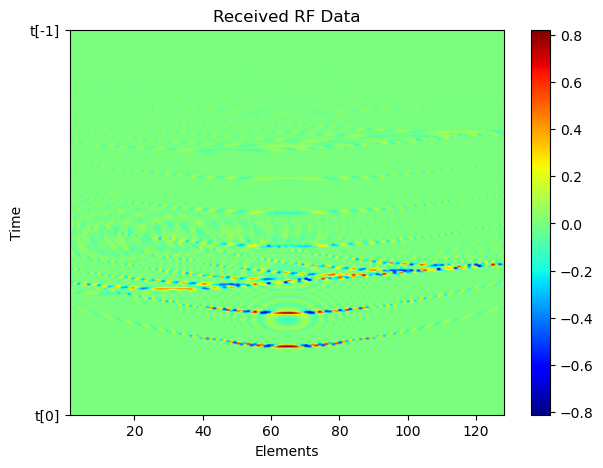

In [3]:
#============================================================
# Load ultrasound RF / R-matrix data from Excel
# Convert to NumPy array for quantum state-prep testing
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ----------------------------
# 1. Load Excel file
# ----------------------------
# IMPORTANT:
# - header=None if the Excel file is purely numeric
# - change filename/path as needed

df = pd.read_excel(
    "R75 Ultrasound data.xlsx",   # <-- your Excel file
    header=None
)

# Convert to NumPy array (this is your R / RF matrix)
R = df.to_numpy(dtype=float)

print("Loaded R matrix with shape:", R.shape)



# ================== Display Received Signals ==================

plt.figure(figsize=(7, 5))
plt.imshow(
    R,
    aspect='auto',
    origin='lower',
    extent=[1, 128, "t[0]", "t[-1]"],
    cmap='jet'
)
plt.colorbar()
plt.xlabel('Elements')
plt.ylabel('Time')
plt.xlim(1, 128)
plt.title('Received RF Data')
plt.show()




Displaying RF_data


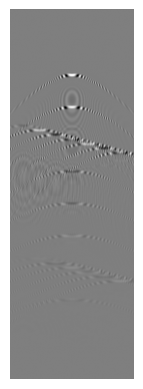

turning to mps and compressing...


In [5]:
print("Displaying RF_data")
# Display it
plt.imshow(R, cmap='gray')   # `cmap='gray'` for black/white images
plt.axis('off')                # Optional: hide axis ticks
plt.show()
img_padded = pad_to_next_power_of_two(R.reshape(-1), pad_value=0).astype(float)
print("turning to mps and compressing...")
R75_data_mps = qtn.MatrixProductState.from_dense(img_padded)/qtn.MatrixProductState.from_dense(img_padded).norm()
R75_data_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))

## Full R75 data with max bond 128

KEY THING TO NOTE HERE (i may be asking this later for paper, we first have to approx to mps to get to a certain fidelity)

In [15]:
target_mps=image_to_mps(R)
test_bond_accuracy(target_mps,128)


np.float64(0.9999903315998394)

In [16]:
target_mps=image_to_mps(R)
target_mps.compress(max_bond=128)
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :  14%|█▍        | 86/600 [00:00<00:04, 117.55it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([1.6327e-01, 8.2432e-02, 6.9314e-02, 6.4013e-02, 5.8702e-02, 5.1889e-02,
        4.6985e-02, 4.3946e-02, 3.6293e-02, 3.2409e-02, 2.7111e-02, 2.4349e-02,
        2.1737e-02, 2.0843e-02, 1.8587e-02, 1.7123e-02, 1.5681e-02, 1.3627e-02,
        1.2104e-02, 1.1651e-02, 1.1323e-02, 1.0204e-02, 9.7824e-03, 9.3507e-03,
        8.3843e-03, 7.4688e-03, 7.4355e-03, 6.6406e-03, 6.0120e-03, 5.6861e-03,
        5.5530e-03, 5.3751e-03, 4.8237e-03, 4.3684e-03, 4.0832e-03, 3.8715e-03,
        3.5738e-03, 3.5043e-03, 3.1806e-03, 2.9090e-03, 2.7412e-03, 2.5409e-03,
        2.5298e-03, 2.3692e-03, 2.1447e-03, 2.0988e-03, 2.0834e-03, 1.9023e-03,
        1.7537e-03, 1.7107e-03, 1.5902e-03, 1.4841e-03, 1.4437e-03, 1.2631e-03,
        1.2016e-03, 1.1812e-03, 1.0376e-03, 1.0002e-03, 8.6762e-04, 8.2063e-04,
        7.5855e-04, 7.0303e-04, 6.3602e-04, 6.2323e-04, 6.0844e-04, 5.5314e-04,
        5.1626e-04, 4.8314e-04, 4.3084e-04, 3.9063e-04, 3.8051e-04, 3.24

  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\scipy\optimize\_basinhopping.py:299: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+6.547281531971 [best: +6.547281531971] : : 1287it [36:23,  1.70s/it]                      


...

+0.668206243557 [best: +0.668204612092] :  89%|████████▉ | 712/800 [04:58<00:36,  2.39it/s]



 LAYER 9
initial loss = 4.695617767213863
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [7.80073507e-01 5.91003406e-05 3.37545413e-01 4.46915583e-01
 4.95221342e-01 5.37322678e-01 5.78445191e-01 6.89123641e-01
 8.33984336e-01 9.21875749e-01 9.53995393e-01 9.64335046e-01
 9.75490941e-01 9.74601782e-01]
New tail entropy term = 9.48898970196798
tensor([2.3685e-12, 1.2555e-02, 5.0351e-02, 1.2870e-01, 2.6458e-01, 4.0760e-01,
        5.0824e-01, 5.6778e-01, 5.8931e-01, 5.7812e-01, 5.4642e-01, 4.7875e-01,
        3.5610e-01, 2.0710e-01], dtype=torch.float64)
At init net entropy comp = 37.18321557727671 // tail loss = 4.695617767213863


+4.648181027365 [best: +4.648179808096] : : 1165it [16:27:04, 50.84s/it]                   


final loss = 4.648181027364686
best val = 4.648179808096405. Final loss = 4.648181027364686
after updating, final loss = 4.648181027364686
Tail entropy (normalised) per cut: [7.40964830e-01 4.52490880e-04 2.81031744e-01 4.55628316e-01
 4.97596779e-01 5.39238298e-01 5.81481401e-01 6.93690142e-01
 8.38706076e-01 9.22214286e-01 9.55600500e-01 9.64805788e-01
 9.75916719e-01 9.74204035e-01]
New tail entropy term = 9.421531405805865
tensor([2.8275e-12, 1.2553e-02, 5.0346e-02, 1.2835e-01, 2.6331e-01, 4.0374e-01,
        5.0208e-01, 5.5781e-01, 5.7962e-01, 5.7392e-01, 5.4020e-01, 4.7419e-01,
        3.5540e-01, 2.0666e-01], dtype=torch.float64)
After opt: net entropy comp = 36.95466482528357 // tail loss = 4.648181027364686
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.34254903112570523
 error from singular value truncation ~ (0.0001539412618658531+2.775984900181346e-17j), cut from max bond 254 to 151. sv cutoff = 0.0001
 new max bond = 151
norm

+0.654946653812 [best: +0.654946622733] : : 878it [05:48,  2.52it/s]                       


In [17]:
# ============================================================
# SAVE THIS RUN  —  full-state SSO, χ=128 bond dim, ~1382 min
# ============================================================
import gzip, pickle, json, sys, datetime
from pathlib import Path
import pandas as pd

# --- clearly describe WHAT this run was ---
RUN_META = {
    "description":      "Full-state SSO encoding of R75 ultrasound (M=1)",
    "encoding":         "full state",
    "n_qubits":         int(target_mps.L),
    "target_bond_chi":  128,            # target_mps.compress(max_bond=128)
    "num_layers":       10,
    "sv_cutoff":        1e-4,
    "loss":             "new_torch_schmidt_loss_fn, g=0  (g_vals=[0]*10)",
    "runtime_minutes":  1382,
    "final_fid_bond2":  float(fids[-1]),
    "saved_at":         datetime.datetime.now().isoformat(timespec="seconds"),
    "torch":            getattr(__import__("torch"), "__version__", None),
}

OUTDIR = Path(r"c:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\SSO results")
OUTDIR.mkdir(exist_ok=True)
STEM = f"fullstate_chi128_L{RUN_META['num_layers']}_{datetime.date.today().isoformat()}"

# --- move any torch arrays to CPU/detached so it loads anywhere (same as save_run) ---
import torch
def _to_cpu(x):
    return x.detach().cpu() if isinstance(x, torch.Tensor) else x
def _clean(states):
    out = []
    for s in states:
        try:    s = s.copy().apply_to_arrays(_to_cpu)
        except Exception: pass
        out.append(s)
    return out

bundle = {
    "meta":          RUN_META,
    "fids":          list(fids),          # bond-2 fidelity: [initial, after L1, ... after L10]
    "param_set":     param_set,           # the circuit params = the actual encoding result
    "mps_states":    _clean(mps_states),
    "approx_states": _clean(approx_states),
}

pkl_path = OUTDIR / f"{STEM}.pkl.gz"
with gzip.open(pkl_path, "wb") as f:
    pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)

# --- tiny human-readable fidelity table (the "pandas thing") ---
df = pd.DataFrame({"layer": range(len(fids)), "fid_bond2": list(fids)})
df["error"] = 1 - df["fid_bond2"]
df.to_csv(OUTDIR / f"{STEM}_fids.csv", index=False)
with open(OUTDIR / f"{STEM}_meta.json", "w") as f:
    json.dump(RUN_META, f, indent=2)

print(f"✅ saved {pkl_path.stat().st_size/1e6:.1f} MB →\n  {pkl_path}\n  {STEM}_fids.csv\n  {STEM}_meta.json")
df


✅ saved 0.0 MB →
  c:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\SSO results\fullstate_chi128_L10_2026-07-24.pkl.gz
  fullstate_chi128_L10_2026-07-24_fids.csv
  fullstate_chi128_L10_2026-07-24_meta.json


,layer,fid_bond2,error
0,0,"tensor(0.1166, dtype=torch.float64)","tensor(0.8834, dtype=torch.float64)"
1,1,"tensor(0.1173, dtype=torch.float64)","tensor(0.8827, dtype=torch.float64)"
2,2,"tensor(0.1783, dtype=torch.float64)","tensor(0.8217, dtype=torch.float64)"
3,3,"tensor(0.2089, dtype=torch.float64)","tensor(0.7911, dtype=torch.float64)"
4,4,"tensor(0.2316, dtype=torch.float64)","tensor(0.7684, dtype=torch.float64)"
5,5,"tensor(0.2452, dtype=torch.float64)","tensor(0.7548, dtype=torch.float64)"
6,6,"tensor(0.2768, dtype=torch.float64)","tensor(0.7232, dtype=torch.float64)"
7,7,"tensor(0.2985, dtype=torch.float64)","tensor(0.7015, dtype=torch.float64)"
8,8,"tensor(0.3157, dtype=torch.float64)","tensor(0.6843, dtype=torch.float64)"
9,9,"tensor(0.3301, dtype=torch.float64)","tensor(0.6699, dtype=torch.float64)"


In [19]:
import gzip, pickle
with gzip.open(r"c:\Users\archi\OneDrive - UWA\2026 (Honours)\MultiRegister Encoding\SSO results\fullstate_chi128_L10_2026-07-24.pkl.gz", "rb") as f:
    bundle = pickle.load(f)
meta          = bundle["meta"]
fids          = bundle["fids"]
param_set     = bundle["param_set"]
mps_states    = bundle["mps_states"]
approx_states = bundle["approx_states"]
print(meta)


{'description': 'Full-state SSO encoding of R75 ultrasound (M=1)', 'encoding': 'full state', 'n_qubits': 16, 'target_bond_chi': 128, 'num_layers': 10, 'sv_cutoff': 0.0001, 'loss': 'new_torch_schmidt_loss_fn, g=0  (g_vals=[0]*10)', 'runtime_minutes': 1382, 'final_fid_bond2': 0.34386934983619766, 'saved_at': '2026-07-24T11:14:06', 'torch': '2.11.0+cpu'}


## Single row with SSO

In [21]:
# Load
df = pd.read_excel("R75 Ultrasound data.xlsx", header=None)
# Resize
Y_np = resize(df.to_numpy(), (256, 128), anti_aliasing=True)
Y=Y_np
Y /=np.linalg.norm(Y)

In [22]:
n = 8
full_sv = Y.T[60]
full_sv = full_sv / np.linalg.norm(full_sv)
exact_mps = dense_to_exact_mps(full_sv, n)

In [24]:
target_mps=exact_mps
target_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128)) # make tensors recognisable by Torch
GLOBAL_IDENTITY_LAYER_PARAMS = optimise_to_zero(target_mps.L) # monkey patch where GLOBAL_IDENTITY_LAYER_PARAMS is defined as a global variable 
#This global variable is used to ensure all SU4 layers begin as identity, unfortunately Quimb using as an ansatz where all params = 0 is not identity
#To be incorporated into functionality when code is cleaned up

loss = partial(new_torch_schmidt_loss_fn, g=0) # defined as a partial because we were testing many different loss functions. Also to be cleaned up

#g_vals = [0]*10 is best here. Also unnecessary functionality that was used for experimentation. Pretty much don't change params here.
#sv_cutoff (use 1e-6 or 1e-7 by default) tunes the Schmidt coefficient truncation threshold. Increasing it makes the truncation more aggressive, keeping bond dimension down and speeding up computations. However, if too aggressive, then this decreases fidelity.
#The outputs are very verbose at the moment. For all intensive purposes, fidelity after L layers is given by bond 2 = ......
mps_states,param_set,fids,approx_states = optimise_sequential_layers_withstates(target_mps.copy(),num_layers=10,verbose=True,loss=loss,g_vals=[0]*10,use_new_cost=True,sv_cutoff=1e-4)

c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


Finding params to initialise identity layer...


+0.000000000000 [best: +0.000000000000] :   8%|▊         | 51/600 [00:00<00:06, 90.37it/s]


INITIAL STATE
2. Central schmidt coefficients = tensor([0.4840, 0.2600, 0.1485, 0.0569, 0.0346, 0.0130, 0.0016, 0.0013],
       dtype=torch.float64)
Central purity (renyi-2 anti-entropy) = 0.3285604197650094
 bond 2 = 0.5640632060496709
 bond 4 = 0.9179551173983664
 bond 6 = 0.988592131439067

 LAYER 0
initial loss = 1.0116334243400318
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.79783523 0.05180782 0.17959857 0.46473847 0.63121509 0.92986895]
New tail entropy term = 3.0550641407940486
tensor([4.7793e-12, 6.8478e-02, 2.2386e-01, 3.2352e-01, 2.5596e-01, 1.3981e-01],
       dtype=torch.float64)
At init net entropy comp = 8.864976118810329 // tail loss = 1.0116334243400318


  0%|          | 0/800 [00:00<?, ?it/s]c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\scipy\optimize\_basinhopping.py:299: OptimizeWarning: Unknown solver options: tol, lr
  return self.minimizer(self.func, x0, **self.kwargs)
+0.495746628877 [best: +0.495746628877] : : 969it [01:01, 15.67it/s]                       


...

+0.010823974516 [best: +0.010823917800] :  55%|█████▌    | 440/800 [01:39<01:21,  4.42it/s]



 LAYER 9
initial loss = 0.035783875363401774
Ensuring best parameters are retrieved...
Tail entropy (normalised) per cut: [0.70341669 0.26038489 0.53445814 0.7930707  0.92246731 0.97101925]
New tail entropy term = 4.18481699395063
tensor([2.3010e-12, 5.6858e-03, 7.6598e-03, 7.9740e-03, 8.2898e-03, 6.1745e-03],
       dtype=torch.float64)
At init net entropy comp = 3.2180036581680267 // tail loss = 0.035783875363401774


+0.027426462858 [best: +0.027426462858] : : 1257it [04:01,  5.20it/s]                      


final loss = 0.031735504591341335
best val = 0.027426462857801703. Final loss = 0.031735504591341335
after updating, final loss = 0.031735504591341335
Tail entropy (normalised) per cut: [0.64729312 0.26085125 0.53286349 0.80885438 0.92698131 0.97203043]
New tail entropy term = 4.148873968833181
tensor([2.7378e-12, 4.3164e-03, 6.5023e-03, 7.0118e-03, 7.7435e-03, 6.1615e-03],
       dtype=torch.float64)
After opt: net entropy comp = 3.339700281756875 // tail loss = 0.031735504591341335
Returning current approx state...
True fidelity after reconstruction (should match bond 2) = 0.9900705922565627
 error from singular value truncation ~ (3.3958192634075957e-05-3.70530204653515e-17j), cut from max bond 16 to 13. sv cutoff = 0.0001
 new max bond = 13
norm = (1+3.899527930921985e-17j)
2. Central schmidt coefficients = tensor([8.6124e-01, 1.3107e-01, 2.1873e-03, 2.0335e-03, 1.4113e-03, 9.5639e-04,
        6.3037e-04, 4.7476e-04], dtype=torch.float64)
 bond 2 = 0.9906548083544031
 bond 4 = 0.99

+0.009343987284 [best: +0.009343984373] :  94%|█████████▍| 752/800 [02:47<00:10,  4.49it/s]


# Josh's Chi2 RAN algorithm functions

In [2]:
import numpy as np
from scipy.linalg import null_space
from sympy import Matrix
from sympy.matrices import GramSchmidt
import quimb.tensor as qtn


In [3]:
def dense_to_exact_mps(full_sv, n):
    full_sv = full_sv / np.linalg.norm(full_sv)
    return qtn.MatrixProductState.from_dense(full_sv, dims=[2]*n)

def exact_to_approx_mps(exact_mps):
    approx = exact_mps.copy()
    approx.compress(max_bond=2)
    approx.right_canonicalize(normalize=True, inplace=True)
    return approx

def makezeromps(n):
    v = np.zeros(2**n); v[0] = 1.0
    return qtn.MatrixProductState.from_dense(v, dims=[2]*n)


In [4]:
def make_unitary_from_2x2(M):
    v = M.reshape(-1)
    v = v / np.linalg.norm(v)
    complement = null_space(v.reshape(1, 4))
    return np.hstack((v.reshape(4, 1), complement))

def tensor_to_unitary(A: qtn.Tensor):
    A_data = A.data.transpose(1, 2, 0).reshape(4, 2)
    null_basis = Matrix(A_data.T).nullspace()
    orth = GramSchmidt(null_basis, orthonormal=True)
    v0 = np.array(orth[0], dtype=float).flatten()
    v1 = np.array(orth[1], dtype=float).flatten()
    U = np.zeros((4, 4), dtype=float)
    U[:, 0] = A_data[:, 0]
    U[:, 1] = v0
    U[:, 2] = A_data[:, 1]
    U[:, 3] = v1
    return U

def makechi2circ(approx_mps, n):
    gates = [make_unitary_from_2x2(approx_mps[0].data)]
    for i in range(1, n - 1):
        gates.append(tensor_to_unitary(approx_mps[i]))
    gates.append(approx_mps[n - 1].data.T)
    qc = qtn.Circuit(n)
    for i in range(n - 1):
        qc.apply_gate(gates[i], i, i + 1)
    qc.apply_gate(gates[n - 1], n - 1)
    return qc.uni


In [5]:
def combinestep(circuittn, exact_mps, n):
    """Apply C† to exact_mps. Returns MPS."""
    working = exact_mps.copy()
    # Rename physical inds to b{x} to match circuit bra indices
    working.reindex_({ind: f'b{x}' for x, ind in enumerate(working.site_inds)}, inplace=True)
    TN = (circuittn | working)
    for x in range(n):
        TN.contract_ind(f'b{x}')
    TN.fuse_multibonds()
    arr = TN.contract(output_inds=[f'k{x}' for x in range(n)])
    dense = np.array(arr.data).flatten()
    dense /= np.linalg.norm(dense)
    return qtn.MatrixProductState.from_dense(dense, dims=[2]*n)

def forward_apply(circuittn, mps, n):
    """Apply C (forward, not dagger) to mps. Returns MPS."""
    # circ | mps contracts k{x} from both, result has b{x} outer
    TN = (circuittn | mps)
    for x in range(n):
        TN.contract_ind(f'k{x}')
    TN.fuse_multibonds()
    arr = TN.contract(output_inds=[f'b{x}' for x in range(n)])
    dense = np.array(arr.data).flatten()
    dense /= np.linalg.norm(dense)
    return qtn.MatrixProductState.from_dense(dense, dims=[2]*n)

def layers_funct(exact_mps, n, L):
    approx_mps = exact_to_approx_mps(exact_mps)
    circs = []
    fidelities = []
    for i in range(L):
        fid = abs((approx_mps | exact_mps).contract())
        fidelities.append(fid)
        print(f'  layer {i+1}: approx fidelity = {fid:.4f}')
        if fid > 1 - 1e-6:
            print(f'  converged at layer {i+1}, stopping.')
            break
        circ = makechi2circ(approx_mps, n)
        exact_mps = combinestep(circ, exact_mps, n)
        approx_mps = exact_to_approx_mps(exact_mps)
        circs.append(circ)
    return circs, fidelities


def rebuildfunc(circs, n):
    mpsbuild = makezeromps(n)
    for circ in reversed(circs):
        mpsbuild = forward_apply(circ, mpsbuild, n)
    return mpsbuild



In [6]:
n = 4
np.random.seed(42)
full_sv = np.random.rand(2**n)
full_sv = full_sv / np.linalg.norm(full_sv)
exact_mps = dense_to_exact_mps(full_sv, n)
final_ref = exact_mps.copy()
approx_mps = exact_to_approx_mps(exact_mps)

print(f"Single-layer approx fidelity: {abs((approx_mps | final_ref).contract()):.4f}")

circs, fids = layers_funct(exact_mps, n, L=5)
rebuilt = rebuildfunc(circs, n)
print(f"Multi-layer rebuilt fidelity:  {abs((rebuilt | final_ref).contract()):.4f}")


Single-layer approx fidelity: 0.9509
  layer 1: approx fidelity = 0.9509
  layer 2: approx fidelity = 0.9969
  layer 3: approx fidelity = 0.9999
  layer 4: approx fidelity = 1.0000
  layer 5: approx fidelity = 1.0000
  converged at layer 5, stopping.
Multi-layer rebuilt fidelity:  1.0000


c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\cotengra\hyperoptimizers\hyper.py:55: UserWarning: Couldn't find `optuna`, `cmaes`, or `nevergrad` so will use completely random sampling in place of hyper-optimization. It is recommended to install one of these libraries for higher quality contraction paths.
  warnings.warn(
c:\Users\archi\miniconda3\envs\phys\Lib\site-packages\quimb\tensor\circuit.py:2587: FutureWarning: In future the tensor network returned by ``circ.uni`` will not be transposed as it is currently, to match the expectation from ``U = circ.uni.to_dense()`` behaving like ``U @ psi``. You can retain this behaviour with ``circ.get_uni(transposed=True)``.
  warnings.warn(


In [7]:
fids

[0.9508835536911165,
 0.9968984548684,
 0.9999155481838083,
 0.9999900079542493,
 0.999999827914639]